In [1]:
import os
import sys
import pickle as pkl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import Phipseq_Sampleset
import seaborn as sns
from statsmodels.stats.multitest import multipletests
from itertools import combinations
import warnings


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
# # Suppress UserWarning only
# # Redirect stderr temporarily
# stderr_fileno = sys.stderr
# sys.stderr = open(os.devnull, 'w')

# import numpy as np
# import scipy
# # warnings.filterwarnings("ignore", category=UserWarning)
# # warnings.filterwarnings("ignore", message="Intel MKL WARNING.*")

In [3]:
# PATH_SAMPLE_SHEET = '/Users/gabrielinnocenti/Desktop/phd_tmp/Sequencing_19_02_24/Template_samplesheet_seq19_02_24.xlsx'
# PATH_DB = '/Users/gabrielinnocenti/Desktop/phd_tmp/phip_seq_DB/phipseq_DB.csv'
PATH_DB = '/Users/gabrielinnocenti/Desktop/phd_tmp/phip_seq_DB/'
# Path to the output folder in which to save the project
PATH_OUTPUT = '/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/Final_output/'
# PATH_SAMPLE_SHEET = '/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/PCa_Innsbruck/Template_samplesheet_Innsbruck.xlsx'
PATH_SAMPLE_SHEET = '/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/Metadata_file.xlsx'
# Path to Agilent library
# PATH_AGILENT_LIB = '/Users/gabrielinnocenti/Desktop/phd_tmp/Sequencing_runs/Sequencing_19_02_24/libraries_metadata/df_info_agilent_final_complete.pkl'
# # Path to Twist library
# PATH_TWIST_LIB = '/Users/gabrielinnocenti/Desktop/phd_tmp/Sequencing_runs/Sequencing_19_02_24/libraries_metadata/final_twist_with_info_and_extra.csv'
# # Path to Corona2 library
# PATH_CORONA2_LIB = '/Users/gabrielinnocenti/Desktop/phd_tmp/Sequencing_runs/Sequencing_19_02_24/libraries_metadata/final_corona2_with_info_and_extra.csv'
# Path to Agilent library
PATH_AGILENT_LIB = '/Users/gabrielinnocenti/Desktop/phd_tmp/Sequencing_runs/Sequencing_19_02_24/libraries_metadata/agilent_library_with_lineages_important_info.csv'
# Path to Twist library
PATH_TWIST_LIB = '/Users/gabrielinnocenti/Desktop/phd_tmp/Sequencing_runs/Sequencing_19_02_24/libraries_metadata/twist_library_with_lineages_important_info.csv'
# Path to Corona2 library
PATH_CORONA2_LIB = '/Users/gabrielinnocenti/Desktop/phd_tmp/Sequencing_runs/Sequencing_19_02_24/libraries_metadata/corona2_library_with_lineages_important_info.csv'
# Load Metadata folder
METADATA = '/Users/gabrielinnocenti/Desktop/phd_tmp/Metadata/'



In [4]:
PATH_AGILENT_LIB_OLD = '/Users/gabrielinnocenti/Desktop/phd_tmp/Sequencing_runs/Sequencing_19_02_24/libraries_metadata/df_info_agilent_final_complete.pkl'
PATH_TWIST_LIB_OLD = '/Users/gabrielinnocenti/Desktop/phd_tmp/Sequencing_runs/Sequencing_19_02_24/libraries_metadata/final_twist_with_info_and_extra.csv'


agilent_lib_old = pkl.load(open(PATH_AGILENT_LIB_OLD, 'rb')).reset_index()
twist_lib_old = pd.read_csv(PATH_TWIST_LIB_OLD)
twist_lib_old.rename(columns={'Unnamed: 0' : 'peptide_name'}, inplace = True)
twist_lib_old['peptide_name'] = twist_lib_old['peptide_name'].apply(lambda x: f'twist_{str(x)}')
prot_to_pept = pd.read_csv("/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/pept_to_prot_agilent_twist.csv")

twist_lib_old = pd.merge(twist_lib_old, prot_to_pept[['Peptide', 'full_aa_seq']], left_on='peptide_name', right_on='Peptide', how='left')

# Modify the full names in vfdb annotated genes
agilent_lib_old_vfdb = agilent_lib_old[agilent_lib_old['is_toxin'] == True].copy()
agilent_lib_old_vfdb['vfdb_complete_name'] = agilent_lib_old_vfdb['full name']
agilent_lib_old_vfdb['short_name'] = (
                agilent_lib_old_vfdb['vfdb_complete_name']
                .str.extract(r'\([^)]*\)\s*\(([^)]*)\)')[0]
            )
agilent_lib_old_vfdb['long_name'] = (
    agilent_lib_old_vfdb['vfdb_complete_name']
    .str.extract(r'\)\s*\([^)]*\)\s*(.*?)\s*\[')[0]
)
agilent_lib_old_vfdb['custom_name'] = (
    agilent_lib_old_vfdb["long_name"].fillna("")
    + " ("
    + agilent_lib_old_vfdb["short_name"].fillna("")
    + ")"
)

agilent_lib_old_vfdb[['peptide_name', 'vfdb_complete_name', 'short_name', 'long_name', 'len_seq']][agilent_lib_old_vfdb[['peptide_name', 'vfdb_complete_name', 'short_name', 'long_name', 'len_seq']]['vfdb_complete_name'].str.contains('pylori')]
agilent_lib_old_vfdb['custom_name']

vfdb_name_map = (
    agilent_lib_old_vfdb
    .dropna(subset=["peptide_name", "custom_name"])
    .drop_duplicates(subset="peptide_name")
    .set_index("peptide_name")["custom_name"]
)
# Now add CagA same nomenclature to Twist as well.
twist_lib_old_caga = twist_lib_old[twist_lib_old['full name'] == 'CagA'][['peptide_name', 'full name']]
twist_lib_old_caga['short_name'] = 'cagA'
twist_lib_old_caga['custom_name'] = 'cag T4SS translocated effector CagA (cagA)'
twist_lib_old_caga
mapping_vfdb_twist = twist_lib_old_caga[['peptide_name', 'short_name', 'custom_name']]

mapping_vfdb = agilent_lib_old_vfdb[
    ["peptide_name", "short_name", "custom_name"]
].drop_duplicates()

mapping_vfdb = pd.concat([mapping_vfdb, mapping_vfdb_twist])


mapping_vfdb.to_csv(os.path.join(PATH_OUTPUT, "vfdb_custom_name_mapping.csv"), index=False)


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/1577577537.py:6: DtypeWarning: Columns (29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58) have mixed types. Specify dtype option on import or set low_memory=False.
  twist_lib_old = pd.read_csv(PATH_TWIST_LIB_OLD)


In [5]:
twist_lib_old_caga = twist_lib_old[twist_lib_old['full name'] == 'CagA'][['peptide_name', 'full name']]
twist_lib_old_caga['short_name'] = 'cagA'
twist_lib_old_caga['custom_name'] = 'cag T4SS translocated effector CagA (cagA)'
twist_lib_old_caga
mapping_vfdb_twist = twist_lib_old_caga[['peptide_name', 'short_name', 'custom_name']]
mapping_vfdb = pd.concat([mapping_vfdb, mapping_vfdb_twist])
# mapping_vfdb[mapping_vfdb['short_name'] == 'cagA']

In [6]:
# Create directory if does not exist
os.makedirs(PATH_OUTPUT, exist_ok=True)

In [7]:
columns = ['padj', 'fold_change', 'count']
project=['CORSA']
sampleset = Phipseq_Sampleset.Dataset_Samples()
df_agilent, df_twist, df_corona2 = sampleset.load_libraries(path_agilent_lib=PATH_AGILENT_LIB, path_twist_lib=PATH_TWIST_LIB, path_corona2_lib=PATH_CORONA2_LIB)
sampleset.select(DATABASE=PATH_DB, project=project, whole_db=False)

sampleset.create_sampleset(columns=columns, generate_relative_abundance=False, prevalence_overall=[0, 1])

sampleset.load_samplesheet(column_group='group_test', project=project, categorical=True, metadata=METADATA)

/Users/gabrielinnocenti/Desktop/phd_tmp/Github/PhIP_Seq_Data_Analysis/Phipseq_Sampleset/Phipseq_Sampleset.py:88: DtypeWarning: Columns (19) have mixed types. Specify dtype option on import or set low_memory=False.
  df_twist = pd.read_csv(path_twist_lib, sep=',')


CORSA
          peptide_name  fold_change  neglogp   padj   input  count  \
0       agilent_100240      169.368   15.477  0.000   205.0    467   
1       agilent_100364       56.044   15.654  0.000   394.0    297   
2       agilent_100382       16.906    7.319  0.012   387.0     88   
3       agilent_100407       45.652    7.256  0.014    57.0     35   
4       agilent_101185       27.880    6.736  0.048   128.0     48   
...                ...          ...      ...    ...     ...    ...   
360336     twist_92885        9.758    8.294  0.001   646.0     55   
360337     twist_93760        6.337   11.981  0.000  2116.0    117   
360338     twist_93977       13.659    9.392  0.000   386.0     46   
360339     twist_95406        3.957    7.241  0.016  2665.0     92   
360340      twist_9611        5.988   13.567  0.000  3369.0    176   

                          sample_name  SQR#  SQRP# Project  Project_plate  
0       R02P01_67_CORSAp1_9680_A_T_C2   2.0    3.0   CORSA            1.0  
1

/Users/gabrielinnocenti/Desktop/phd_tmp/Github/PhIP_Seq_Data_Analysis/Phipseq_Sampleset/Phipseq_Sampleset.py:196: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  self.sampleset_bin  = list_matrices[1].applymap(lambda x: 1 if x > 0 else 0)


Input is an Excel file.


In [8]:
# Convert metadata in a format to import on R and run Phiper/Phiperio
samples = sampleset.sample_sheet[['SampleName', 'group_test', 'Sex', 'Age']]
samples.columns = ['sample_id', 'group', 'sex', 'age']
samples.to_csv('/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/samples.csv', index=False)


In [9]:
# Save them into csv so I can import them on R and run Phiper
sampleset.sampleset_bin.to_csv('/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/exist.csv', index='peptide_name')
sampleset.sampleset_fc.to_csv('/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/foldchange.csv', index='peptide_name')
sampleset.sampleset_padj.to_csv('/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/res_padj.csv', index='peptide_name')
sampleset.sampleset_cnt.to_csv('/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/counts_hit.csv', index='peptide_name')
sampleset.sample_sheet.to_csv('/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/sample_sheet.csv')

### Test the normalized count data

## Check all samples metadata


In [10]:
metadata_file = pd.read_excel('/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/2022-10-24_EDTA plasma_CRC_MUW_Gsur.xlsx', sheet_name='Basic Data')
metadata_file['RekrutierungsDat']

metadata_file["clinical outcome"] = metadata_file["clinical outcome"].replace({"Kontrollen" : "Controls"})

In [11]:
import numpy as np

def p_to_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns."


def add_horizontal_sig_bars(
    ax,
    pairwise_results,
    group_order,
    p_col="mannwhitney_p_adj",
    x_start=None,
    bar_height=0.08,
    text_offset=0.03,
    line_spacing=0.7,
    fontsize=12
):
    """
    Add significance bars to a horizontal violin/box/strip plot.

    x-axis = numeric variable, e.g. Recruitment_year
    y-axis = categorical groups, e.g. clinical outcome
    """

    y_pos = {group: i for i, group in enumerate(group_order)}

    xmin, xmax = ax.get_xlim()

    if x_start is None:
        x_start = xmax + (xmax - xmin) * 0.03

    x_range = xmax - xmin

    for i, row in pairwise_results.iterrows():
        g1 = row["group1"]
        g2 = row["group2"]

        if g1 not in y_pos or g2 not in y_pos:
            continue

        y1 = y_pos[g1]
        y2 = y_pos[g2]

        y_low, y_high = sorted([y1, y2])

        x = x_start + i * line_spacing
        tick = x_range * 0.015

        p = row[p_col]
        label = p_to_star(p)

        # vertical connector line between the two groups
        ax.plot(
            [x, x],
            [y_low, y_high],
            color="black",
            linewidth=1
        )

        # small horizontal ticks
        ax.plot(
            [x - tick, x],
            [y_low, y_low],
            color="black",
            linewidth=1
        )

        ax.plot(
            [x - tick, x],
            [y_high, y_high],
            color="black",
            linewidth=1
        )

        # label
        ax.text(
            x + tick,
            (y_low + y_high) / 2,
            label,
            va="center",
            ha="left",
            fontsize=fontsize
        )

    # Extend x-axis to make space for bars
    ax.set_xlim(xmin, x_start + len(pairwise_results) * line_spacing + x_range * 0.08)

Text(0.5, 1.0, 'Recruitment year distribution by clinical outcome')

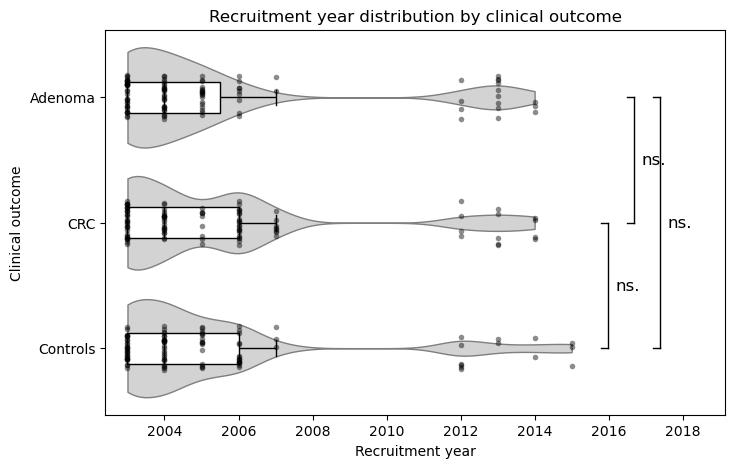

In [12]:
from itertools import combinations
from scipy.stats import mannwhitneyu, ks_2samp
from statsmodels.stats.multitest import multipletests
from scipy.stats import chi2_contingency

meta = metadata_file.copy()

# Make sure date column is datetime
meta["RekrutierungsDat"] = pd.to_datetime(
    meta["RekrutierungsDat"],
    errors="coerce"
)

# Extract year
meta["Recruitment_year"] = meta["RekrutierungsDat"].dt.year

# Remove missing values
meta_qc = meta.dropna(
    subset=["clinical outcome", "Recruitment_year"]
).copy()

meta_qc["Recruitment_year"] = meta_qc["Recruitment_year"].astype(int)
# group_order = list(meta_qc["clinical outcome"].dropna().unique())
group_order = ["Controls", "Adenoma", "CRC"]

results = []

for g1, g2 in combinations(meta_qc["clinical outcome"].dropna().unique(), 2):
    y1 = meta_qc.loc[meta_qc["clinical outcome"] == g1, "Recruitment_year"]
    y2 = meta_qc.loc[meta_qc["clinical outcome"] == g2, "Recruitment_year"]

    mw = mannwhitneyu(y1, y2, alternative="two-sided")
    ks = ks_2samp(y1, y2, alternative="two-sided")

    results.append({
        "group1": g1,
        "group2": g2,
        "n1": len(y1),
        "n2": len(y2),
        "median_year_1": y1.median(),
        "median_year_2": y2.median(),
        "mannwhitney_p": mw.pvalue,
        "ks_p": ks.pvalue
    })

pairwise_results = pd.DataFrame(results)

pairwise_results["mannwhitney_p_adj"] = multipletests(
    pairwise_results["mannwhitney_p"],
    method="fdr_bh"
)[1]

pairwise_results["ks_p_adj"] = multipletests(
    pairwise_results["ks_p"],
    method="fdr_bh"
)[1]

pairwise_results


fig, ax = plt.subplots(figsize=(8, 5))

sns.violinplot(
    data=meta_qc,
    y="clinical outcome",
    x="Recruitment_year",
    inner=None,
    cut=0,
    linewidth=1,
    bw_adjust=0.5,
    color="lightgray"
)

sns.boxplot(
    data=meta_qc,
    y="clinical outcome",
    x="Recruitment_year",
    width=0.25,
    showfliers=False,
    boxprops={"facecolor": "white", "edgecolor": "black"},
    whiskerprops={"color": "black"},
    capprops={"color": "black"},
    medianprops={"color": "black"},
)

sns.stripplot(
    data=meta_qc,
    y="clinical outcome",
    x="Recruitment_year",
    color="black",
    alpha=0.45,
    size=4,
    jitter=0.18
)

add_horizontal_sig_bars(
    ax=ax,
    pairwise_results=pairwise_results,
    group_order=group_order,
    p_col="mannwhitney_p_adj"   # or "ks_p_adj"
)

ax.set_xlabel("Recruitment year")
ax.set_ylabel("Clinical outcome")
ax.set_title("Recruitment year distribution by clinical outcome")



Chi-square = 26.576
df = 16
p-value = 0.04645


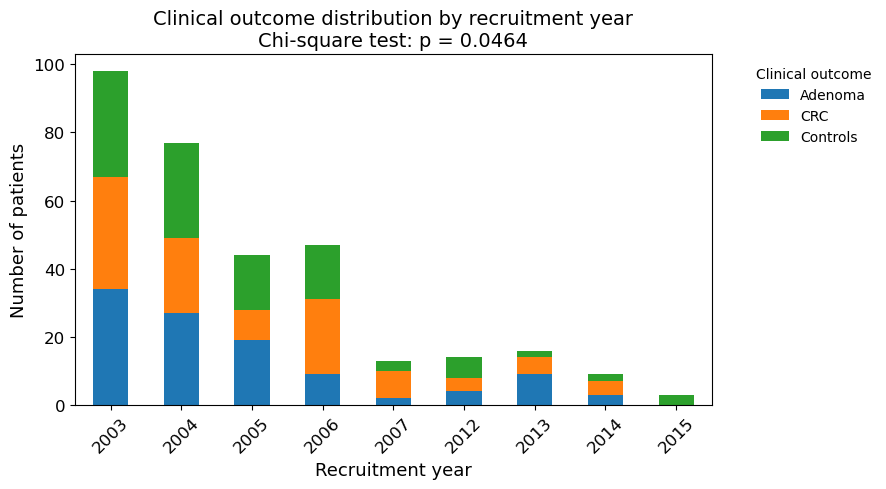

In [13]:
contingency = pd.crosstab(
    meta_qc["Recruitment_year"],
    meta_qc["clinical outcome"]
)

chi2, p_value, dof, expected = chi2_contingency(contingency)

print(f"Chi-square = {chi2:.3f}")
print(f"df = {dof}")
print(f"p-value = {p_value:.4g}")



ax = contingency.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

ax.set_xlabel("Recruitment year", fontsize=13)
ax.set_ylabel("Number of patients", fontsize=13)

ax.set_title(
    f"Clinical outcome distribution by recruitment year\n"
    f"Chi-square test: p = {p_value:.3g}",
    fontsize=14
)

ax.tick_params(axis="x", labelsize=12, rotation=45)
ax.tick_params(axis="y", labelsize=12)

ax.legend(
    title="Clinical outcome",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()


In [14]:
# # First we need to get a useful table to work with metadata
# metadata_CORSA = pd.read_excel('Projects/CORSA/Metadata_file.xlsx')
# dict_id_samplenames = {}
# for x,y in zip([int(x.split('_')[3]) for x in list(sampleset.sampleset_bin.columns)], list(sampleset.sampleset_bin.columns)):
#     dict_id_samplenames[x] = y

# print(list(dict_id_samplenames.keys()))

# for i in list(dict_id_samplenames.keys()):
#     if i not in list(metadata_CORSA['Sample']):
#         print(i)

# metadata_CORSA['SampleName'] = metadata_CORSA['Sample'].replace(dict_id_samplenames)
# metadata_CORSA['clinical outcome'] = metadata_CORSA['group_test'].apply(lambda x: x.replace('Kontrollen', 'Controls'))
# metadata_CORSA = metadata_CORSA[['Sample', 'SampleName', 'group_test', 'Gender', 'Age']]
# metadata_CORSA['SampleName'] = metadata_CORSA['SampleName'].astype(str)
# metadata_CORSA[metadata_CORSA['SampleName'].str.contains('_') == False]
# metadata_CORSA = metadata_CORSA[metadata_CORSA['SampleName'].str.contains('R') == True]
# metadata_CORSA.to_excel('/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/Metadata_file.xlsx')

## Age match?

In [15]:
sample_sheet = sampleset.sample_sheet.set_index('SampleName').drop(columns='Unnamed: 0')
sample_sheet['Sample'] = sample_sheet['Sample'].astype(str)
sample_sheet.to_csv(os.path.join(PATH_OUTPUT, 'Metadata_updated.tsv'), sep='\t')

### Execute workflow

In [16]:
sampleset.sampleset_bin.sum(axis=0).reset_index(name='Counts')
sampleset.sample_sheet['sample_name'] = sampleset.sample_sheet['SampleName']

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/758982095.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90);


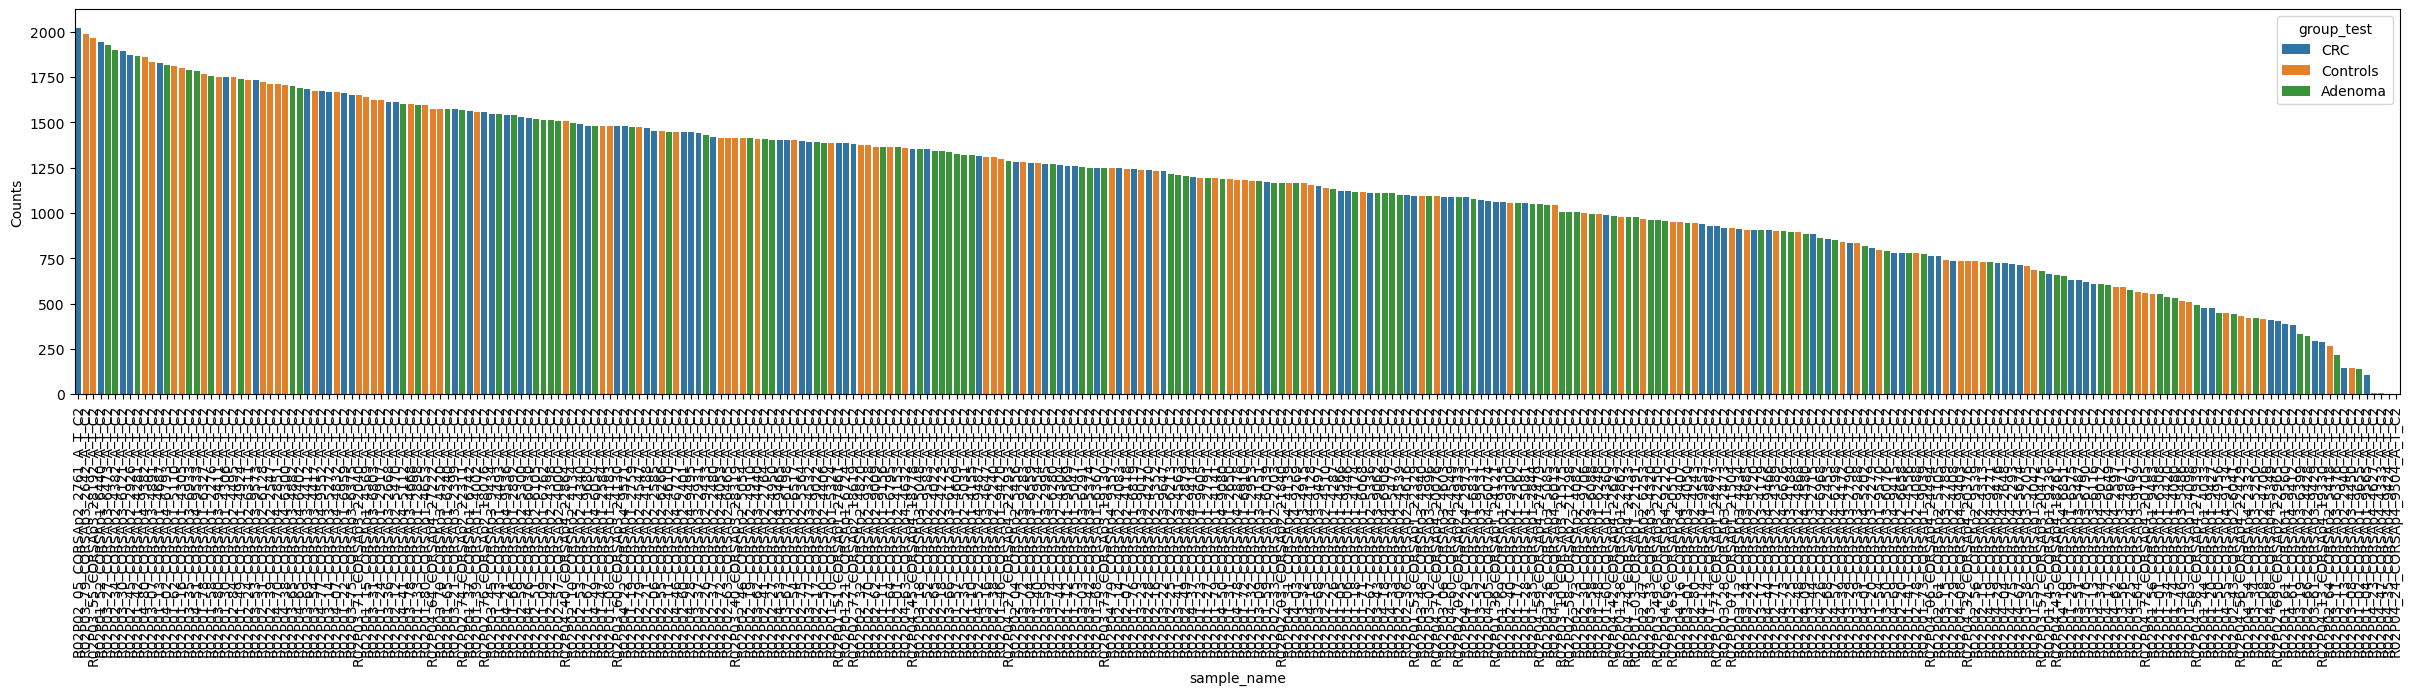

In [17]:
data_barplot = pd.merge(sampleset.sampleset_bin.sum(axis=0).reset_index(name='Counts'), sampleset.sample_sheet[['sample_name', 'group_test']], on = 'sample_name', how='inner')
data_barplot = data_barplot.sort_values(by='Counts', ascending=False)
plt.figure(figsize=(30,5))
ax = sns.barplot(data = data_barplot, x='sample_name', y='Counts', hue='group_test');
ax.set_xticklabels(ax.get_xticklabels(), rotation=90);

In [18]:
# to_remove = list(sampleset.sampleset_bin.loc[:, sampleset.sampleset_bin.sum() < 200].columns)
# to_remove
# sampleset.sampleset_bin
metadata_integrated = pd.read_excel('~/Dropbox/Vogl Lab/Storage freezers & fridges/-80°C/Cohort info/2022-10-24_EDTA plasma_CRC_MUW_Gsur.xlsx', sheet_name='Basic Data')

sampleset.sample_sheet = pd.merge(sampleset.sample_sheet, metadata_integrated[['Laufnr', 'GebDat']], left_on='Sample', right_on='Laufnr', how='left')


Dimensions of fold change matrix after filter: (89418, 311)
Dimensions of pres_abs matrix after filter: (89418, 311)
Dimensions of pres_abs matrix after filter: (89418, 311)
Output created at /Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/Final_output/
/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/Final_output/ already existing
THIS IS NEW ORDER: ['Controls', 'Adenoma', 'CRC']
Found 3 groups to test: ['Adenoma', 'CRC', 'Controls']
Group Adenoma size: 105
Group CRC size: 104
Group Controls size: 102
Number of enriched peptides in the whole sample-set selected: 89418
number of samples 311 analyzed, number of groups 3 in group_test
len of sampleset padj 89418
{'Adenoma': 105, 'CRC': 104, 'Controls': 102}
######## Prevalence distribution - Scatterplot - Delta prevalence ########
Selected threshold is 0
PRE STATISTICS (BEFORE CHI-SQ)
Number of peptides with prevalence equal to 0 in Controls: 42391
Number of peptides with prevalence equal to 0 in Adenoma: 43875
PRE PLOTTING 

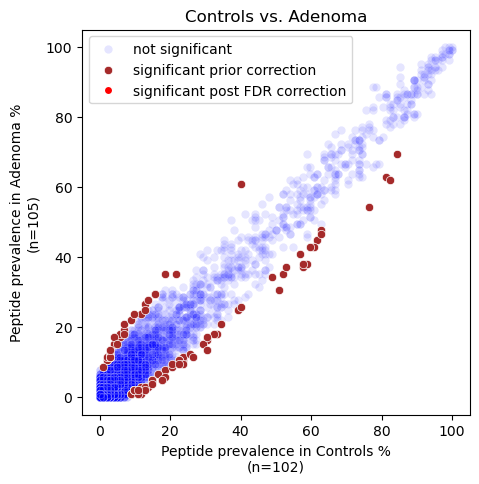

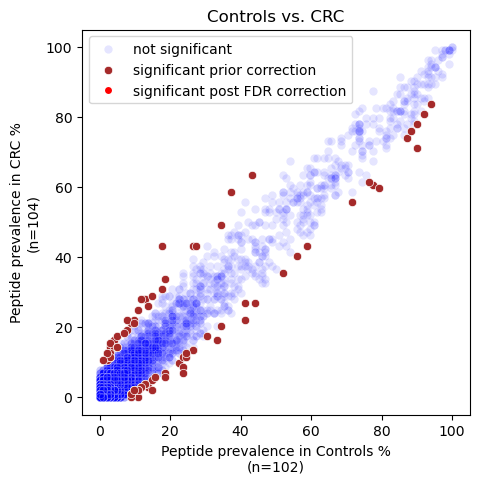

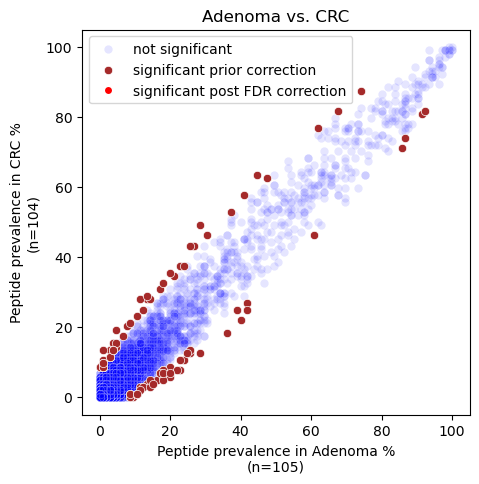

In [19]:
# Some samples are missing:
# sampleset.sample_sheet['Sex'] = sampleset.sample_sheet['Sex'].replace(1, 'M').replace(0, 'F')
to_remove = list(sampleset.sampleset_bin.loc[:, sampleset.sampleset_bin.sum() < 30].columns)


exclude_from_samplesheet = ['R02P04_11_CORSAp4_21495_A_T_C2', 'R02P04_12_CORSAp4_2883_A_T_C2', 'R02P04_36_CORSAp4_9452_A_T_C2', 'R02P04_48_CORSAp4_20415_A_T_C2']
sampleset.sample_sheet = sampleset.sample_sheet[~sampleset.sample_sheet['SampleName'].isin(exclude_from_samplesheet)]
sampleset.exclude_samples(on='samples', to_exclude=to_remove)
# filter_formula = (['Study arm', 'MCR'],`` {'MCR' : ['responder', 'non-responder'], 'group_test' :['1', '5', '6', '7']})
sampleset.start_experiment_with_groups(path_output=PATH_OUTPUT, column_group='group_test', age_matching=False, enriched_pept=False, 
                                       pcoa_with_permanova_test=False, 
                                       prevalence_thresh=0,
                                       alpha_div=False,
                                       scatterplots_enriched_peptides=True,
                                       venn_plots=False, group_order=['Controls', 'Adenoma', 'CRC'],
                                       check_categories=False
                                       )


mapping_vfdb

# Create mapping: peptide_name -> custom_name
vfdb_custom_name_map = (
    mapping_vfdb
    .dropna(subset=['custom_name'])
    .set_index('peptide_name')['custom_name']
    .to_dict()
)

# Recreate the dictionary with updated Description column
sampleset.dict_pair_groups_stats = {
    group_pair: df.assign(
        Description=df['peptide_name']
        .map(vfdb_custom_name_map)
        .fillna(df['Description'])
    )
    for group_pair, df in sampleset.dict_pair_groups_stats.items()
}


## Create a complete metadata table for analyzing on R

In [20]:
from skbio.stats.ordination import pcoa
from skbio.stats.distance import DistanceMatrix
from scipy.spatial.distance import pdist, squareform

# sampleset_bin = sampleset.sampleset_bin
# x = (sampleset_bin.sum(axis=1) / len(sampleset_bin.columns))
# plt.hist(x,histtype='bar', bins=100, edgecolor='darkgrey')
# x = x.reset_index(name='prevalence')

# peptides_to_keep = x[(x['prevalence'] > 0.05) | (x['prevalence'] < 0.95)]['peptide_name'].tolist()

# sampleset_bin_no_cmv_prevalence_filtered = sampleset.sampleset_bin.loc[(~sampleset.sampleset_bin.index.isin(all_cmv))]

# sampleset_bin_no_cmv_prevalence_filtered


# distance_matrix = pdist(sampleset_bin_no_cmv_prevalence_filtered.transpose().to_numpy(), metric='jaccard')
# distance_matrix = squareform(distance_matrix)
# distance_matrix = DistanceMatrix(distance_matrix, ids=sampleset_bin_no_cmv_prevalence_filtered.transpose().index)
# os.makedirs('/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/Current_output_all/Dimensionality_Reduction_PCoA_no_CMV', exist_ok=False)
# sampleset.plot_pcoa_pres_abs_with_centroids(sampleset_bin_no_cmv_prevalence_filtered, path_output=os.path.join(PATH_OUTPUT, 'Dimensionality_Reduction_PCoA_no_CMV'))
# # sampleset_bin_no_cmv[sampleset_bin_no_cmv.sum(axis=1)>
new_metadata = pd.read_excel('../Projects/CORSA/Datenset - T_Vogl sent _ metadata Batch 1.xlsx')
new_metadata
new_metadata
sampleset_bin = sampleset.sampleset_bin
updated_metadata = pd.merge(sampleset.sample_sheet, new_metadata[['Laufnr', 'Date Recruitment', 'polyp/CRC amount', 'Height', 'Weight', 'Family', 'Education', 'professional status', 'ALK', 'TABAK', 'R_BEGINN', 'R_ENDE', 'R_STÜCK', 'polyp/CRC location', 'polyp morphology', 'DM ?', 'IBD', 'FLEISCH', 'GEMUESE', 'SUESS', 'diverticular disease',
                                                                  'T (tumour)', 'N (nodes)', 'M (mets)']], left_on='Sample', right_on='Laufnr', how='left')

updated_metadata

os.makedirs(os.path.join(PATH_OUTPUT, 'Metadata_updated'), exist_ok=True)
updated_metadata = updated_metadata.rename(columns={"professional status" : "professional_status",
                                 "ALK" : "Alcohol_intake",
                                 "TABAK" : "Smoking",
                                 "IBD" : "IBD_status",
                                 "FLEISCH" : "Meat_intake",
                                 "GEMUESE" : "Vegetables_intake",
                                 "SUESS" : "Sweets_intake",
                                 "diverticular disease" : "diverticular_disease",
                                 "DM ?" : "Diabetes Mellitus", 
                                 "R_STÜCK" : "Cigarette_quantity", 
                                 "polyp/CRC location": "location", 
                                 "polyp morphology" : "morphology",
                                 "T (tumour)" : "Tumor",
                                 "N (nodes)" :  "Nodes",
                                 "M (mets)" : "Metastases"
                                 })

updated_metadata.to_csv(os.path.join(PATH_OUTPUT, 'Metadata_updated/updated_metadata.csv'), index=False)


In [21]:
mapping_vfdb

# Create mapping: peptide_name -> custom_name
vfdb_custom_name_map = (
    mapping_vfdb
    .dropna(subset=['custom_name'])
    .set_index('peptide_name')['custom_name']
    .to_dict()
)

# Recreate the dictionary with updated Description column
sampleset.dict_pair_groups_stats = {
    group_pair: df.assign(
        Description=df['peptide_name']
        .map(vfdb_custom_name_map)
        .fillna(df['Description'])
    )
    for group_pair, df in sampleset.dict_pair_groups_stats.items()
}


## Age sex matching


In [22]:
### CHECK AGE distribution according to sex and groups combinations

import statsmodels.api as sm
import statsmodels.formula.api as smf
import scipy.stats as stats

def age_groups_sex_distributions(sample_sheet, path_output, filename=None, on_column = 'group_test', compute_anova=True):
    print('######## Age and Sex distributions ########')
    num_comparisons = len(list(combinations(set(sample_sheet[on_column]), r=2)))
    if num_comparisons > 1:
        fig, axes = plt.subplots(1, num_comparisons, figsize=(2*num_comparisons,4))
        axes = axes.flatten()
    
        for i,(groups,ax) in enumerate(zip(combinations(set(sample_sheet[on_column]), r=2), axes)):
            if len(sample_sheet['Sex'].unique()) == 2:
                # Calculate bin edges using the combined Age data from both groups (CRC and Controls)
                age_data_group1 = sample_sheet[sample_sheet[on_column] == groups[0]]['Age']
                age_data_group2 = sample_sheet[sample_sheet[on_column] == groups[1]]['Age']

                # Combine data and calculate bin edges
                combined_data = np.concatenate([age_data_group1, age_data_group2])
                bin_edges = np.histogram(combined_data, bins=8)[1]  # Get bin edges (excluding counts)
                mapping = {"M" : "#95B0E2", "F" : "#DEA8A8"}

                # Plot for CRC group
                sns.histplot(y='Age',
                            hue='Sex',
                            data=sample_sheet[sample_sheet[on_column] == groups[0]],
                            bins=bin_edges,  # Use the common bin edges
                            multiple='stack',
                            palette=mapping, legend=True, ax = ax, alpha = .95, linewidth=0.5, edgecolor="white")
                
                ### For the reversed bars we need to use standard matplotlib
                # Define the pastel palette for gender (using two colors for Male and Female)
                palette = sns.color_palette('pastel', n_colors=2)
                ## Manually compute the histogram for the controls group
                group1_data = sample_sheet[sample_sheet[on_column] == groups[0]]
                group2_data = sample_sheet[sample_sheet[on_column] == groups[1]]

                # Group by gender and compute histograms for each gender
                hist_controls_male, _ = np.histogram(group2_data[group2_data['Sex'] == 'M']['Age'], bins=bin_edges)
                hist_controls_female, _ = np.histogram(group2_data[group2_data['Sex'] == 'F']['Age'], bins=bin_edges)

                # Stack the bars for females first (on the positive y-axis)
                ax.barh(
                    bin_edges[:-1], -hist_controls_male, height=np.diff(bin_edges), align='edge',
                    color=["#95B0E2"], alpha=0.95, label='M', edgecolor='white', linewidth=0.8 # Black edges for Female
                )

                # Then stack the bars for males on top of the females (on the positive y-axis)
                ax.barh(
                    bin_edges[:-1], -hist_controls_female, height=np.diff(bin_edges), align='edge',
                    color=["#DEA8A8"], alpha=0.95, left=-hist_controls_male, label='F', edgecolor='white', linewidth=0.8 # Black edges for Male
                )

                ax.axvline(x=0, linestyle='-', linewidth=1, color='black')
                if i > 0:
                    print(i)
                    ax.set_ylabel('')
                    ax.set_yticklabels('')
                else:
                    ax.set_ylabel('Age', fontsize=14)
                    ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)
                # Show legend only on last subplot
                if i == len(axes) - 1:
                    ax.legend(loc='lower right', fontsize=8, frameon=True)
                else:
                    ax.legend().remove()
                ax.set_xlabel('Count', fontsize=14)
                # Perform statistical tests
                p_values = {}

                # Combined Age + Gender (Logistic regression)
                group1_data['Group'] = 0
                group2_data['Group'] = 1
                combined_df = pd.concat([group1_data, group2_data])
                model = smf.logit("Group ~ Age + C(Sex)", data=combined_df).fit(disp=False)
                null_model = smf.logit(
                    "Group ~ 1",
                    data=combined_df
                ).fit(disp=False)

                lr_stat = 2 * (model.llf - null_model.llf)
                df_diff = model.df_model - null_model.df_model
                p_age_sex = stats.chi2.sf(lr_stat, df_diff)

                # print("Combined age + sex p-value:", p_age_sex)
                p_values['Age+Sex'] = p_age_sex # model.pvalues['Age']

                # Annotate p-values
                p_text = "\n".join([f"{key}: p={p:.3f}" for key, p in p_values.items()])
                ax.text(0.02, -0.30, p_text, transform=ax.transAxes, fontsize=10,
                        verticalalignment='top', bbox=dict(boxstyle="round", alpha=0.5))

                # After plotting, keep the tick positions and change only the tick labels to absolute values
                # After plotting, keep the tick positions and change only the tick labels to absolute values
                current_ticks = ax.get_xticks()  # Get the current x-ticks positions from ax
                # Set the tick labels to the absolute (positive) values while keeping the tick positions
                ax.set_xticklabels([int(x) for x in np.abs(current_ticks)], fontsize=14)

                # Add title and labels
                for ax in axes:
                    ax.set_xlabel("Number of\nsamples", fontsize=14)
                    ax.set_title(f'{groups[0]} vs.\n{groups[1]}', fontsize=16)
                plt.savefig(os.path.join(path_output, f'Age_group_sex_matching.svg'), 
                    facecolor='white',
                    dpi=100,
                    transparent=False,
                    bbox_inches = 'tight')
    else:
        if len(sample_sheet['Sex'].unique()) == 2:
            fig, ax = plt.subplots(1, figsize=(6,6))
            groups = list(set(sample_sheet[on_column]))
            # Calculate bin edges using the combined Age data from both groups (CRC and Controls)
            age_data_group1 = sample_sheet[sample_sheet[on_column] == groups[0]]['Age']
            age_data_group2 = sample_sheet[sample_sheet[on_column] == groups[1]]['Age']

            # Combine data and calculate bin edges
            combined_data = np.concatenate([age_data_group1, age_data_group2])
            bin_edges = np.histogram(combined_data, bins=4)[1]  # Get bin edges (excluding counts)

            # Plot for CRC group
            sns.histplot(y='Age',
                        hue='Sex',
                        data=sample_sheet[sample_sheet[on_column] == groups[0]],
                        bins=bin_edges,  # Use the common bin edges
                        multiple='stack',
                        palette='pastel', legend=True, ax = ax, fontsize=14)
            
            ### For the reversed bars we need to use standard matplotlib
            # Define the pastel palette for gender (using two colors for Male and Female)
            palette = sns.color_palette('pastel', n_colors=2)
            ## Manually compute the histogram for the controls group
            group1_data = sample_sheet[sample_sheet[on_column] == groups[0]]
            group2_data = sample_sheet[sample_sheet[on_column] == groups[1]]

            # Group by gender and compute histograms for each gender
            hist_controls_male, _ = np.histogram(group2_data[group2_data['Sex'] == 'M']['Age'], bins=bin_edges)
            hist_controls_female, _ = np.histogram(group2_data[group2_data['Sex'] == 'F']['Age'], bins=bin_edges)

            # Stack the bars for females first (on the positive y-axis)
            ax.barh(
                bin_edges[:-1], -hist_controls_male, height=np.diff(bin_edges), align='edge',
                color=palette[1], alpha=0.7, label='M', edgecolor='black'  # Black edges for Female
            )

            # Then stack the bars for males on top of the females (on the positive y-axis)
            ax.barh(
                bin_edges[:-1], -hist_controls_female, height=np.diff(bin_edges), align='edge',
                color=palette[0], alpha=0.7, left=-hist_controls_male, label='F', edgecolor='black'  # Black edges for Male
            )
            ax.axvline(x=0, linestyle='-', linewidth=1, color='black')

            # Combined Age + Gender (Logistic regression)
            group1_data['Group'] = 0
            group2_data['Group'] = 1
            combined_df = pd.concat([group1_data, group2_data])
            model = smf.logit("Group ~ Age + C(Sex)", data=combined_df).fit(disp=False)
            p_values['Age+Sex'] = model.pvalues['Age']

            # Annotate p-values
            p_text = "\n".join([f"{key}: p={p:.3f}" for key, p in p_values.items()])
            ax.text(0.35, -0.35, p_text, transform=ax.transAxes, fontsize=10,
                    verticalalignment='top', bbox=dict(boxstyle="round", alpha=0.5))
            # After plotting, keep the tick positions and change only the tick labels to absolute values
            # After plotting, keep the tick positions and change only the tick labels to absolute values
            current_ticks = ax.get_xticks()  # Get the current x-ticks positions from ax
            # Set the tick labels to the absolute (positive) values while keeping the tick positions
            ax.set_xticklabels([int(x) for x in np.abs(current_ticks)])


            # Add title and labels
            plt.xlabel('Age')
            plt.ylabel('Number of samples')
            ax.set_title(f'{groups[0]} vs. {groups[1]}')
        # Save final figure
    if filename:
        plt.savefig(os.path.join(path_output, f'{filename}.svg'), 
                    facecolor='white',
                    dpi=100,
                    transparent=False,
                    bbox_inches = 'tight')
    else:
        plt.savefig(os.path.join(path_output, f'Age_group_sex_matching.svg'), 
                    facecolor='white',
                    dpi=100,
                    transparent=False,
                    bbox_inches = 'tight')



                    

## Peptides counts distribution across groups 

In [23]:
### CHECK AGE distribution according to sex and groups combinations

import statsmodels.api as sm
import statsmodels.formula.api as smf
import scipy.stats as stats

def age_groups_sex_distributions(sample_sheet, path_output, filename=None, on_column = 'group_test', compute_anova=True):
    print('######## Age and Sex distributions ########')
    os.makedirs(path_output, exist_ok=True)
    num_comparisons = len(list(combinations(set(sample_sheet[on_column]), r=2)))
    if num_comparisons > 1:
        fig, axes = plt.subplots(1, num_comparisons, figsize=(2*num_comparisons,4))
        axes = axes.flatten()
    
        for i,(groups,ax) in enumerate(zip(combinations(set(sample_sheet[on_column]), r=2), axes)):
            if len(sample_sheet['Sex'].unique()) == 2:
                # Calculate bin edges using the combined Age data from both groups (CRC and Controls)
                age_data_group1 = sample_sheet[sample_sheet[on_column] == groups[0]]['Age']
                age_data_group2 = sample_sheet[sample_sheet[on_column] == groups[1]]['Age']

                # Combine data and calculate bin edges
                combined_data = np.concatenate([age_data_group1, age_data_group2])
                bin_edges = np.histogram(combined_data, bins=8)[1]  # Get bin edges (excluding counts)
                mapping = {"M" : "#95B0E2", "F" : "#DEA8A8"}

                # Plot for CRC group
                sns.histplot(y='Age',
                            hue='Sex',
                            data=sample_sheet[sample_sheet[on_column] == groups[0]],
                            bins=bin_edges,  # Use the common bin edges
                            multiple='stack',
                            palette=mapping, legend=True, ax = ax, alpha = .95, linewidth=0.5, edgecolor="white")
                
                ### For the reversed bars we need to use standard matplotlib
                # Define the pastel palette for gender (using two colors for Male and Female)
                palette = sns.color_palette('pastel', n_colors=2)
                ## Manually compute the histogram for the controls group
                group1_data = sample_sheet[sample_sheet[on_column] == groups[0]]
                group2_data = sample_sheet[sample_sheet[on_column] == groups[1]]

                # Group by gender and compute histograms for each gender
                hist_controls_male, _ = np.histogram(group2_data[group2_data['Sex'] == 'M']['Age'], bins=bin_edges)
                hist_controls_female, _ = np.histogram(group2_data[group2_data['Sex'] == 'F']['Age'], bins=bin_edges)

                # Stack the bars for females first (on the positive y-axis)
                ax.barh(
                    bin_edges[:-1], -hist_controls_male, height=np.diff(bin_edges), align='edge',
                    color=["#95B0E2"], alpha=0.95, label='M', edgecolor='white', linewidth=0.8 # Black edges for Female
                )

                # Then stack the bars for males on top of the females (on the positive y-axis)
                ax.barh(
                    bin_edges[:-1], -hist_controls_female, height=np.diff(bin_edges), align='edge',
                    color=["#DEA8A8"], alpha=0.95, left=-hist_controls_male, label='F', edgecolor='white', linewidth=0.8 # Black edges for Male
                )

                ax.axvline(x=0, linestyle='-', linewidth=1, color='black')
                if i > 0:
                    print(i)
                    ax.set_ylabel('')
                    ax.set_yticklabels('')
                else:
                    ax.set_ylabel('Age', fontsize=14)
                    ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)
                # Show legend only on last subplot
                if i == len(axes) - 1:
                    ax.legend(loc='lower right', fontsize=8, frameon=True)
                else:
                    ax.legend().remove()
                ax.set_xlabel('Count', fontsize=14)
                # Perform statistical tests
                p_values = {}

                # Combined Age + Gender (Logistic regression)
                group1_data['Group'] = 0
                group2_data['Group'] = 1
                combined_df = pd.concat([group1_data, group2_data])
                model = smf.logit("Group ~ Age + C(Sex)", data=combined_df).fit(disp=False)
                null_model = smf.logit(
                    "Group ~ 1",
                    data=combined_df
                ).fit(disp=False)

                lr_stat = 2 * (model.llf - null_model.llf)
                df_diff = model.df_model - null_model.df_model
                p_age_sex = stats.chi2.sf(lr_stat, df_diff)

                # print("Combined age + sex p-value:", p_age_sex)
                p_values['Age+Sex'] = p_age_sex # model.pvalues['Age']

                # Annotate p-values
                p_text = "\n".join([f"{key}: p={p:.3f}" for key, p in p_values.items()])
                ax.text(0.02, -0.30, p_text, transform=ax.transAxes, fontsize=10,
                        verticalalignment='top', bbox=dict(boxstyle="round", alpha=0.5))

                # After plotting, keep the tick positions and change only the tick labels to absolute values
                # After plotting, keep the tick positions and change only the tick labels to absolute values
                current_ticks = ax.get_xticks()  # Get the current x-ticks positions from ax
                # Set the tick labels to the absolute (positive) values while keeping the tick positions
                ax.set_xticklabels([int(x) for x in np.abs(current_ticks)], fontsize=14)

                # Add title and labels
                for ax in axes:
                    ax.set_xlabel("Number of\nsamples", fontsize=14)
                    ax.set_title(f'{groups[0]} vs.\n{groups[1]}', fontsize=16)
                plt.savefig(os.path.join(path_output, f'Age_group_sex_matching.svg'), 
                    facecolor='white',
                    dpi=100,
                    transparent=False,
                    bbox_inches = 'tight')
    else:
        if len(sample_sheet['Sex'].unique()) == 2:
            fig, ax = plt.subplots(1, figsize=(6,6))
            groups = list(set(sample_sheet[on_column]))
            # Calculate bin edges using the combined Age data from both groups (CRC and Controls)
            age_data_group1 = sample_sheet[sample_sheet[on_column] == groups[0]]['Age']
            age_data_group2 = sample_sheet[sample_sheet[on_column] == groups[1]]['Age']

            # Combine data and calculate bin edges
            combined_data = np.concatenate([age_data_group1, age_data_group2])
            bin_edges = np.histogram(combined_data, bins=4)[1]  # Get bin edges (excluding counts)

            # Plot for CRC group
            sns.histplot(y='Age',
                        hue='Sex',
                        data=sample_sheet[sample_sheet[on_column] == groups[0]],
                        bins=bin_edges,  # Use the common bin edges
                        multiple='stack',
                        palette='pastel', legend=True, ax = ax, fontsize=14)
            
            ### For the reversed bars we need to use standard matplotlib
            # Define the pastel palette for gender (using two colors for Male and Female)
            palette = sns.color_palette('pastel', n_colors=2)
            ## Manually compute the histogram for the controls group
            group1_data = sample_sheet[sample_sheet[on_column] == groups[0]]
            group2_data = sample_sheet[sample_sheet[on_column] == groups[1]]

            # Group by gender and compute histograms for each gender
            hist_controls_male, _ = np.histogram(group2_data[group2_data['Sex'] == 'M']['Age'], bins=bin_edges)
            hist_controls_female, _ = np.histogram(group2_data[group2_data['Sex'] == 'F']['Age'], bins=bin_edges)

            # Stack the bars for females first (on the positive y-axis)
            ax.barh(
                bin_edges[:-1], -hist_controls_male, height=np.diff(bin_edges), align='edge',
                color=palette[1], alpha=0.7, label='M', edgecolor='black'  # Black edges for Female
            )

            # Then stack the bars for males on top of the females (on the positive y-axis)
            ax.barh(
                bin_edges[:-1], -hist_controls_female, height=np.diff(bin_edges), align='edge',
                color=palette[0], alpha=0.7, left=-hist_controls_male, label='F', edgecolor='black'  # Black edges for Male
            )
            ax.axvline(x=0, linestyle='-', linewidth=1, color='black')

            # Combined Age + Gender (Logistic regression)
            group1_data['Group'] = 0
            group2_data['Group'] = 1
            combined_df = pd.concat([group1_data, group2_data])
            model = smf.logit("Group ~ Age + C(Sex)", data=combined_df).fit(disp=False)
            p_values['Age+Sex'] = model.pvalues['Age']

            # Annotate p-values
            p_text = "\n".join([f"{key}: p={p:.3f}" for key, p in p_values.items()])
            ax.text(0.35, -0.35, p_text, transform=ax.transAxes, fontsize=10,
                    verticalalignment='top', bbox=dict(boxstyle="round", alpha=0.5))
            # After plotting, keep the tick positions and change only the tick labels to absolute values
            # After plotting, keep the tick positions and change only the tick labels to absolute values
            current_ticks = ax.get_xticks()  # Get the current x-ticks positions from ax
            # Set the tick labels to the absolute (positive) values while keeping the tick positions
            ax.set_xticklabels([int(x) for x in np.abs(current_ticks)])


            # Add title and labels
            plt.xlabel('Age')
            plt.ylabel('Number of samples')
            ax.set_title(f'{groups[0]} vs. {groups[1]}')
        # Save final figure
    if filename:
        plt.savefig(os.path.join(path_output, f'{filename}.svg'), 
                    facecolor='white',
                    dpi=100,
                    transparent=False,
                    bbox_inches = 'tight')
    else:
        plt.savefig(os.path.join(path_output, f'Age_group_sex_matching.svg'), 
                    facecolor='white',
                    dpi=100,
                    transparent=False,
                    bbox_inches = 'tight')



                    

######## Age and Sex distributions ########


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/1974924757.py:64: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/1974924757.py:75: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/1974924757.py:76: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0

1
2


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/1974924757.py:75: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/1974924757.py:76: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/1974924757.py:100: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



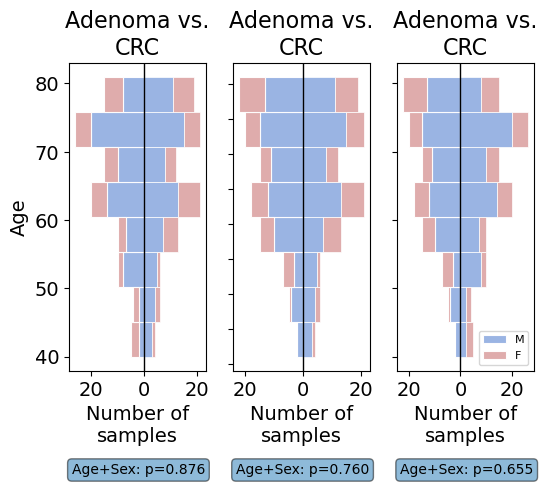

In [24]:
age_groups_sex_distributions(sample_sheet=sampleset.sample_sheet, path_output=os.path.join(PATH_OUTPUT, "Age_Sex_distributions"), filename=None, on_column = 'group_test', compute_anova=True)

## Antibody repertoires counts over the population


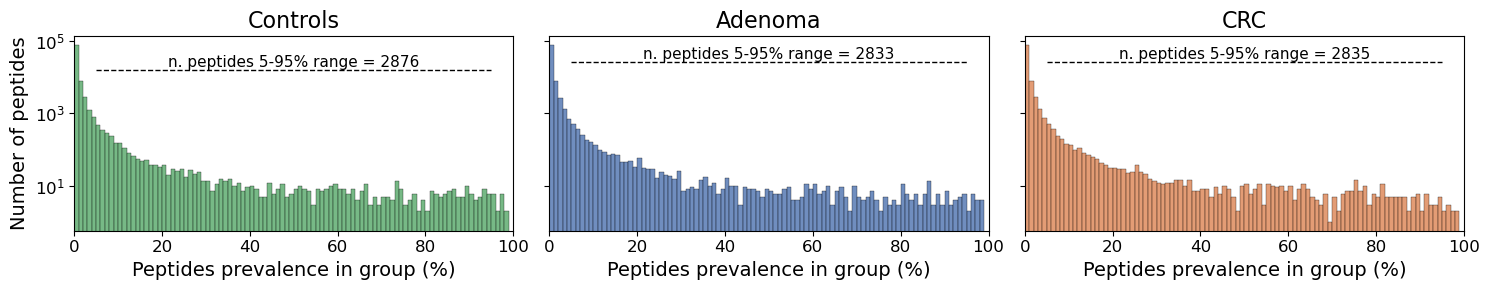

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# sampleset.sampleset_bin: rows = peptides, columns = samples
df_bin = sampleset.sampleset_bin.copy()

# Example colors for the 3 groups
group_colors = [ '#55A868', '#4C72B0', '#DD8452',]   # change as you like

# Get group names
group_names = list(sampleset.dict_groups_list.keys())

def plot_population_wise_antigenic_frequency(df_bin=None, group_names = None, group_colors = None, filename=None, level='peptides'):
    os.makedirs(os.path.join(PATH_OUTPUT, "Group_diversity"), exist_ok=True)
    # Create one subplot per group
    fig, axes = plt.subplots(1, len(group_names), figsize=(5 * len(group_names), 3), sharey=True)

    # If only one group, make axes iterable
    if len(group_names) == 1:
        axes = [axes]

    for i, (group, ax) in enumerate(zip(group_names, axes)):
        
        # Samples belonging to this group
        group_samples = sampleset.dict_groups_list[group]
        
        # Keep only samples that are actually present in the matrix
        group_samples = [s for s in group_samples if s in df_bin.columns]
        
        # Compute prevalence percentage for each peptide in this group
        # assuming binary matrix with 0/1 values
        prevalence_pct = df_bin[group_samples].sum(axis=1) / len(group_samples) * 100
        # Calculate the number of peptides within 5-95% interval
        n_peptides_5_95 = ((prevalence_pct >= 5) & (prevalence_pct <= 95)).sum()
        # Histogram
        sns.histplot(
            prevalence_pct,
            bins=np.arange(0, 100, 1),   # 0-100 in bins of 10
            color=group_colors[i],
            edgecolor='black',
            alpha=0.8,
            ax=ax,
        )
        
        ax.set_title(group, fontsize=16)
        ax.set_xlabel(f'{level.capitalize()} prevalence in group (%)', fontsize=14)
        
        if i == 0:
            ax.set_ylabel(f'Number of {level}', fontsize=14)
        else:
            ax.set_ylabel('')
            ax.tick_params(axis='y', labelleft=False)
        
        ax.tick_params(axis='both', labelsize=12)
        ax.set_xlim(0, 100)
        y_pos = ax.get_ylim()[1] * 0.2  # place it near the top (adjust if needed)

        ax.hlines(
            y=y_pos,
            xmin=5,
            xmax=95,
            color='black',
            linestyle='--',
            linewidth=1
        )
        ax.text(
        50,  # midpoint
        y_pos + ax.get_ylim()[1]*0.04,
        f'n. {level} 5-95% range = {n_peptides_5_95}',
        ha='center',
        fontsize=11
        )
        plt.yscale('log')

    plt.tight_layout()
    # Save final figure
    if filename:
        plt.savefig(os.path.join(PATH_OUTPUT, f'Group_diversity/{filename}.svg'), 
                    facecolor='white',
                    dpi=100,
                    transparent=False,
                    bbox_inches = 'tight')

    else:
        plt.savefig(os.path.join(PATH_OUTPUT, f'Group_diversity/Peptides_observation_distribution.svg'), 
                    facecolor='white',
                    dpi=100,
                    transparent=False,
                    bbox_inches = 'tight')

plot_population_wise_antigenic_frequency(df_bin=df_bin, group_colors=group_colors, group_names=group_names)

## Venn plots: Intersection between peptides

######## Venn plots ########
Found 47027 peptides with prevalence >= 0 in group Controls
Found 45543 peptides with prevalence >= 0 in group Adenoma
Found 45410 peptides with prevalence >= 0 in group CRC


{'Controls': ['agilent_128796',
  'twist_51663',
  'agilent_193994',
  'twist_91409',
  'agilent_134269',
  'twist_67977',
  'agilent_22018',
  'agilent_212553',
  'agilent_54530',
  'agilent_91996',
  'agilent_70316',
  'agilent_24579',
  'twist_33494',
  'agilent_202307',
  'twist_95308',
  'agilent_114887',
  'agilent_98490',
  'agilent_218922',
  'agilent_90266',
  'agilent_32653',
  'twist_72437',
  'twist_26931',
  'agilent_117728',
  'twist_73750',
  'agilent_143415',
  'agilent_243790',
  'agilent_1957',
  'agilent_13337',
  'agilent_239309',
  'twist_36391',
  'agilent_13347',
  'agilent_44645',
  'agilent_124607',
  'agilent_166404',
  'agilent_130555',
  'agilent_102786',
  'agilent_50052',
  'agilent_4454',
  'agilent_17246',
  'agilent_181312',
  'twist_9200',
  'agilent_143214',
  'agilent_184356',
  'agilent_36254',
  'agilent_4915',
  'agilent_55118',
  'agilent_91025',
  'agilent_123168',
  'agilent_2111',
  'twist_19208',
  'twist_87117',
  'agilent_143432',
  'agilen

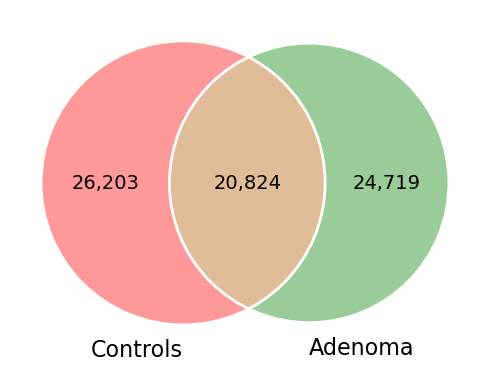

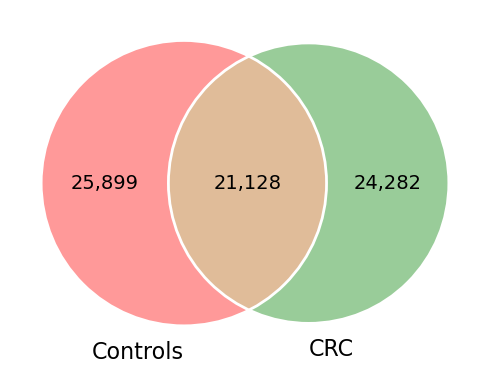

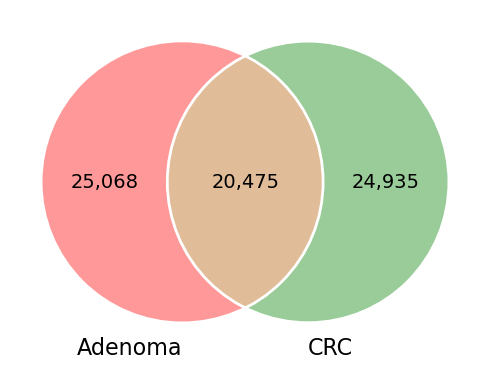

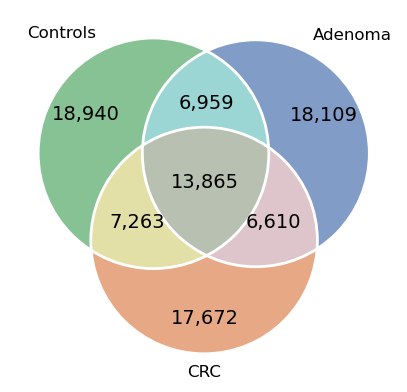

In [26]:
from matplotlib_venn import venn2, venn2_circles, venn3, venn3_circles


def plot_venn_with_conditions(df_prevalences, dict_groups_list, prevalence_thresh=0, single_libraries=False, path_output=None):
    print('######## Venn plots ########')
    os.makedirs(path_output, exist_ok=True)
    # If the single libraries need to be plotted (JUST in CASE)
    if single_libraries:
        for library in ['agilent', 'corona2', 'twist']:
            fig, axes = plt.subplots(1,3, figsize=(12,5))
            df_prevalence_filt = df_prevalences[df_prevalences.index.str.contains(library)]

            dict_of_prevalences = {}
            for group in dict_groups_list.keys():
                df_prevalence_index = list(set(df_prevalence_filt[df_prevalence_filt[group] >= prevalence_thresh].index.tolist()))
                dict_of_prevalences[group] = df_prevalence_index

            
            for (group1,group2), ax in zip(combinations(dict_of_prevalences.keys(), r=2), axes):
                venn2(subsets=(set(dict_of_prevalences[group1]), set(dict_of_prevalences[group2])), set_labels=(group1, group2), ax=ax)
                plt.savefig(os.path.join(path_output, f'Intersection_enriched_peptides_{group1}_vs_{group2}.png'), 
                facecolor='white',
                dpi=300,
                transparent=False,
                bbox_inches = 'tight')
    # Otherwise we analize all libraries together (DEFAULT)
    else:
        dict_of_prevalences = {}
        dict_of_counts = {}
        for group in dict_groups_list.keys():
            df_prevalence_index = list(
                set(df_prevalences[df_prevalences[group] > prevalence_thresh].index.tolist())
            )
            dict_of_prevalences[group] = df_prevalence_index
            print(
                f'Found {len(dict_of_prevalences[group])} peptides with prevalence >= {prevalence_thresh} in group {group}'
            )

        for group1, group2 in combinations(dict_of_prevalences.keys(), r=2):
            fig, ax = plt.subplots(figsize=(5, 5))

            v = venn2(
                subsets=(set(dict_of_prevalences[group1]), set(dict_of_prevalences[group2])),
                set_labels=(group1, group2),
                ax=ax
            )

            circles = venn2_circles(
                subsets=(set(dict_of_prevalences[group1]), set(dict_of_prevalences[group2])),
                ax=ax
            )
            for circle in circles:
                circle.set_edgecolor("white")

            # Bigger set label font
            if v.set_labels is not None:
                for label in v.set_labels:
                    if label is not None:
                        label.set_fontsize(16)

            # Format subset numbers with thousands separator
            if v.subset_labels is not None:
                for label in v.subset_labels:
                    if label is not None:
                        value = label.get_text()
                        if value.isdigit():
                            label.set_text(f"{int(value):,}")
                        label.set_fontsize(14)

            plt.tight_layout()

            plt.savefig(
                os.path.join(path_output, f'Intersection_enriched_peptides_{group1}_vs_{group2}.svg'),
                facecolor='white',
                transparent=False,
                bbox_inches='tight',
                format='svg'
            )
        dict_of_prevalences = dict_of_prevalences
        try:
            plt.figure(figsize=(5,5))
            v = venn3(subsets=tuple([set(dict_of_prevalences[x]) for x in dict_of_prevalences.keys()]), set_labels=tuple([x for x in dict_of_prevalences.keys()]), set_colors=[ '#55A868', '#4C72B0', '#DD8452'], alpha=.7)
            # Edge colors in white seem nicer
            circles = venn3_circles(subsets=tuple([set(dict_of_prevalences[x]) for x in dict_of_prevalences.keys()]))
            for circle in circles:
                circle.set_edgecolor("white")
            # Format subset numbers with thousands separator
            if v.subset_labels is not None:
                for label in v.subset_labels:
                    if label is not None:
                        value = label.get_text()
                        if value.isdigit():
                            label.set_text(f"{int(value):,}")
                        label.set_fontsize(14)
            plt.savefig(os.path.join(path_output, f'Intersection_enriched_peptides_all_groups.svg'), 
                facecolor='white',
                dpi=300,
                transparent=False,
                bbox_inches = 'tight')
        except:
            if len(dict_groups_list.keys()) < 3:
                print('Less than 3 groups')
            elif  len(dict_groups_list.keys()) > 3:
                print('More than 3 groups, consider using Upset plot')
        return dict_of_prevalences

plot_venn_with_conditions(df_prevalences=sampleset.df_prevalences, dict_groups_list=sampleset.dict_groups_list,  prevalence_thresh=0, single_libraries=False, path_output=os.path.join(PATH_OUTPUT, 'Venn_plots'))



    # # Function to perform the age matching test using the sample_sheet 'group_test' column for groups, and 'Age'.
    # @check_boxplot_kwargs
    # @check_save_kwargs
    # def perform_age_matching_test(self, path_output, on_column='group_test', use_stars=False, boxplot_kwargs=None, save_kwargs=None):
        
    #     sampleset_metadata = self.sample_sheet
    #     plt.figure(figsize=(5,5))
    #     ax = sns.boxplot(data=sampleset_metadata, x=on_column, y = 'Age', hue=on_column, boxprops=dict(alpha=.5), **boxplot_kwargs)
    #     # Rotate y-tick labels
    #     # ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='left')
    #     # Add group sizes to the tick labels and rotate
    #     ax.set_xticklabels([f'{x.get_text()}\n(n={str(len(self.dict_groups_list[x.get_text()]))})' for x in ax.get_xticklabels()], rotation=45)
    #     adjusted_pvals, comparisons = perform_pairwaise_test(sampleset_metadata, group=on_column, test='mannwhitney-u', value = 'Age')
    #     add_bars_pairwaise_boxplots(sampleset_metadata, 
    #                                 ax=ax, 
    #                                 comparisons=comparisons, 
    #                                 value='Age', 
    #                                 p_adjusted=adjusted_pvals, 
    #                                 use_stars=use_stars,
    #                                 show_only_significant=True)
    #     perform_average_and_std_stats(sampleset_metadata, groups_to_test=self.group_names, on_column=on_column)
    #     plt.savefig(os.path.join(path_output, f'Age_Sex_comparison_boxplot_{"_vs_".join(self.group_names)}.png'), 
    #                     facecolor='white',
    #                     dpi=100,
    #                     transparent=False,
    #                     bbox_inches = 'tight', **save_kwargs)

## Number of peptides bound per group and diversity (shannon) 

######## Number peptides per group ########
show_only_significant set to False


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/104472571.py:119: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/104472571.py:136: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/104472571.py:137: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/Users/gabrielinnocenti/miniconda3/envs/phipseq_data_analysis/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning:

5.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

/Users/gabrielinnocenti/miniconda3/envs/phipseq_data_analysis/lib/python3.9/site-packages/seaborn/categorical.py:3399: User

######## Alpha diversity ########
Group order is: ['Controls', 'Adenoma', 'CRC']
New group order: ['Controls', 'Adenoma', 'CRC']


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/104472571.py:195: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/104472571.py:246: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/104472571.py:247: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/Users/gabrielinnocenti/miniconda3/envs/phipseq_data_analysis/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning:

6.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

/Users/gabrielinnocenti/miniconda3/envs/phipseq_data_analysis/lib/python3.9/site-packages/seaborn/categorical.py:3399: User

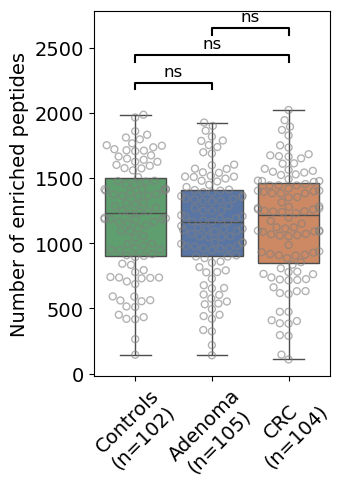

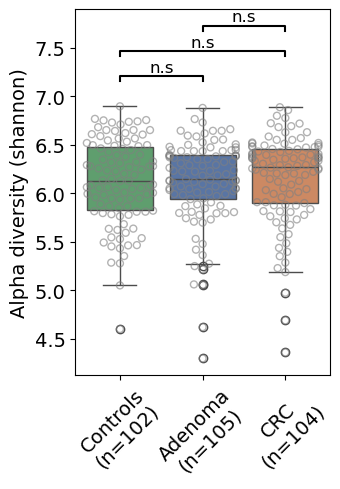

In [27]:
from skbio.diversity import alpha_diversity
from scipy.stats import ttest_ind


def perform_pairwaise_test(df, group, value, test='mannwhitney-u', use_stars=False):
    import numpy as np
    import scipy.stats as stats
    from statsmodels.stats.multitest import multipletests
    from scipy.stats import ttest_ind 
    # Perform the Mann-Whitney U test
    groups = df[group].unique()
    p_values = []
    comparisons = []
    for i in range(len(groups)):
        for j in range(i + 1, len(groups)):
            
            group1 = df[df[group] == groups[i]][value]
            group2 = df[df[group] == groups[j]][value]
            if test == 'mannwhitney-u':
                try:
                    stat, p = stats.mannwhitneyu(group1, group2)
                except Exception as e:
                    # Get the exception name
                    exception_name = type(e).__name__
                    exception_message = str(e)
                    print(f"Warning, table computed found the following error: {exception_name}: \n{exception_message}")
                    print('Adding 1 to the p-values list')
                    p_values.append(1)
            elif test == 'ttest':
                try:
                    t_statistic, p = ttest_ind(group1, group2)
                except Exception as e:
                    # Get the exception name
                    exception_name = type(e).__name__
                    exception_message = str(e)
                    print(f"Warning, table computed found the following error: {exception_name}: \n{exception_message}")
                    print('Adding 1 to the p-values list')
            else:
                raise ValueError(f"Invalid test_type: {test}. Must be 'ttest' or 'mannwhitney-u'.")
            p_values.append(p)
            comparisons.append((i, j))
    
    # Apply Benjamini-Hochberg correction
    reject, p_adjusted, _, _ = multipletests(p_values, method='bonferroni')
    return p_adjusted,comparisons

def add_bars_pairwaise_boxplots(df, ax, value, comparisons, p_adjusted, use_stars=False, threshold=0.05,
                                show_only_significant = False):
    # import numpy as np
    print(f'show_only_significant set to {show_only_significant}')
    # Calculate the maximum y-value from the data
    max_y = df[value].max()
    # Adjust positions of significance bars
    # Calculate adequate difference for the barplots
    ylim = ax.get_ylim()
    distance_between_bars = (ylim[1] - ylim[0]) / 10
    y = max_y + distance_between_bars
    edge_bar_dim = distance_between_bars/4
    text_step = distance_between_bars/8
    step = distance_between_bars
    for (i, j), p_val in zip(comparisons, p_adjusted):
        if use_stars:
            if p_val <= 1e-10:
                label = '***'
            elif p_val <= 0.0005:
                label = '**'
            elif p_val <= 0.05:
                label = '*'
            else:
                label = 'ns'  # not significant
        # else:
        #     if p_val.isnull():
        #         p_val = 'ns'
        elif not use_stars:
            if p_val < 0.05:
                label = np.format_float_scientific(p_val, precision=2)
            else:
                label = 'ns'

        # Show only significant bars
        if show_only_significant == True:
            if p_val <= threshold:
                ax.plot([i, i, j, j], [y-edge_bar_dim, y, y,  y-edge_bar_dim], lw=1.5, color='black')
                ax.text((i + j)/2, y + text_step, label, ha='center', va='bottom', color='black')
        # add_significance_bar(ax, i, j, y,p_val, use_stars=False)
        # # Adjust positions of significance bars
                y += step
            else:
                pass
        else:
            ax.plot([i, i, j, j], [y-edge_bar_dim, y, y,  y-edge_bar_dim], lw=1.5, color='black')
            ax.text((i + j)/2, y + text_step, label, ha='center', va='bottom', color='black', fontsize=12)
            y += step


def compute_number_enriched_peptides_per_group(path_output, dict_groups_list, sampleset_bin, boxplot_kwargs=None, swarmplot_kwargs=None, save_kwargs=None):
        print('######## Number peptides per group ########')
        os.makedirs(path_output, exist_ok=True)
        list_of_peptides_counts = {}
        for group, samples in dict_groups_list.items():
            summed_peptides_per_sample = sampleset_bin[samples].sum(axis=0)
            list_of_peptides_counts[group] = summed_peptides_per_sample
        # Create a dataframe of number of peptides per group
        peptides_counts_per_sample = pd.DataFrame(list_of_peptides_counts)
        # Melt the dataframe for creating the boxplot
        peptides_counts_per_sample = pd.melt(peptides_counts_per_sample, var_name='groups', value_name='values')
        # Remove entries with NaNs
        peptides_counts_per_sample = peptides_counts_per_sample[peptides_counts_per_sample['values'].isnull() == False]
        # Generate boxplot
        plt.figure(figsize=(3.5,5))
        sns.boxplot(data=peptides_counts_per_sample, x = 'groups', y='values', hue='groups', palette=['#55A868', '#4C72B0', '#DD8452'])
        ax = sns.swarmplot(data=peptides_counts_per_sample,  x = 'groups', y='values');
        # Make markers hollow
        for collection in ax.collections:
            collection.set_facecolor('none')   # remove fill
            collection.set_edgecolor('grey')   # keep edges
            collection.set_linewidth(1)
            collection.set_alpha(0.6)   # this works
        ax.set_xticklabels([f'{x.get_text()}\n(n={str(len(dict_groups_list[x.get_text()]))})' for x in ax.get_xticklabels()], rotation=45)
        # Compute pairwaise test
        adjusted_pval, comparisons = perform_pairwaise_test(peptides_counts_per_sample, 
                                                            group='groups', 
                                                            value = 'values', 
                                                            test='mannwhitney-u')

        # Add bars to boxplots
        add_bars_pairwaise_boxplots(df = peptides_counts_per_sample, 
                                    ax = ax, 
                                    value = 'values', 
                                    comparisons = comparisons, 
                                    p_adjusted=adjusted_pval, 
                                    use_stars=False,
                                    show_only_significant=False)
        ax.set_ylabel('Number of enriched peptides', fontsize=14)
        ax.set_xlabel(None)
        ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)
        ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
        plt.tight_layout()

        name = '_'.join([x for x in dict_groups_list.keys()])
        plt.savefig(os.path.join(path_output, f'Number_of_enriched_peptides_per_sample_{name}.svg'), 
                    facecolor='white',
                    dpi=100,
                    transparent=False,
                    bbox_inches = 'tight'
                    )

    ### ALPHA DIVERSITY (to only account when count data is available)

def compute_alpha_diversity_per_group(sampleset_cnt, dict_groups, path_output, metric='shannon', add_significance=True, test='t-test', show_only_significant=False, group_order=None):
    print('######## Alpha diversity ########')
    os.makedirs(path_output, exist_ok=True)
    # from skbio.diversity.alpha import shannon
    # Calculate Shannon diversity index for each group
    counts = sampleset_cnt.T  # transpose if your samples are in columns
    sample_ids = counts.index

    # Compute diversity for all samples
    diversity = alpha_diversity(
        metric=metric,
        counts=counts.values,
        ids=sample_ids
    )

    # Make dataframe with groups
    df_alpha = pd.DataFrame({
        "Sample": diversity.index,
        "AlphaDiversity": diversity.values
    })
    print(f'Group order is: {group_order}')
    # Add group annotation
    df_alpha["Group"] = df_alpha["Sample"].map(dict_groups)
    if group_order != None:
        df_alpha['Group'] = pd.Categorical(df_alpha['Group'], categories=group_order)
        print(f'New group order: {group_order}')
    df_alpha = df_alpha[df_alpha["Group"].notnull()]
    # Plot
    plt.figure(figsize=(3.5,5))
    ax = sns.boxplot(
        data=df_alpha, x="Group", 
        y="AlphaDiversity",
        hue='Group',
        palette=['#55A868', '#4C72B0', '#DD8452']
    )
    sns.swarmplot(
    data=df_alpha, x="Group", y="AlphaDiversity",
    color="grey"
    )
    for collection in ax.collections:
        collection.set_facecolor('none')   # remove fill
        collection.set_edgecolor('grey')   # keep edges
        collection.set_linewidth(1)
        collection.set_alpha(0.6)   # this works
    ax.set_ylabel(f"Alpha diversity ({metric})")
    ax.set_xticklabels(
        [f"{lab.get_text()}\n(n={sum(df_alpha['Group']==lab.get_text())})"
        for lab in ax.get_xticklabels()],
        rotation=45
    )

    plt.tight_layout()
    # --- Pairwise test ---
    if add_significance:
        # Use the categorical ordering for consistency
        groups = df_alpha["Group"].cat.categories
        comparisons = list(combinations(groups, 2))
        results = {}

        for g1, g2 in comparisons:
            vals1 = df_alpha.loc[df_alpha["Group"]==g1, "AlphaDiversity"]
            vals2 = df_alpha.loc[df_alpha["Group"]==g2, "AlphaDiversity"]

            if test == "t-test":
                stat, pval = ttest_ind(vals1, vals2, nan_policy="omit")
            elif test == "mannwhitney":
                from scipy.stats import mannwhitneyu
                stat, pval = mannwhitneyu(vals1, vals2, alternative="two-sided")
            results[(g1,g2)] = pval

        y_max = df_alpha["AlphaDiversity"].max()
        y_offset = (df_alpha["AlphaDiversity"].max() - df_alpha["AlphaDiversity"].min()) * 0.1
        height = y_max + y_offset

        for (g1,g2), pval in results.items():
            if show_only_significant and pval >= 0.05:
                continue

            x1 = list(groups).index(g1)
            x2 = list(groups).index(g2)

            ax.plot([x1, x1, x2, x2],
                    [height, height+y_offset*0.2, height+y_offset*0.2, height],
                    lw=1.5, c="k")

            label = ("n.s" if pval >= 0.05 else
                    "*" if pval < 0.05 and pval >= 0.005 else
                    "**" if pval < 0.005 and pval >= 0.0005 else
                    "***")

            ax.text((x1+x2)/2, height+y_offset*0.25, label, ha="center", va="bottom", fontsize=12)

            height += y_offset

    ax.set_ylabel(ax.get_ylabel(), fontsize=14)
    ax.set_xlabel(None)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)


    plt.tight_layout()
    plt.savefig(
        os.path.join(path_output, f"Alpha_diversity_{metric}.svg"),
        facecolor="white", dpi=100, bbox_inches="tight"
        )

compute_number_enriched_peptides_per_group(path_output=os.path.join(PATH_OUTPUT, 'Group_diversity'), 
                                           dict_groups_list=sampleset.dict_groups_list, 
                                           sampleset_bin=sampleset.sampleset_bin,
                                           )

compute_alpha_diversity_per_group(path_output=os.path.join(PATH_OUTPUT, 'Group_diversity'), 
                                           dict_groups=sampleset.dict_groups, 
                                           sampleset_cnt=sampleset.sampleset_cnt,
                                           group_order=['Controls', 'Adenoma', 'CRC']
                                           )

## Principal Coordinates Analysis 

### On peptide level data: using all peptides

In [28]:
import skbio
from skbio.stats.ordination import pcoa
from sklearn.metrics.pairwise import pairwise_distances
from sklearn.manifold import MDS
from skbio import DistanceMatrix
from skbio.stats.distance import permanova
from scipy.spatial.distance import pdist, squareform
from matplotlib.patches import Ellipse


In [55]:
def plot_pcoa_pres_abs_with_centroids(
    dict_groups,
    sampleset_bin=None,
    sampleset_rel_ab=None,
    path_output=None,
    filename=None,
    type_data='pres_abs',
    metric='jaccard',
    pc_axes=(1, 2),
    check_contribution=False,
    save_distance_matrix=False,
    plot_pcoa=True
):
    os.makedirs(path_output, exist_ok=True)
    print('######## PCOA ########')
    # Set seed
    np.random.seed(1230)

    # -----------------------------
    # Select PCs to plot
    # -----------------------------
    
    pc_x_num, pc_y_num = pc_axes
    pc_x = f'PC{pc_x_num}'
    pc_y = f'PC{pc_y_num}'

    print(f'Plotting {pc_x} vs {pc_y}')

    # -----------------------------
    # Groups
    # -----------------------------

    groups = list(dict_groups.values())

    # -----------------------------
    # Distance matrix
    # -----------------------------

    if type_data == 'pres_abs':

        distance_matrix = pdist(
            sampleset_bin.transpose().to_numpy(),
            metric=metric
        )

        distance_matrix = squareform(distance_matrix)

        if save_distance_matrix:
            distance_df = pd.DataFrame(
                distance_matrix,
                index=sampleset_bin.columns,
                columns=sampleset_bin.columns
            )

            print(
                f"Saving new distance matrix to: "
                f"{os.path.join(path_output, 'distance_matrix.csv')}"
            )

            distance_df.to_csv(
                os.path.join(path_output, 'distance_matrix.csv')
            )

        distance_matrix = DistanceMatrix(
            distance_matrix,
            ids=sampleset_bin.transpose().index
        )

    elif type_data == 'rel_ab':

        distance_matrix = pdist(
            sampleset_rel_ab.transpose().to_numpy(),
            metric=metric
        )

        distance_matrix = squareform(distance_matrix)

        distance_matrix = DistanceMatrix(
            distance_matrix,
            ids=sampleset_rel_ab.transpose().index
        )

    elif type_data == 'counts':

        distance_matrix = pdist(
            sampleset_bin.transpose().to_numpy(),
            metric='braycurtis'
        )

        distance_matrix = squareform(distance_matrix)

        distance_matrix = DistanceMatrix(
            distance_matrix,
            ids=sampleset_bin.transpose().index
        )

    else:
        raise ValueError(
            "type_data must be one of: 'pres_abs', 'rel_ab', 'counts'"
        )

    # -----------------------------
    # PCoA
    # -----------------------------

    pcoa_results = pcoa(distance_matrix)
    # Save Variance explaination
    # variance_df = (
    # pcoa_results.proportion_explained
    # .reset_index()
    # .rename(columns={"index": "PC", "proportion_explained": "Variance_explained"})
    # )

    variance_df = pcoa_results.proportion_explained.copy()

    variance_df = pd.DataFrame({
        "PC": variance_df.index,
        "Variance_explained": variance_df.values
    })

    variance_df["Variance_explained_percent"] = variance_df["Variance_explained"] * 100
    variance_df["Cumulative_variance_percent"] = variance_df["Variance_explained_percent"].cumsum()

    variance_df.to_csv(
        os.path.join(path_output, "PCoA_variance_explained.csv"),
        index=False
    )
    if plot_pcoa:
        plt.figure(figsize=(10, 4))

        sns.barplot(
            data=variance_df.head(30),
            x="PC",
            y="Variance_explained_percent",
            color="gray"
        )

        plt.xticks(rotation=90)
        plt.ylabel("Variance explained (%)")
        plt.xlabel("PCoA component")
        plt.title("PCoA variance explained")
        plt.tight_layout()

        plt.savefig(
            os.path.join(path_output, "PCoA_variance_explained.svg"),
            dpi=300,
            bbox_inches="tight"
        )

        # Cumulative variance plot to decide number of components to use
        plt.figure(figsize=(10, 4))

        sns.lineplot(
            data=variance_df.head(50),
            x="PC",
            y="Cumulative_variance_percent",
            marker="o"
        )

        plt.xticks(rotation=90)
        plt.ylabel("Cumulative variance explained (%)")
        plt.xlabel("PCoA component")
        plt.title("Cumulative PCoA variance explained")
        plt.tight_layout()

        plt.savefig(
            os.path.join(path_output, "PCoA_cumulative_variance_explained.svg"),
            dpi=300,
            bbox_inches="tight"
        )

    # Check selected PCs exist
    if pc_x not in pcoa_results.samples.columns:
        raise ValueError(f"{pc_x} not found in PCoA results.")

    if pc_y not in pcoa_results.samples.columns:
        raise ValueError(f"{pc_y} not found in PCoA results.")

    # -----------------------------
    # PERMANOVA
    # -----------------------------

    permanova_results = permanova(
        distance_matrix,
        groups,
        permutations=999
    )

    pd.DataFrame(permanova_results).to_csv(
        os.path.join(path_output, 'PCoA_permanova_output.csv')
    )

    print(permanova_results)

    # -----------------------------
    # Build PCoA dataframe
    # -----------------------------

    pcoa_df = pcoa_results.samples.copy()
    pcoa_df['Group'] = groups

    # Add variance explained for all available PCs
    for pc in pcoa_results.proportion_explained.index:
        pcoa_df[f'VarianceExplained_{pc}'] = (
            pcoa_results.proportion_explained[pc] * 100
        )

    pcoa_object = {
        'Groups': groups,
        'Pcoa_dataframe': pcoa_df,
        'Run_info': {
            'type_data': type_data,
            'metric_for_distance': metric,
            'run_permanova': True,
            'n_permutations_permanova': 999,
            'permanova_results' : permanova_results,
            'distance_matrix': distance_matrix,
            'pc_axes_plotted': pc_axes,
            'peptides_used' : sampleset_bin.shape[0]
        }
    }

    pcoa_df.to_csv(
        os.path.join(path_output, 'PCoA_values.csv')
    )
    if plot_pcoa:
        # -----------------------------
        # Centroids for selected PCs
        # -----------------------------

        centroids = (
            pcoa_df
            .groupby('Group')[[pc_x, pc_y]]
            .mean()
            .reset_index()
        )

        # -----------------------------
        # PERMANOVA values
        # -----------------------------

        p_value = permanova_results['p-value']
        permutations = permanova_results['number of permutations']

        # -----------------------------
        # Variance explained for selected PCs
        # -----------------------------

        pc_x_variance = round(
            pcoa_results.proportion_explained[pc_x] * 100,
            ndigits=4
        )

        pc_y_variance = round(
            pcoa_results.proportion_explained[pc_y] * 100,
            ndigits=4
        )

        # -----------------------------
        # Plot
        # -----------------------------

        plt.figure(figsize=(7, 5))
        ax = plt.gca()

        group_color_dict = {
            'Controls': '#55A868',
            'Adenoma': '#4C72B0',
            'CRC': '#DD8452'
        }

        sns.scatterplot(
            x=pc_x,
            y=pc_y,
            hue='Group',
            data=pcoa_df,
            palette=group_color_dict,
            s=75,
            alpha=0.8,
            ax=ax
        )

        # -----------------------------
        # Add ellipses, centroids, and lines
        # -----------------------------

        for group, group_data in pcoa_df.groupby('Group'):

            group_color = group_color_dict.get(group, 'black')

            centroid_row = centroids[centroids['Group'] == group].iloc[0]
            centroid_x = centroid_row[pc_x]
            centroid_y = centroid_row[pc_y]

            # Covariance matrix for selected PCs
            cov_matrix = np.cov(group_data[[pc_x, pc_y]].T)

            # Only draw ellipse if covariance matrix is valid
            if np.all(np.isfinite(cov_matrix)) and group_data.shape[0] > 2:

                eigenvals, eigenvecs = np.linalg.eig(cov_matrix)

                # Avoid negative numerical artefacts
                eigenvals = np.maximum(eigenvals, 0)

                angle = np.degrees(
                    np.arctan2(*eigenvecs[:, 0][::-1])
                )

                width, height = 5 * np.sqrt(eigenvals)

                ellipse = Ellipse(
                    xy=(centroid_x, centroid_y),
                    width=width,
                    height=height,
                    angle=angle,
                    edgecolor=group_color,
                    linestyle='--',
                    linewidth=2.5,
                    facecolor='none',
                    alpha=1
                )

                ax.add_patch(ellipse)

            # Centroid
            ax.scatter(
                centroid_x,
                centroid_y,
                color=group_color,
                marker='o',
                edgecolors='black',
                s=200,
                label=f'Centroid {group}'
            )

            # Lines from centroid to each point
            for _, row in group_data.iterrows():
                ax.plot(
                    [centroid_x, row[pc_x]],
                    [centroid_y, row[pc_y]],
                    color=group_color,
                    alpha=0.3,
                    linewidth=0.8
                )

        # -----------------------------
        # PERMANOVA text
        # -----------------------------
        if p_value <= 0.05:
            ax.text(
                0.98,
                0.02,
                f'PERMANOVA\np = {p_value:.4f}\nperm = {permutations}',
                transform=ax.transAxes,
                ha='right',
                va='bottom',
                fontsize=10,
                bbox=dict(
                    boxstyle='round',
                    facecolor='white',
                    alpha=0.6
                )
            )
        else:
            ax.text(
                0.98,
                0.02,
                f'PERMANOVA\np = {p_value:.3f} (n.s)\nperm = {permutations}',
                transform=ax.transAxes,
                ha='right',
                va='bottom',
                fontsize=10,
                bbox=dict(
                    boxstyle='round',
                    facecolor='white',
                    alpha=0.6
                )
            )

        # -----------------------------
        # Axis labels
        # -----------------------------

        ax.set_xlabel( f'PCoA{pc_x_num} (Variance explained:\n{pc_x_variance})', fontsize=14 ) 
        ax.set_ylabel( f'PCoA{pc_y_num} (Variance explained:\n{pc_y_variance})', fontsize=14 )

        ax.tick_params(axis='both', labelsize=14)
        ax.set_title(None)

        # Legend outside
        ax.legend(
            title='Group',
            bbox_to_anchor=(1.05, 1),
            loc='upper left',
            borderaxespad=0.
        )

        plt.tight_layout()

        # -----------------------------
        # Save figure
        # -----------------------------

        if filename:
            outname = f'{filename}_{pc_x}_vs_{pc_y}.svg'
        else:
            outname = f'PCoA_groups_{pc_x}_vs_{pc_y}.svg'

        plt.savefig(
            os.path.join(path_output, outname),
            facecolor='white',
            dpi=300,
            transparent=False,
            # bbox_inches='tight'
        )

        plt.show()

        # -----------------------------
        # Optional contribution plot
        # -----------------------------

        if check_contribution:

            eigenvectors = pcoa_results.samples.values

            if type_data in ['pres_abs', 'counts']:
                features = sampleset_bin.columns
            elif type_data == 'rel_ab':
                features = sampleset_rel_ab.columns

            loadings_x = np.square(eigenvectors[:, pc_x_num - 1])
            loadings_y = np.square(eigenvectors[:, pc_y_num - 1])

            loadings_df = pd.DataFrame({
                'Feature': features,
                f'Loading_{pc_x}': loadings_x,
                f'Loading_{pc_y}': loadings_y
            })

            loadings_df = (
                loadings_df
                .set_index('Feature')
                .sort_values(f'Loading_{pc_x}', ascending=False)
            )

            plt.figure(figsize=(20, 4))

            loadings_df[[f'Loading_{pc_x}', f'Loading_{pc_y}']].plot(
                kind='bar',
                stacked=True,
                alpha=0.7,
                figsize=(20, 4)
            )

            plt.title(f'Feature contributions to {pc_x} and {pc_y}')
            plt.xlabel('Features')
            plt.ylabel('Contribution')
            plt.legend([pc_x, pc_y])
            # plt.tight_layout()
            plt.show()

    return pcoa_object

######## PCOA ########
Plotting PC1 vs PC2
method name               PERMANOVA
test statistic name        pseudo-F
sample size                     311
number of groups                  3
test statistic             1.034241
p-value                       0.127
number of permutations          999
Name: PERMANOVA results, dtype: object


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/3560608605.py:204: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/3560608605.py:204: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/3560608605.py:204: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


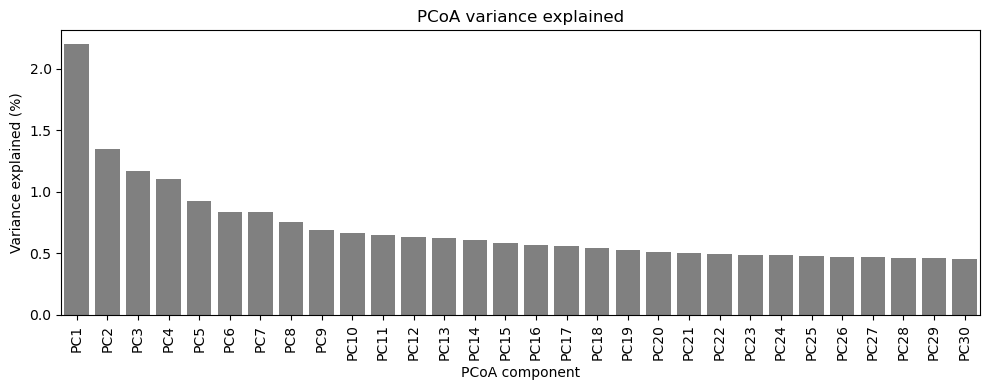

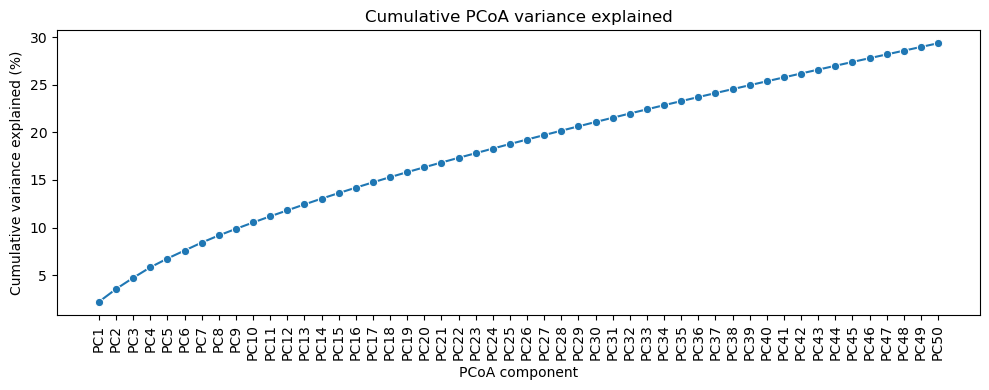

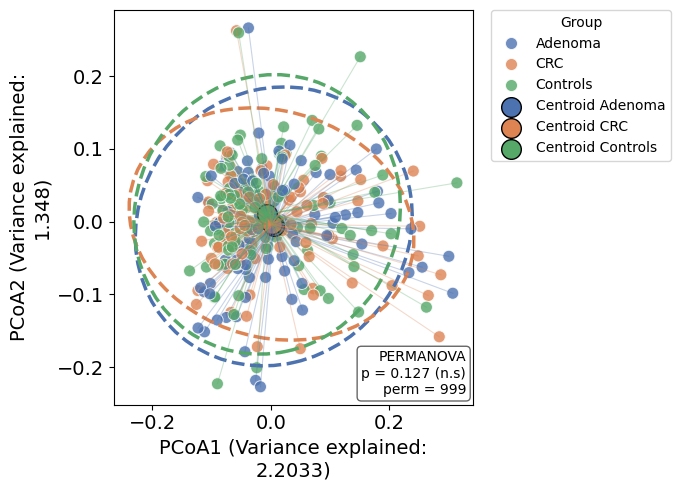

{'Groups': ['Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'Adenoma',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'CRC',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Controls',
  'Adenoma',
  'Adenoma',
  'Adenoma

In [56]:
plot_pcoa_pres_abs_with_centroids(
    dict_groups=sampleset.dict_groups,
    sampleset_bin=sampleset.sampleset_bin,
    path_output=os.path.join(PATH_OUTPUT, 'Dimensionality_Reduction_PCoA'),
    filename='PCoA_all_peptides_PC1_PC2',
    type_data='pres_abs',
    metric='jaccard',
    pc_axes=(1, 2),
    plot_pcoa=True
    )

### Generate PCoA for all possible peptides prevalence intervals (global) with minimum values that go from 0 to 30% and upper values that go from 100-70%

In [31]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def plot_permanova_heatmap_across_prevalence_thresholds(
    path_output=None,
    dict_results=None,
    intervals=None,
    filename_plot="Heatmap_PERMANOVA_res_across_prevalence_thresholds.svg",
    filename_table="Table_permanova_results.csv"
):
    """
    Plot PERMANOVA results across prevalence filtering intervals as a heatmap.

    Heatmap color:
        -log10(PERMANOVA p-value)

    Cell annotation:
        number of peptides used
        PERMANOVA p-value

    Parameters
    ----------
    path_output : str
        Output directory where the figure will be saved.

    dict_results : dict
        Dictionary containing results for each interval.
        Expected structure:
        dict_results[(min_val, max_val)]['Run_info']['permanova_results'].loc['p-value']
        dict_results[(min_val, max_val)]['Run_info']['peptides_used']

    intervals : list of tuple
        List of prevalence intervals, e.g. [(0.01, 0.99), (0.02, 0.98)].

    filename : str
        Name of the output SVG file.

    Returns
    -------
    df_permanova_test : pd.DataFrame
        Long-format dataframe with min threshold, max threshold, p-value and number of peptides.

    heatmap_data : pd.DataFrame
        Pivoted dataframe used for heatmap colors.

    output_file : str
        Full path of the saved figure.
    """

    print("######## PERMANOVA prevalence threshold heatmap ########")

    # Non-null checks
    if path_output is None:
        raise ValueError("path_output cannot be None.")

    if dict_results is None:
        raise ValueError("dict_results cannot be None.")

    if intervals is None:
        raise ValueError("intervals cannot be None.")

    if filename_plot is None or filename_table is None:
        raise ValueError("filename cannot be None.")

    os.makedirs(path_output, exist_ok=True)

    list_min_val = []
    list_max_val = []
    list_permanova_p = []
    list_peptides_num = []

    for min_val, max_val in intervals:
        try:
            run_info = dict_results[(min_val, max_val)]["Run_info"]

            permanova_p = run_info["permanova_results"].loc["p-value"]
            peptides_used = run_info["peptides_used"]

            list_permanova_p.append(float(permanova_p))
            list_min_val.append(min_val)
            list_max_val.append(max_val)
            list_peptides_num.append(peptides_used)

        except KeyError as e:
            raise KeyError(
                f"Missing result for interval ({min_val}, {max_val}) or missing key: {e}"
            )

    df_permanova_test = pd.DataFrame({
        "values_min": list_min_val,
        "values_max": list_max_val,
        "Permanova P": list_permanova_p,
        "num_peptides": list_peptides_num
    })

    df_plot = df_permanova_test.copy()

    # Avoid log10(0)
    df_plot["Permanova P"] = df_plot["Permanova P"].clip(
        lower=np.finfo(float).tiny
    )

    df_plot["neg_log10_p"] = -np.log10(df_plot["Permanova P"])

    # Pivot for heatmap colors
    heatmap_data = df_plot.pivot_table(
        columns="values_min",
        index="values_max",
        values="neg_log10_p",
        aggfunc="max"
    )

    # Pivot for peptide counts
    peptide_data = df_plot.pivot_table(
        columns="values_min",
        index="values_max",
        values="num_peptides",
        aggfunc="max"
    )

    # Pivot for original PERMANOVA p-values
    pvalue_data = df_plot.pivot_table(
        columns="values_min",
        index="values_max",
        values="Permanova P",
        aggfunc="min"
    )

    # Sort and align
    heatmap_data = heatmap_data.sort_index(ascending=False)
    heatmap_data = heatmap_data.sort_index(axis=1)

    peptide_data = peptide_data.reindex_like(heatmap_data)
    pvalue_data = pvalue_data.reindex_like(heatmap_data)

    # Annotation: number of peptides + p-value underneath
    peptide_labels = peptide_data.round(0).astype("Int64").astype(str)
    peptide_labels = peptide_labels.mask(peptide_data.isna(), "")

    pvalue_labels = pvalue_data.map(
        lambda x: f"{x:.1e}" if pd.notna(x) else ""
    )

    annot_labels = peptide_labels + pvalue_labels.map(
        lambda x: f"\n{x}" if x != "" else ""
    )

    plt.figure(figsize=(10, 10))

    ax = sns.heatmap(
        heatmap_data,
        cmap="viridis",
        annot=annot_labels,
        fmt="",
        annot_kws={"fontsize": 6},
        linewidths=0.1,
        linecolor="white",
        cbar_kws={"label": r"$-\log_{10}(\mathrm{PERMANOVA}\ p)$"}
    )

    ax.set_title(
        "PERMANOVA significance across prevalence filtering intervals",
        fontsize=15,
        pad=15
    )

    ax.set_xlabel("Minimum peptide prevalence cutoff")
    ax.set_ylabel("Maximum peptide prevalence cutoff")

    plt.xticks(rotation=45, ha="right", fontsize=8)
    plt.yticks(rotation=0, fontsize=8)

    plt.tight_layout()

    output_file_plot = os.path.join(path_output, filename_plot)

    plt.savefig(
        output_file_plot,
        facecolor="white",
        dpi=100,
        transparent=False,
        bbox_inches="tight"
    )

    output_file_table = os.path.join(path_output, filename_table)
    df_permanova_test.to_csv("Table_permanova_results.csv", index=False)

    print(f"Saved figure to: {output_file_plot}")

    return df_permanova_test, heatmap_data

In [32]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def plot_permanova_heatmap_across_prevalence_thresholds(
    path_output=None,
    dict_results=None,
    intervals=None,
    filename_plot="Heatmap_PERMANOVA_res_across_prevalence_thresholds.svg",
    filename_table="Table_permanova_results.csv",
    pvalue_annotation="pvalue",   # "pvalue", "stars", "both", "none"
    significance_levels=None
):
    """
    Plot PERMANOVA results across prevalence filtering intervals as a heatmap.

    Heatmap color:
        -log10(PERMANOVA p-value)

    Cell annotation:
        number of peptides used
        plus either p-value, stars, both, or nothing.

    Parameters
    ----------
    pvalue_annotation : str
        How to annotate p-values inside cells.

        Options:
        - "pvalue": number of peptides + actual p-value
        - "stars": number of peptides + significance stars
        - "both": number of peptides + p-value + stars
        - "none": only number of peptides

    significance_levels : list of tuple, optional
        Significance thresholds for stars.
        Default:
            p <= 0.001 : ***
            p <= 0.01  : **
            p <= 0.05  : *
    """

    print("######## PERMANOVA prevalence threshold heatmap ########")

    if path_output is None:
        raise ValueError("path_output cannot be None.")

    if dict_results is None:
        raise ValueError("dict_results cannot be None.")

    if intervals is None:
        raise ValueError("intervals cannot be None.")

    if filename_plot is None or filename_table is None:
        raise ValueError("filename_plot and filename_table cannot be None.")

    valid_annotation_modes = ["pvalue", "stars", "both", "none"]

    if pvalue_annotation not in valid_annotation_modes:
        raise ValueError(
            f"pvalue_annotation must be one of {valid_annotation_modes}. "
            f"Got: {pvalue_annotation}"
        )

    if significance_levels is None:
        significance_levels = [
            (0.001, "***"),
            (0.01, "**"),
            (0.05, "*")
        ]

    os.makedirs(path_output, exist_ok=True)

    list_min_val = []
    list_max_val = []
    list_permanova_p = []
    list_peptides_num = []

    for min_val, max_val in intervals:
        try:
            run_info = dict_results[(min_val, max_val)]["Run_info"]

            permanova_p = run_info["permanova_results"].loc["p-value"]
            peptides_used = run_info["peptides_used"]

            list_permanova_p.append(float(permanova_p))
            list_min_val.append(min_val)
            list_max_val.append(max_val)
            list_peptides_num.append(peptides_used)

        except KeyError as e:
            raise KeyError(
                f"Missing result for interval ({min_val}, {max_val}) or missing key: {e}"
            )

    df_permanova_test = pd.DataFrame({
        "values_min": list_min_val,
        "values_max": list_max_val,
        "Permanova P": list_permanova_p,
        "num_peptides": list_peptides_num
    })

    def p_to_stars(p):
        if pd.isna(p):
            return ""

        for threshold, stars in significance_levels:
            if p <= threshold:
                return stars

        return ""

    df_permanova_test["significance"] = df_permanova_test["Permanova P"].map(p_to_stars)

    df_plot = df_permanova_test.copy()

    # Avoid log10(0) for the heatmap color
    df_plot["Permanova P clipped"] = df_plot["Permanova P"].clip(
        lower=np.finfo(float).tiny
    )

    df_plot["neg_log10_p"] = -np.log10(df_plot["Permanova P clipped"])

    # Pivot for heatmap colors
    heatmap_data = df_plot.pivot_table(
        columns="values_min",
        index="values_max",
        values="neg_log10_p",
        aggfunc="max"
    )

    # Pivot for peptide counts
    peptide_data = df_plot.pivot_table(
        columns="values_min",
        index="values_max",
        values="num_peptides",
        aggfunc="max"
    )

    # Pivot for original PERMANOVA p-values
    pvalue_data = df_plot.pivot_table(
        columns="values_min",
        index="values_max",
        values="Permanova P",
        aggfunc="min"
    )

    # Pivot for significance stars
    stars_data = df_plot.pivot_table(
        columns="values_min",
        index="values_max",
        values="significance",
        aggfunc="first"
    )

    # Sort and align
    heatmap_data = heatmap_data.sort_index(ascending=False)
    heatmap_data = heatmap_data.sort_index(axis=1)

    peptide_data = peptide_data.reindex_like(heatmap_data)
    pvalue_data = pvalue_data.reindex_like(heatmap_data)
    stars_data = stars_data.reindex_like(heatmap_data)

    # ---------------------------------------------------------
    # Build annotation labels
    # ---------------------------------------------------------
    peptide_labels = peptide_data.round(0).astype("Int64").astype(str)
    peptide_labels = peptide_labels.mask(peptide_data.isna(), "")

    pvalue_labels = pvalue_data.map(
        lambda x: f"{x:.1e}" if pd.notna(x) else ""
    )

    stars_labels = stars_data.fillna("")

    if pvalue_annotation == "pvalue":
        annot_labels = peptide_labels + pvalue_labels.map(
            lambda x: f"\n{x}" if x != "" else ""
        )

    elif pvalue_annotation == "stars":
        annot_labels = peptide_labels + stars_labels.map(
            lambda x: f"\n{x}" if x != "" else ""
        )

    elif pvalue_annotation == "both":
        combined_p_labels = pvalue_labels + stars_labels.map(
            lambda x: f" {x}" if x != "" else ""
        )

        annot_labels = peptide_labels + combined_p_labels.map(
            lambda x: f"\n{x}" if x != "" else ""
        )

    elif pvalue_annotation == "none":
        annot_labels = peptide_labels

    # ---------------------------------------------------------
    # Plot
    # ---------------------------------------------------------
    plt.figure(figsize=(12, 10))

    ax = sns.heatmap(
        heatmap_data,
        cmap="viridis",
        annot=annot_labels,
        fmt="",
        annot_kws={"fontsize": 6},
        linewidths=0.1,
        linecolor="white",
        cbar_kws={"label": r"$-\log_{10}(\mathrm{PERMANOVA}\ p)$"}
    )

    ax.set_title(
        "PERMANOVA significance across prevalence filtering intervals",
        fontsize=15,
        pad=15
    )

    ax.set_xlabel("Minimum peptide prevalence cutoff")
    ax.set_ylabel("Maximum peptide prevalence cutoff")

    plt.xticks(rotation=45, ha="right", fontsize=8)
    plt.yticks(rotation=0, fontsize=8)

    plt.tight_layout()

    output_file_plot = os.path.join(path_output, filename_plot)

    plt.savefig(
        output_file_plot,
        facecolor="white",
        dpi=100,
        transparent=False,
        bbox_inches="tight"
    )

    output_file_table = os.path.join(path_output, filename_table)
    df_permanova_test.to_csv(output_file_table, index=False)

    print(f"Saved figure to: {output_file_plot}")
    print(f"Saved table to: {output_file_table}")

    return df_permanova_test, heatmap_data

In [ ]:
from itertools import product
min_values = [round(x / 100, 2) for x in range(1, 31)]      # 0.01 to 0.30
max_values = [round(x / 100, 2) for x in range(99, 69, -1)] # 0.99 to 0.70
intervals = [(min_val, max_val) for min_val, max_val in product(min_values, max_values)]
len(intervals)
    

dict_results = {}
for (min_val, max_val) in intervals:
    sampleset_bin = sampleset.sampleset_bin[((sampleset.sampleset_bin.sum(axis=1)/sampleset.sampleset_bin.shape[1]) > min_val) &
                            ((sampleset.sampleset_bin.sum(axis=1)/sampleset.sampleset_bin.shape[1]) <= max_val)]
    pcoa_dict = plot_pcoa_pres_abs_with_centroids(
    dict_groups=sampleset.dict_groups,
    sampleset_bin=sampleset_bin,
    path_output=os.path.join(PATH_OUTPUT, 'Dimensionality_Reduction_PCoA'),
    filename=f'PCoA_PC1_PC2_interval_{str(min_val)}_{str(max_val)}',
    type_data='pres_abs',
    metric='jaccard',
    pc_axes=(1, 2),
    plot_pcoa=False
    )
    dict_results[(min_val, max_val)] = pcoa_dict


# # sampleset.sampleset_bin.shape[1]

######## PERMANOVA prevalence threshold heatmap ########
Saved figure to: /Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/Final_output/Dimensionality_Reduction_PCoA/Heatmap_PERMANOVA_res_across_prevalence_thresholds.svg
Saved table to: /Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/Final_output/Dimensionality_Reduction_PCoA/Table_permanova_results.csv


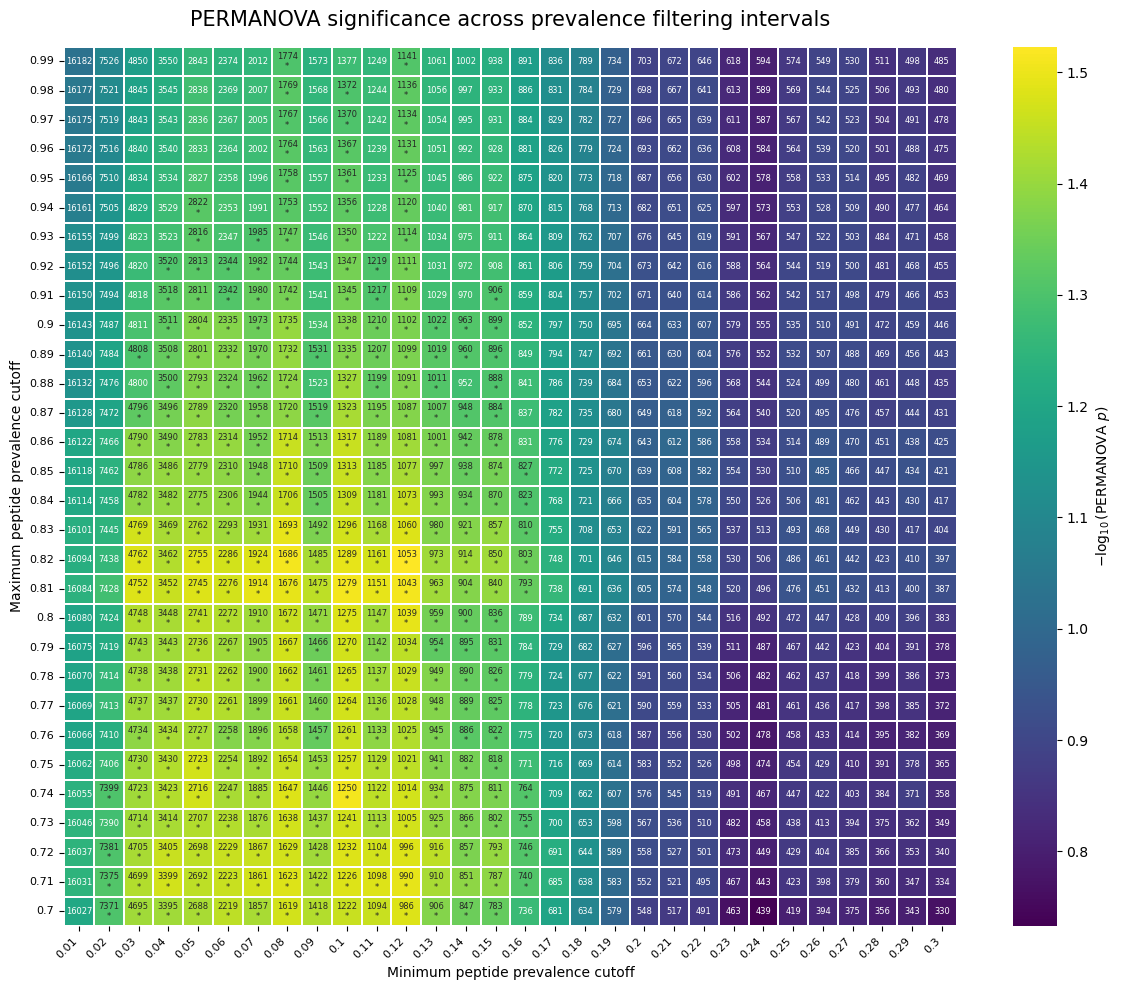

In [57]:
df_permanova_test, heatmap_data = plot_permanova_heatmap_across_prevalence_thresholds(
    path_output=os.path.join(PATH_OUTPUT, "Dimensionality_Reduction_PCoA"),
    dict_results=dict_results,
    intervals=intervals,
    filename_plot="Heatmap_PERMANOVA_res_across_prevalence_thresholds.svg",
    filename_table="Table_permanova_results.csv",
    pvalue_annotation="stars"
)


######## PCOA ########
Plotting PC1 vs PC2
method name               PERMANOVA
test statistic name        pseudo-F
sample size                     311
number of groups                  3
test statistic             1.110303
p-value                       0.033
number of permutations          999
Name: PERMANOVA results, dtype: object


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/3560608605.py:204: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/3560608605.py:204: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/3560608605.py:204: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


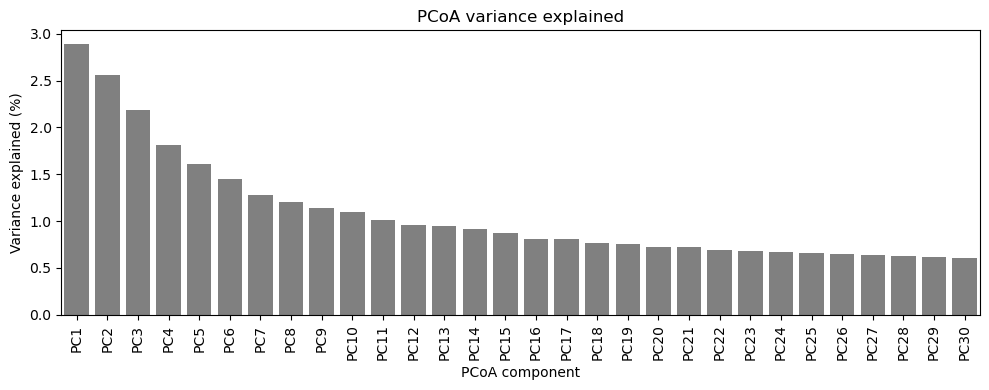

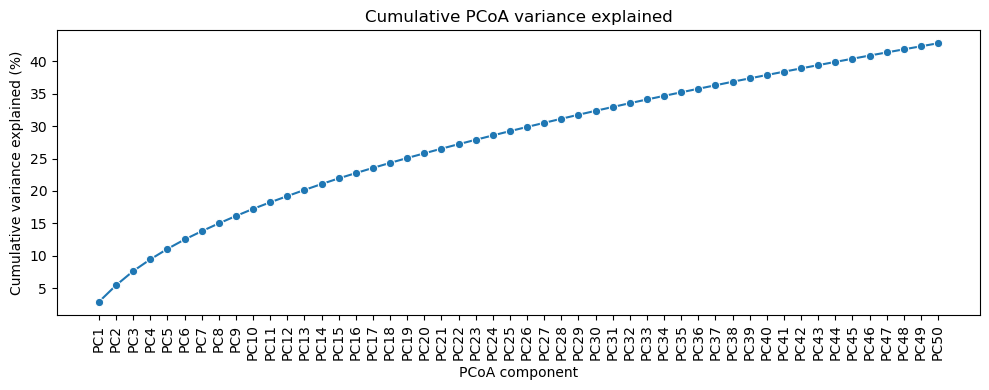

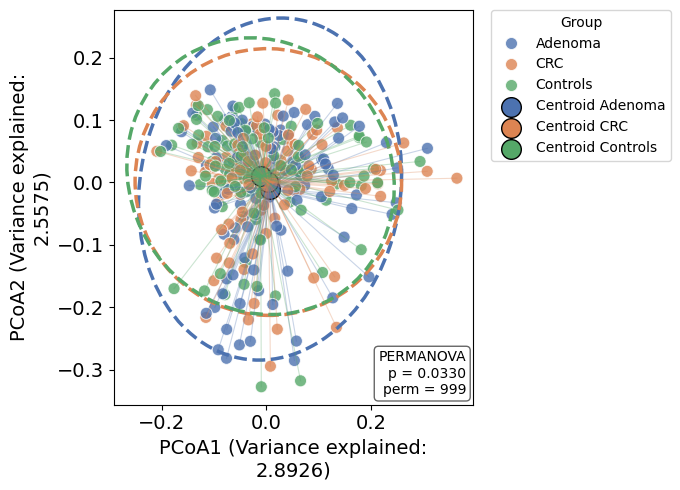

In [58]:
## Produce PCoA also with this threshold: 0.03 - 0.81
sampleset_bin = sampleset.sampleset_bin[((sampleset.sampleset_bin.sum(axis=1)/sampleset.sampleset_bin.shape[1]) > 0.03) &
                            ((sampleset.sampleset_bin.sum(axis=1)/sampleset.sampleset_bin.shape[1]) <= 0.81)]

pcoa_dict = plot_pcoa_pres_abs_with_centroids(
    dict_groups=sampleset.dict_groups,
    sampleset_bin=sampleset_bin,
    path_output=os.path.join(PATH_OUTPUT, 'Dimensionality_Reduction_PCoA'),
    filename='PCoA_3-81_prevalence_PC1_PC2',
    type_data='pres_abs',
    metric='jaccard',
    pc_axes=(1, 2),
    plot_pcoa=True
    )


## Check first PCoA components and plot an umap to see if we can get some clusters

In [60]:
## Check UMAP using first 10 components
def plot_umap_from_pcoa(
    pcoa_object,
    n_components=10,
    path_output=None,
    filename=None,
    group_color_dict=None,
    n_neighbors=15,
    min_dist=0.3,
    random_state=42
):
    import os
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    import umap

    pcoa_df = pcoa_object["Pcoa_dataframe"].copy()

    pc_cols = [f"PC{i}" for i in range(1, n_components + 1)]

    missing_cols = [col for col in pc_cols if col not in pcoa_df.columns]
    if missing_cols:
        raise ValueError(f"Missing PCoA components: {missing_cols}")

    umap_input = pcoa_df[pc_cols].copy()

    reducer = umap.UMAP(
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        metric="euclidean",
        random_state=random_state
    )

    umap_coords = reducer.fit_transform(umap_input)

    umap_df = pd.DataFrame(
        umap_coords,
        columns=["UMAP1", "UMAP2"],
        index=pcoa_df.index
    )

    umap_df["Group"] = pcoa_df["Group"].values

    if group_color_dict is None:
        group_color_dict = {
            "Controls": "#55A868",
            "Adenoma": "#4C72B0",
            "CRC": "#DD8452"
        }

    plt.figure(figsize=(5, 5))

    ax = sns.scatterplot(
        data=umap_df,
        x="UMAP1",
        y="UMAP2",
        hue="Group",
        palette=group_color_dict,
        s=75,
        alpha=0.8
    )

    ax.set_title(f"UMAP from first {n_components} PCoA components")
    ax.set_xlabel("UMAP1", fontsize=14)
    ax.set_ylabel("UMAP2", fontsize=14)
    ax.tick_params(axis="both", labelsize=12)

    ax.legend(
        title="Group",
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
        borderaxespad=0.
    )

    if path_output is not None:
        if filename is None:
            filename = f"UMAP_from_first_{n_components}_PCoA_components"

        umap_df.to_csv(
            os.path.join(path_output, f"{filename}.csv")
        )

        plt.savefig(
            os.path.join(path_output, f"{filename}.svg"),
            dpi=300,
            facecolor="white",
            bbox_inches="tight"
        )

    plt.show()

    return umap_df


/Users/gabrielinnocenti/miniconda3/envs/phipseq_data_analysis/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Samples with 'Sex': 311/311
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


/Users/gabrielinnocenti/miniconda3/envs/phipseq_data_analysis/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



Samples with 'group_test': 311/311
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


/Users/gabrielinnocenti/miniconda3/envs/phipseq_data_analysis/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



Samples with 'Age': 311/311


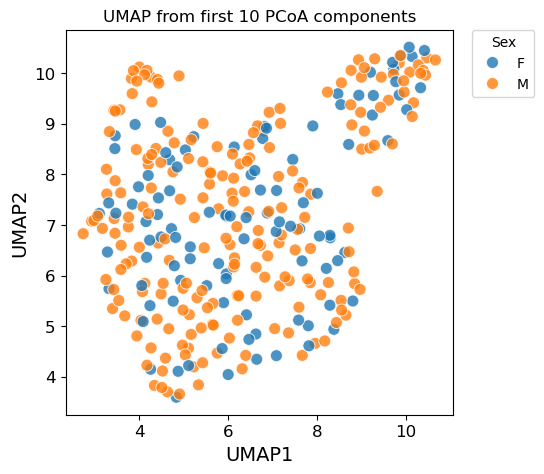

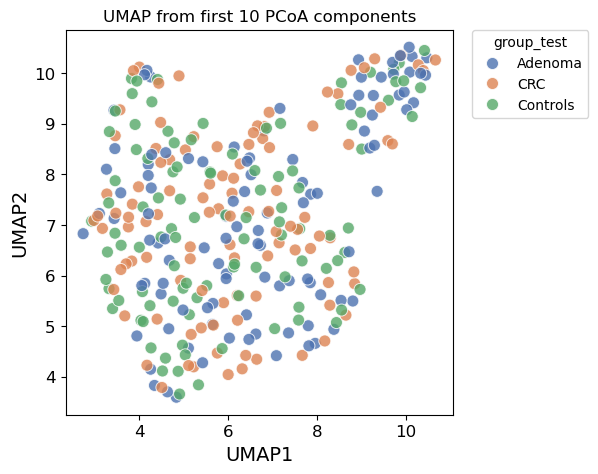

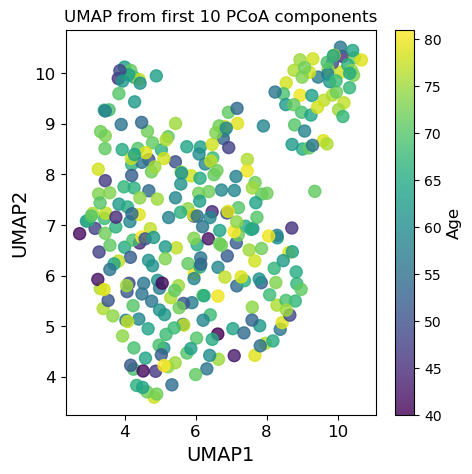

In [61]:
def plot_umap_from_pcoa(
    pcoa_object,
    n_components=10,
    path_output=None,
    filename=None,
    metadata_df=None,
    color_by="group_test",
    metadata_sample_col="SampleName",
    pcoa_sample_col="Sample",
    group_color_dict=None,
    n_neighbors=15,
    min_dist=0.3,
    random_state=42
):
    import os
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    import umap

    pcoa_df = pcoa_object["Pcoa_dataframe"].copy()
    pcoa_df.index = pcoa_df.index.astype(str)

    pc_cols = [f"PC{i}" for i in range(1, n_components + 1)]

    missing_cols = [col for col in pc_cols if col not in pcoa_df.columns]
    if missing_cols:
        raise ValueError(f"Missing PCoA components: {missing_cols}")

    umap_input = pcoa_df[pc_cols].copy()

    reducer = umap.UMAP(
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        metric="euclidean",
        random_state=random_state
    )

    umap_coords = reducer.fit_transform(umap_input)

    umap_df = pd.DataFrame(
        umap_coords,
        columns=["UMAP1", "UMAP2"],
        index=pcoa_df.index
    )

    umap_df.index.name = pcoa_sample_col
    umap_df[pcoa_sample_col] = umap_df.index

    # ---------------------------------------------------------
    # Add metadata
    # ---------------------------------------------------------
    if metadata_df is not None:
        metadata_df = metadata_df.copy()

        if metadata_sample_col not in metadata_df.columns:
            raise ValueError(
                f"'{metadata_sample_col}' was not found in metadata_df. "
                f"Available columns are: {list(metadata_df.columns)}"
            )

        if color_by not in metadata_df.columns:
            raise ValueError(
                f"'{color_by}' was not found in metadata_df. "
                f"Available columns are: {list(metadata_df.columns)}"
            )

        metadata_df[metadata_sample_col] = metadata_df[metadata_sample_col].astype(str)

        metadata_to_join = metadata_df.set_index(metadata_sample_col)

        metadata_to_join = metadata_to_join.loc[
            ~metadata_to_join.index.duplicated(keep="first")
        ]

        # Drop columns from metadata that already exist in umap_df
        # This avoids: ValueError: columns overlap but no suffix specified
        overlapping_cols = metadata_to_join.columns.intersection(umap_df.columns)

        metadata_to_join = metadata_to_join.drop(
            columns=overlapping_cols,
            errors="ignore"
        )

        umap_df = umap_df.join(metadata_to_join, how="left")

        n_missing = umap_df[color_by].isna().sum()
        n_total = len(umap_df)

        print(f"Samples with '{color_by}': {n_total - n_missing}/{n_total}")

        if n_missing == n_total:
            raise ValueError(
                f"All values for '{color_by}' are missing after joining metadata. "
                f"Check whether pcoa_df.index matches metadata_df['{metadata_sample_col}']."
            )

        hue_col = color_by

    else:
        if "Group" not in pcoa_df.columns:
            raise ValueError(
                "metadata_df was not provided and 'Group' was not found "
                "in pcoa_object['Pcoa_dataframe']."
            )

        umap_df["Group"] = pcoa_df["Group"].values
        hue_col = "Group"

    if group_color_dict is None:
        group_color_dict = {
            "Controls": "#55A868",
            "Adenoma": "#4C72B0",
            "CRC": "#DD8452"
        }

    plt.figure(figsize=(5, 5))

    is_numeric = pd.api.types.is_numeric_dtype(umap_df[hue_col])

    if is_numeric:
        plot_df = umap_df.dropna(subset=[hue_col]).copy()
        ax = plt.gca()

        scatter = ax.scatter(
            plot_df["UMAP1"],
            plot_df["UMAP2"],
            c=plot_df[hue_col],
            s=75,
            alpha=0.8
        )

        cbar = plt.colorbar(scatter, ax=ax)
        cbar.set_label(hue_col, fontsize=12)

    else:
        plot_df = umap_df.copy()
        plot_df[hue_col] = plot_df[hue_col].fillna("Missing")

        categories = plot_df[hue_col].dropna().unique()

        if all(cat in group_color_dict for cat in categories):
            palette = group_color_dict
        else:
            palette = None

        ax = sns.scatterplot(
            data=plot_df,
            x="UMAP1",
            y="UMAP2",
            hue=hue_col,
            palette=palette,
            s=75,
            alpha=0.8
        )

        ax.legend(
            title=hue_col,
            bbox_to_anchor=(1.05, 1),
            loc="upper left",
            borderaxespad=0.
        )

    ax.set_title(f"UMAP from first {n_components} PCoA components")
    ax.set_xlabel("UMAP1", fontsize=14)
    ax.set_ylabel("UMAP2", fontsize=14)
    ax.tick_params(axis="both", labelsize=12)

    if path_output is not None:
        os.makedirs(path_output, exist_ok=True)

        if filename is None:
            safe_hue_col = str(hue_col).replace(" ", "_")
            filename = (
                f"UMAP_from_first_{n_components}_PCoA_components_"
                f"colored_by_{safe_hue_col}"
            )

        umap_df.to_csv(os.path.join(path_output, f"{filename}.csv"))

        plt.savefig(
            os.path.join(path_output, f"{filename}.svg"),
            dpi=300,
            facecolor="white",
            bbox_inches="tight"
        )
        # plt.tight_layout()

    return umap_df

umap_df = plot_umap_from_pcoa(
    n_components=10,
    pcoa_object=pcoa_dict,
    metadata_df=sampleset.sample_sheet,
    metadata_sample_col="SampleName",
    color_by="Sex"
)

umap_df = plot_umap_from_pcoa(
    n_components=10,
    pcoa_object=pcoa_dict,
    metadata_df=sampleset.sample_sheet,
    metadata_sample_col="SampleName",
    color_by="group_test"
)

umap_df = plot_umap_from_pcoa(
    n_components=10,
    pcoa_object=pcoa_dict,
    metadata_df=sampleset.sample_sheet,
    metadata_sample_col="SampleName",
    color_by="Age"
)



In [62]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score


def add_umap_clusters(
    umap_df,
    eps=0.45,
    min_samples=5,
    cluster_col="UMAP_cluster"
):
    umap_df = umap_df.copy()

    coords = umap_df[["UMAP1", "UMAP2"]].copy()

    clustering = DBSCAN(
        eps=eps,
        min_samples=min_samples
    ).fit(coords)

    umap_df[cluster_col] = clustering.labels_

    return umap_df

# umap_df_clustered = add_umap_clusters(
#     umap_df,
#     eps=0.5,
#     min_samples=5
# )

# umap_df_clustered["UMAP_cluster"].value_counts()
eps_values = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
clusterings = {}
for eps in eps_values:
    tmp = add_umap_clusters(umap_df, eps=eps, min_samples=5)
    clusterings[eps] = tmp["UMAP_cluster"]

# Use adjusted randomic index to define the cluster entity
for eps1, eps2 in zip(eps_values[:-1], eps_values[1:]):
    ari = adjusted_rand_score(
        clusterings[eps1],
        clusterings[eps2]
    )
    print(f"eps {eps1:.2f} vs {eps2:.2f}: ARI = {ari:.3f}")



eps 0.25 vs 0.30: ARI = 0.348
eps 0.30 vs 0.35: ARI = 0.384
eps 0.35 vs 0.40: ARI = 0.320
eps 0.40 vs 0.45: ARI = 0.230
eps 0.45 vs 0.50: ARI = 0.506
eps 0.50 vs 0.55: ARI = 1.000
eps 0.55 vs 0.60: ARI = 1.000
eps 0.60 vs 0.65: ARI = 1.000
eps 0.65 vs 0.70: ARI = 1.000


### Using Species level to perform again the PCoA. In this case we consider species presence if across all dataset, >5 peptides of that species were detected

######## PCOA ########
Plotting PC1 vs PC2


/Users/gabrielinnocenti/miniconda3/envs/phipseq_data_analysis/lib/python3.9/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:146: RuntimeWarning:

The result contains negative eigenvalues. Please compare their magnitude with the magnitude of some of the largest positive eigenvalues. If the negative ones are smaller, it's probably safe to ignore them, but if they are large in magnitude, the results won't be useful. See the Notes section for more details. The smallest eigenvalue is -0.041405029313904045 and the largest is 5.207012726880939.



method name               PERMANOVA
test statistic name        pseudo-F
sample size                     311
number of groups                  3
test statistic             0.975407
p-value                       0.521
number of permutations          999
Name: PERMANOVA results, dtype: object


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/3560608605.py:204: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/3560608605.py:204: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/3560608605.py:204: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


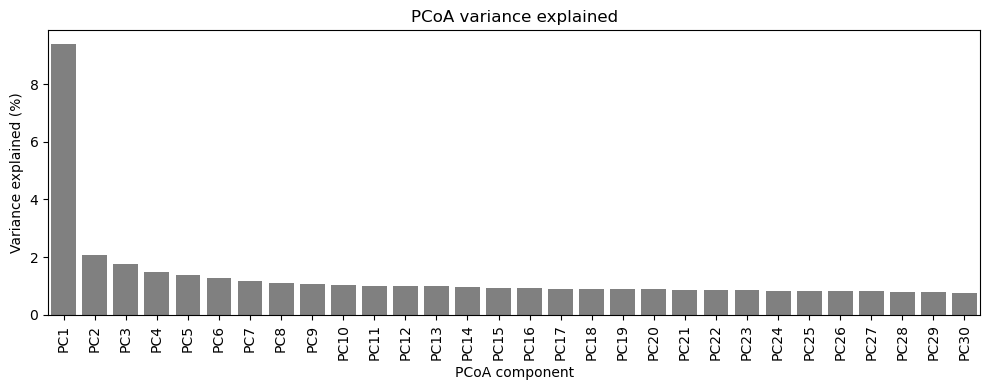

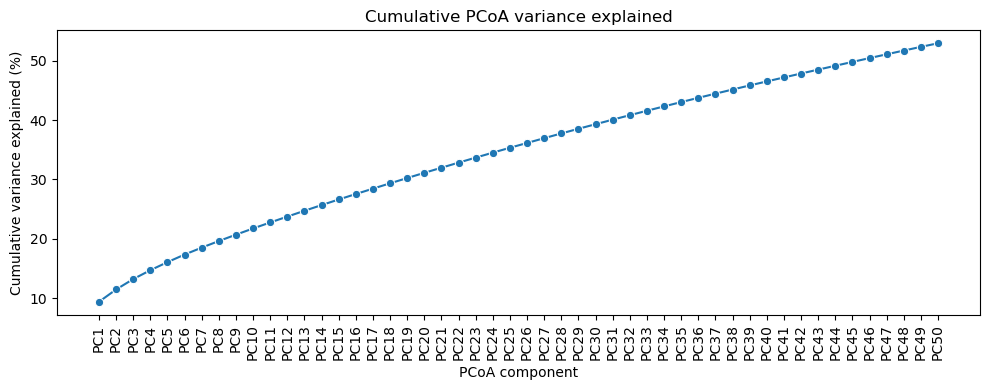

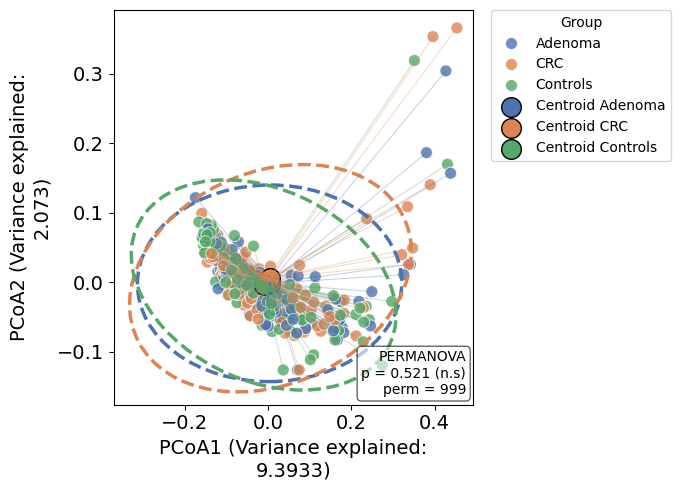

In [63]:
# Collapsing to species level
sampleset_bin = sampleset.sampleset_bin.copy()
sampleset_bin = sampleset_bin.reset_index()
sampleset_bin.columns
libraries = sampleset.libraries
# # Reorder columns
# sampleset_bin.reset_index(inplace=True)

# build peptide_name → species map from all libraries
species_map = pd.concat([
    lib[['peptide_name', 'species']]
    for lib in libraries
    if 'species' in lib.columns
], ignore_index=True)

species_map = (
    species_map
    .dropna(subset=['species'])
    .drop_duplicates('peptide_name')
)

# add species to wide matrix
df_peptides_species = sampleset_bin.merge(
    species_map,
    on='peptide_name',
    how='left'
)

# identify sample columns: everything except annotation/id columns
non_sample_cols = ['peptide_name', 'species']
sample_cols = [c for c in df_peptides_species.columns if c not in non_sample_cols]

# collapse to species level
species_cnt = (
    df_peptides_species
    .dropna(subset=['species'])
    .groupby('species', as_index=False)[sample_cols]
    .sum()
)

species_cnt = species_cnt.set_index('species')
species_bin = (species_cnt > 0).astype(int)


species_total_counts = df_peptides_species.groupby('species')['peptide_name'].count()
species_to_keep = species_total_counts[species_total_counts > 5].index

species_bin_filter_species = species_bin.loc[species_to_keep]
species_bin_filter_species.to_csv(os.path.join(PATH_OUTPUT, 'species_presence_absence_filtered.csv'), index=True)

# plot_population_wise_antigenic_frequency(df_bin=species_bin, group_colors=group_colors, group_names=group_names, filename='species_based_frequency', level='species')
pcoa_species_dict = plot_pcoa_pres_abs_with_centroids(dict_groups=sampleset.dict_groups, 
                                                      sampleset_bin=species_bin_filter_species, 
                                                      path_output=os.path.join(PATH_OUTPUT, 'Dimensionality_Reduction_PCoA'), 
                                                      filename='PCoA_species_PC1_PC2', 
                                                      type_data='pres_abs')



######## Prevalence distribution - Scatterplot - Delta prevalence ########
Selected threshold is 5
PRE STATISTICS (BEFORE CHI-SQ)
Number of peptides with prevalence equal to 0 in Controls: 28
Number of peptides with prevalence equal to 0 in Adenoma: 26
PRE PLOTTING Scatterplots
Number of peptides with prevalence equal to 0 in Controls: 28
Number of peptides with prevalence equal to 0 in Adenoma: 26


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/544982328.py:150: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/544982328.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



        peptide_name   Controls    Adenoma  pvals_not_corr  passed_bh  pvals  \
0       agilent_2111  11.764706   2.857143        0.037082      False    1.0   
1      corona2_13099  24.509804  18.095238        0.345780      False    1.0   
2        twist_10996  10.784314   6.666667        0.440128      False    1.0   
3        twist_35986   8.823529   4.761905        0.401241      False    1.0   
4       agilent_2513   5.882353   2.857143        0.504206      False    1.0   
...              ...        ...        ...             ...        ...    ...   
3587   corona2_11072  14.705882   3.809524        0.017860      False    1.0   
3588    agilent_7930   6.862745   7.619048        1.000000      False    1.0   
3589      twist_7048   3.921569   5.714286        0.805248      False    1.0   
3590  agilent_221881   6.862745   6.666667        1.000000      False    1.0   
3591   corona2_13090  81.372549  86.666667        0.405133      False    1.0   

     Significant_bh Significant     rat

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/544982328.py:150: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/544982328.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



        peptide_name   Controls        CRC  pvals_not_corr  passed_bh  pvals  \
0       agilent_2111  11.764706  10.576923        0.959535      False    1.0   
1      corona2_13099  24.509804  14.423077        0.104862      False    1.0   
2        twist_10996  10.784314  12.500000        0.874739      False    1.0   
3        twist_35986   8.823529   6.730769        0.772754      False    1.0   
4       agilent_2513   5.882353   3.846154        0.740429      False    1.0   
...              ...        ...        ...             ...        ...    ...   
3107  agilent_242789   8.823529   9.615385        1.000000      False    1.0   
3108   corona2_11072  14.705882   5.769231        0.069338      False    1.0   
3109    agilent_7930   6.862745   4.807692        0.753869      False    1.0   
3110  agilent_221881   6.862745   5.769231        0.969465      False    1.0   
3111   corona2_13090  81.372549  74.038462        0.282253      False    1.0   

     Significant_bh Significant     rat

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/544982328.py:150: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/544982328.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



        peptide_name    Adenoma        CRC  pvals_not_corr  passed_bh  pvals  \
0       agilent_2111   2.857143  10.576923        0.065882      False    1.0   
1      corona2_13099  18.095238  14.423077        0.604737      False    1.0   
2        twist_10996   6.666667  12.500000        0.250560      False    1.0   
3        twist_35986   4.761905   6.730769        0.768239      False    1.0   
4      agilent_39198  88.571429  85.576923        0.669529      False    1.0   
...              ...        ...        ...             ...        ...    ...   
2667  agilent_242789  16.190476   9.615385        0.241368      False    1.0   
2668   corona2_11072   3.809524   5.769231        0.753587      False    1.0   
2669    agilent_7930   7.619048   4.807692        0.605332      False    1.0   
2670  agilent_221881   6.666667   5.769231        1.000000      False    1.0   
2671   corona2_13090  86.666667  74.038462        0.037263      False    1.0   

     Significant_bh Significant     rat

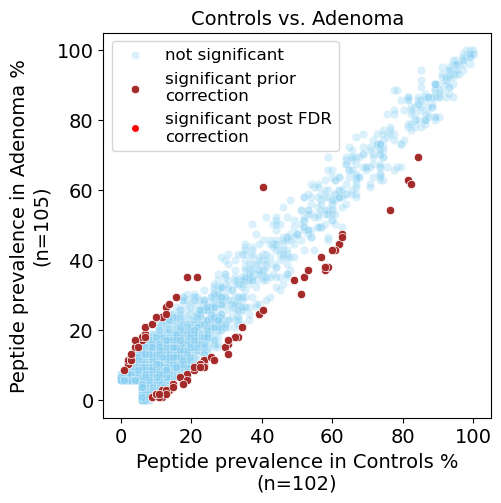

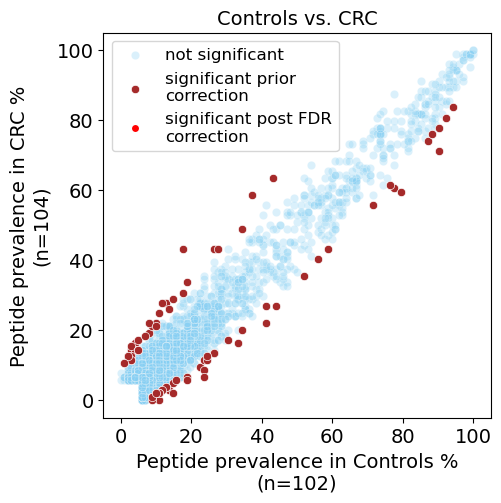

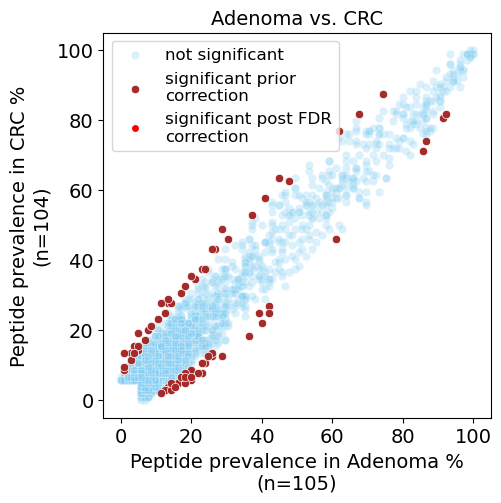

In [ ]:
from scipy.stats import chi2_contingency
from scipy.stats import mannwhitneyu
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

def scatterplots_and_prevalence_tables(df_prevalences, df_counts, dict_groups_list, group_pair_list, dict_group_counts, libraries, path_output, threshold=0, add_permutations=False, scatterplot_kwargs=None, save_kwargs=None):
    print('######## Prevalence distribution - Scatterplot - Delta prevalence ########')
    print(f'Selected threshold is {threshold}')
    dict_pair_groups = {}
    dict_pair_groups_shuffled = {}
    group_pair_list = combinations(dict_groups_list.keys(), r=2)
    dict_pairs_summary = {}
    for group1, group2 in combinations(dict_groups_list.keys(), r=2):
        # self.group_pair_list = combinations(self.dict_groups_list.keys(), r=2)
        ##############################
        #### Seaborn Scatterplots ####
        ##############################
        # First get the significant ones:
        # Calculate contingency table
        # df_prevalences = self.df_prevalences
        # df_counts = self.df_counts
        df_prevalences = df_prevalences[(df_prevalences[group1] >= threshold) | (df_prevalences[group2] >= threshold)]
        df_counts = df_counts.loc[df_prevalences.index, :]
        df_preval_combination = df_prevalences[[group1, group2]].copy()
        print('PRE STATISTICS (BEFORE CHI-SQ)')
        print(f'Number of peptides with prevalence equal to 0 in {group1}: {len(df_preval_combination[df_preval_combination[group1] == 0])}')
        print(f'Number of peptides with prevalence equal to 0 in {group2}: {len(df_preval_combination[df_preval_combination[group2] == 0])}')

        pvals_chisq = []
        for val1,val2 in df_counts[[group1,group2]].values:
            if val1 == 0:
                val1 = 1
            if val2 == 0:
                val2 = 1
            chitable = [[val1 + 1, dict_group_counts[group1] - val1 + 1], [val2 + 1, dict_group_counts[group2] - val2 + 1]]
            # Perform chi-squared test
            chi2_statistic, p_value, _, _ = chi2_contingency(chitable)
            pvals_chisq.append(p_value)
        

        df_preval_combination['pvals_not_corr'] = pvals_chisq
        df_preval_combination['passed_bh'],df_preval_combination['pvals'], _, _ = multipletests(pvals_chisq, method='fdr_bh')
        df_preval_combination['Significant_bh'] = np.where(df_preval_combination['passed_bh'] == True, 'Yes','No')
        df_preval_combination['Significant'] = np.where(df_preval_combination['pvals_not_corr'] < 0.05, 'Yes','No')
        # Calculate ratios
        ratio_vals = []
        for val1,val2 in df_preval_combination[[group1, group2]].values:
            if val1 == 0 or val2 == 0:
                ratio_vals.append(np.nan)
            else:
                if val1 >= val2:
                    ratio_vals.append(val1/val2 - 1)
                else:
                    ratio_vals.append(-(val2/val1 - 1))
        df_preval_combination['ratio'] = df_preval_combination[group1] / df_preval_combination[group2]
        df_preval_combination['Delta'] = df_preval_combination[group1] - df_preval_combination[group2]
        df_preval_combination['Delta_ratio'] = ratio_vals
        

        # # Shuffle the dataframe
        df_preval_combination_table_shuffled = df_preval_combination.copy()

        peptide_names = df_preval_combination_table_shuffled.index
        df_preval_combination_table_shuffled = df_preval_combination_table_shuffled.reset_index()
        df_preval_combination_table_shuffled.drop(columns='peptide_name', inplace=True)
        # 
        df_preval_combination_table_shuffled = df_preval_combination_table_shuffled.sample(n=len(df_preval_combination_table_shuffled))
        
        df_preval_combination_table_shuffled.index = peptide_names       
        # Reorder columns
        df_preval_combination.reset_index(inplace=True)

        meta_cols = [
            'Description', 'domain', 'kingdom', 'phylum', 'class', 'order',
            'family', 'genus', 'species', 'common'
        ]

        lib0_extra = [
            'is_IEDB_or_cntrl', 'is_auto', 'is_infect', 'is_EBV', 'is_toxin',
            'is_PNP', 'is_EM', 'is_MPA', 'is_patho', 'is_probio', 'is_IgA',
            'is_flagellum', 'signalp6_slow', 'is_topgraph_new'
        ]

        lib1_extra = ['is_phage', 'is_allergens', 'is_influenza']

        all_annotation_cols = meta_cols + lib0_extra + lib1_extra

        # start from sampleset_bin but remove old annotation columns if present
        df = df_preval_combination.drop(
            columns=[c for c in all_annotation_cols if c in df_preval_combination.columns],
            errors='ignore'
        ).copy()

        # merge lib0 first
        df = df.merge(
            libraries[0][['peptide_name'] + meta_cols + lib0_extra].drop_duplicates('peptide_name'),
            on='peptide_name',
            how='left'
        )

        # merge lib1
        df = df.merge(
            libraries[1][['peptide_name'] + meta_cols + lib1_extra].drop_duplicates('peptide_name'),
            on='peptide_name',
            how='left',
            suffixes=('', '_lib1')
        )

        # merge lib2
        df = df.merge(
            libraries[2][['peptide_name'] + meta_cols].drop_duplicates('peptide_name'),
            on='peptide_name',
            how='left',
            suffixes=('', '_lib2')
        )

        # fill missing metadata from lib1/lib2
        for col in meta_cols:
            if f'{col}_lib1' in df.columns:
                df[col] = df[col].combine_first(df[f'{col}_lib1'])
            if f'{col}_lib2' in df.columns:
                df[col] = df[col].combine_first(df[f'{col}_lib2'])

        # drop helper columns
        df_preval_combination = df.drop(columns=[c for c in df.columns if c.endswith('_lib1') or c.endswith('_lib2')])
        # df_preval_combination_table_shuffled_above = df_preval_combination_table_shuffled[df_preval_combination_table_shuffled['Delta_ratio'] >= 0 ].sort_values(by='pvals_not_corr', ascending=True)
        # df_preval_combination_table_shuffled_below= df_preval_combination_table_shuffled[df_preval_combination_table_shuffled['Delta_ratio'] < 0 ].sort_values(by='pvals_not_corr', ascending=False)
        # df_preval_combination_table_shuffled = pd.concat([df_preval_combination_table_shuffled_above, df_preval_combination_table_shuffled_below])

        # Get labels for df_preval_combination
        significant = df_preval_combination[df_preval_combination['Significant'] == 'Yes'].copy()
        not_significant = df_preval_combination[df_preval_combination['Significant'] == 'No'].copy()
        significant_bh = df_preval_combination[df_preval_combination['passed_bh'] == True].copy()

        # # Get labels for df_preval_combination_shuffled
        # significant_shuffled = df_preval_combination_table_shuffled[df_preval_combination_table_shuffled['Significant'] == 'Yes']
        # not_significant_shuffled = df_preval_combination_table_shuffled[df_preval_combination_table_shuffled['Significant'] == 'No']
        # significant_bh_shuffled = df_preval_combination_table_shuffled[df_preval_combination_table_shuffled['passed_bh'] == True]
        print('PRE PLOTTING Scatterplots')
        print(f'Number of peptides with prevalence equal to 0 in {group1}: {len(df_preval_combination[df_preval_combination[group1] == 0])}')
        print(f'Number of peptides with prevalence equal to 0 in {group2}: {len(df_preval_combination[df_preval_combination[group2] == 0])}')

        # Plot scatterplots
        plt.figure(figsize=(5,5))
        ax = sns.scatterplot(data=not_significant, x=group1, y=group2, color="#86CFF3", alpha=0.3, label='not significant')  #, **scatterplot_kwargs)
        sns.scatterplot(data=significant, x=group1, y=group2, color='brown', alpha=1, label='significant prior\ncorrection') #, **scatterplot_kwargs)
        sns.scatterplot(data=significant_bh, x=group1, y=group2, color='red', alpha=1, label='significant post FDR\ncorrection') #, **scatterplot_kwargs)
        ax.set_xlabel(f'Peptide prevalence in {group1} %\n(n={len(dict_groups_list[group1])})', fontsize=14)
        ax.set_ylabel(f'Peptide prevalence in {group2} %\n(n={len(dict_groups_list[group2])})', fontsize=14)
        ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)
        ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
        ax.set_title(None)

        # Customize labels and legend
        legend_labels = ['not significant', 'significant prior\ncorrection', 'significant post FDR\ncorrection']
        handles, labels = plt.gca().get_legend_handles_labels()

        # Check if 'significant post FDR correction' is in labels, if not add manually
        if 'significant post FDR\ncorrection' not in labels:
            # Create a custom handle with a red circle marker
            custom_handle = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', label='significant post FDR\ncorrection')
            handles.append(custom_handle)
            labels.append('significant post FDR\ncorrection')

        # Update legend
        # Call legend to see it, then remove it
        # plt.legend().remove()
        ax.legend(handles, labels,fontsize=12)
        ax.set_title(f'{group1} vs. {group2}', fontsize=14)
        plt.savefig(os.path.join(path_output, f'Enriched_peptide_prevalence_{group1}_vs_{group2}_treshold_prevalence_{str(threshold)}.svg'), 
                    facecolor='white',
                    dpi=100,
                    transparent=False,
                    bbox_inches = 'tight')
        



        # Create new column with Virus name
        df_preval_combination['Virus'] = (
            df_preval_combination['species']
            .fillna('')
            .str.contains('virus', case=False)
        )
        df_preval_combination = df_preval_combination.rename(columns = {'is_auto' : 'Autoantibody',
                                                 'is_infect' : 'Infectious disease',
                                                   'is_toxin' : 'VFDB strain',
                                                     'is_EM' : 'Microbiota', 
                                                     'is_patho' : 'Gut pathogen', 
                                                     'is_probio' : 'Probiotic strain', 
                                                     'is_IgA' : 'IgA covered'})
        
        cols = ['Autoantibody', 'Infectious disease', 'VFDB strain', 'Microbiota', 'Gut pathogen', 'Probiotic strain', 'IgA covered']
        #     # Create a column containing the characteristics of the bacteria/viruses

        # Normalize all columns safely
        for c in cols:
            df_preval_combination[c] = (
                df_preval_combination[c]
                .replace({'True': True, 'False': False, 'true': True, 'false': False})
                .astype('boolean')
            )

        def collapse_flags(row):
            true_cols = []

            for c in cols:
                val = row[c]
                if pd.notna(val) and bool(val):
                    true_cols.append(c)

            if len(true_cols) > 0:
                return ",".join(true_cols)

            if row[cols].isna().all():
                return np.nan

            return False

        df_preval_combination['Group'] = df_preval_combination.apply(collapse_flags, axis=1)
        
        # print(df_preval_combination[['is_auto', 'is_infect', 'is_toxin', 'is_EM',
        # 'is_patho', 'is_probio', 'is_IgA']])

        # Make perfect order summary table:
        # Create table with the perfect sorting
        df_preval_combination_summary = df_preval_combination[['peptide_name', f"{group1}", f"{group2}",
                                                        'pvals_not_corr',
                                                        'pvals', 'ratio',
                                                        'Delta', 
                                                        'Delta_ratio',
                                                        'Description', 
                                                        'phylum', 
                                                        'genus',
                                                        'species', 
                                                        'Group']].rename(columns={"pvals" : "pvalue_bh", 
                                                          "pvals_not_corr" : "pvalue",
                                                          "Description" : "Protein name",
                                                          f"{group1}" : f"% {group1}",
                                                          f"{group2}" : f"% {group2}"})
        print(df_preval_combination)

        # Get the above combination.
        df_preval_combination_above = df_preval_combination_summary[
        df_preval_combination_summary['Delta_ratio'] > 0
            ].sort_values(by='pvalue', ascending=True)
        # Get the below combination ( + add the Nan values at the end)
        df_preval_combination_below = df_preval_combination_summary[
            (df_preval_combination_summary['Delta_ratio'] < 0) | df_preval_combination_summary['Delta_ratio'].isna()
                ].sort_values(by='pvalue', ascending=False)
        # Concat both
        df_preval_combination_summary = pd.concat(
            [df_preval_combination_above, df_preval_combination_below],
            ignore_index=True)
        # Make percentages of groups rounded            
        df_preval_combination_summary[f"% {group1}"] = df_preval_combination_summary[f"% {group1}"].apply(lambda x: round(x, 2))
        df_preval_combination_summary[f"% {group2}"] = df_preval_combination_summary[f"% {group2}"].apply(lambda x: round(x, 2))
        df_preval_combination_summary.drop(columns=['Delta_ratio', "pvalue_bh"], inplace=True)
        df_preval_combination_summary["pvalue"] = df_preval_combination_summary[f"% {group2}"].apply(lambda x: round(x, 2))

        df_preval_combination_summary.to_csv(os.path.join(path_output,
                                                      f'Table_enriched_peptide_prevalence_{group1}_vs_{group2}_Delta_sorted.csv'), index=False)
        dict_pairs_summary[(group1, group2)] = df_preval_combination_summary
    return dict_pairs_summary

dict_pairs_summary = scatterplots_and_prevalence_tables(df_prevalences=sampleset.df_prevalences, 
                                   df_counts=sampleset.df_counts, 
                                   dict_groups_list=sampleset.dict_groups_list, 
                                   group_pair_list=sampleset.group_pair_list,
                                   dict_group_counts=sampleset.dict_group_counts, 
                                   libraries=sampleset.libraries, 
                                   path_output=os.path.join(PATH_OUTPUT, 'Prevalence_scatterplots'), 
                                   threshold=5, 
                                   add_permutations=False)

dict_pairs_summary


######## Prevalence distribution - Scatterplot - Delta prevalence ########
Selected threshold is 0
PRE STATISTICS (BEFORE CHI-SQ)
Number of peptides with prevalence equal to 0 in Controls: 16
Number of peptides with prevalence equal to 0 in Adenoma: 23
PRE PLOTTING Scatterplots
Number of peptides with prevalence equal to 0 in Controls: 16
Number of peptides with prevalence equal to 0 in Adenoma: 23


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/544982328.py:150: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/544982328.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



        peptide_name   Controls    Adenoma  pvals_not_corr  passed_bh  pvals  \
0       agilent_2111  11.764706   2.857143        0.037082      False    1.0   
1        twist_87619   3.921569   3.809524        1.000000      False    1.0   
2     agilent_133853   4.901961   3.809524        0.961365      False    1.0   
3      corona2_13099  24.509804  18.095238        0.345780      False    1.0   
4        twist_10996  10.784314   6.666667        0.440128      False    1.0   
...              ...        ...        ...             ...        ...    ...   
4747   corona2_11072  14.705882   3.809524        0.017860      False    1.0   
4748    agilent_7930   6.862745   7.619048        1.000000      False    1.0   
4749      twist_7048   3.921569   5.714286        0.805248      False    1.0   
4750  agilent_221881   6.862745   6.666667        1.000000      False    1.0   
4751   corona2_13090  81.372549  86.666667        0.405133      False    1.0   

     Significant_bh Significant     rat

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/544982328.py:150: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/544982328.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



        peptide_name   Controls        CRC  pvals_not_corr  passed_bh  pvals  \
0       agilent_2111  11.764706  10.576923        0.959535      False    1.0   
1        twist_87619   3.921569   6.730769        0.591074      False    1.0   
2     agilent_133853   4.901961   7.692308        0.618741      False    1.0   
3      corona2_13099  24.509804  14.423077        0.104862      False    1.0   
4        twist_10996  10.784314  12.500000        0.874739      False    1.0   
...              ...        ...        ...             ...        ...    ...   
4747   corona2_11072  14.705882   5.769231        0.069338      False    1.0   
4748    agilent_7930   6.862745   4.807692        0.753869      False    1.0   
4749      twist_7048   3.921569   4.807692        1.000000      False    1.0   
4750  agilent_221881   6.862745   5.769231        0.969465      False    1.0   
4751   corona2_13090  81.372549  74.038462        0.282253      False    1.0   

     Significant_bh Significant     rat

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/544982328.py:150: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/544982328.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



        peptide_name    Adenoma        CRC  pvals_not_corr  passed_bh  pvals  \
0       agilent_2111   2.857143  10.576923        0.065882      False    1.0   
1        twist_87619   3.809524   6.730769        0.555245      False    1.0   
2     agilent_133853   3.809524   7.692308        0.396610      False    1.0   
3      corona2_13099  18.095238  14.423077        0.604737      False    1.0   
4        twist_10996   6.666667  12.500000        0.250560      False    1.0   
...              ...        ...        ...             ...        ...    ...   
4747   corona2_11072   3.809524   5.769231        0.753587      False    1.0   
4748    agilent_7930   7.619048   4.807692        0.605332      False    1.0   
4749      twist_7048   5.714286   4.807692        1.000000      False    1.0   
4750  agilent_221881   6.666667   5.769231        1.000000      False    1.0   
4751   corona2_13090  86.666667  74.038462        0.037263      False    1.0   

     Significant_bh Significant     rat

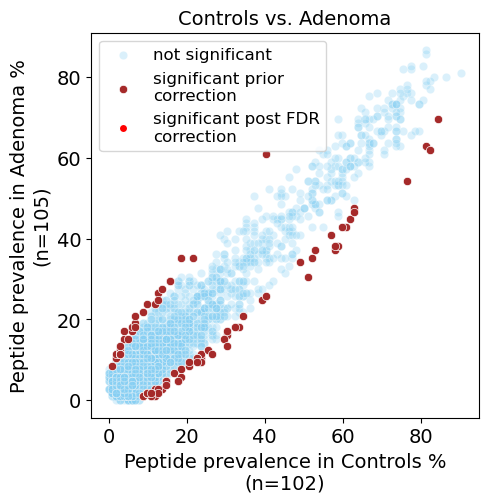

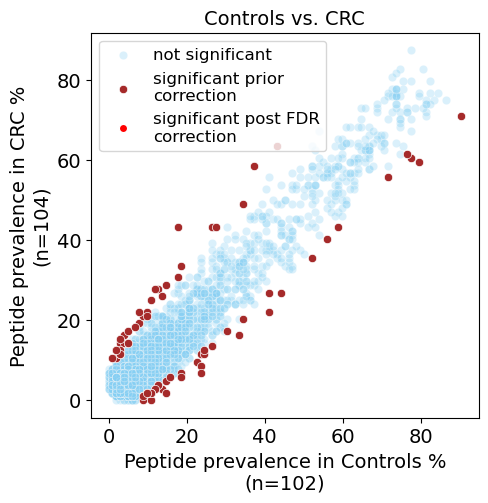

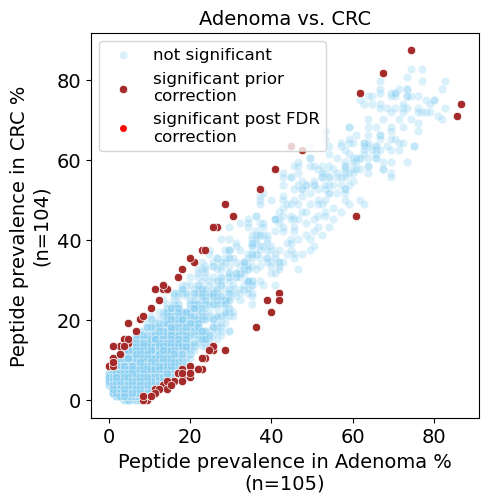

In [65]:
sampleset_bin_select = sampleset.sampleset_bin[((sampleset.sampleset_bin.sum(axis=1) / sampleset.sampleset_bin.shape[1]) > 0.03) &
                                               ((sampleset.sampleset_bin.sum(axis=1) / sampleset.sampleset_bin.shape[1]) <= 0.81)]

sampleset_counts_select = sampleset.sampleset_bin[((sampleset.sampleset_bin.sum(axis=1) / sampleset.sampleset_bin.shape[1]) > 0.03) &
                                               ((sampleset.sampleset_bin.sum(axis=1) / sampleset.sampleset_bin.shape[1]) <= 0.81)]

sampleset_bin_select.to_csv(os.path.join(PATH_OUTPUT, "sampleset_bin_more_informative.csv"), index="peptide_name")
sampleset_counts_select.to_csv(os.path.join(PATH_OUTPUT, "sampleset_count_more_informative.csv"), index="peptide_name")
# Convert metadata in a format to import on R and run Phiper/Phiperio
samples = sampleset.sample_sheet[['SampleName', 'group_test', 'Sex', 'Age']]
samples.columns = ['sample_id', 'group', 'sex', 'age']
samples.to_csv(os.path.join(PATH_OUTPUT, 'samples.csv'), index=False)


df_counts_selected = sampleset.df_counts.loc[sampleset_bin_select.index]
df_prevalences_selected = sampleset.df_prevalences.loc[sampleset_bin_select.index]

dict_pairs_summary_selected = scatterplots_and_prevalence_tables(df_prevalences=df_prevalences_selected, 
                                   df_counts=df_counts_selected, 
                                   dict_groups_list=sampleset.dict_groups_list, 
                                   group_pair_list=sampleset.group_pair_list,
                                   dict_group_counts=sampleset.dict_group_counts, 
                                   libraries=sampleset.libraries, 
                                   path_output=os.path.join(PATH_OUTPUT, 'Prevalence_scatterplots'), 
                                   threshold=0, 
                                   add_permutations=False)



In [66]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def pval_to_stars(p):
    if pd.isna(p):
        return ""
    elif p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "n.s."


def plot_prevalence_grouped_barplot(
    df,
    group1_col="% Controls",
    group2_col="% Adenoma",
    pval_col="pvals_not_corr",
    peptide_col="peptide_name",
    species_col="species",
    description_col="Description",
    group1_name="Controls",
    group2_name="Adenoma",
    group1_color=None,
    group2_color=None,
    group_color_dict=None,
    species_color_dict=None,
    color_right_annotations_by_species=True,
    annotation_default_color="black",
    aliases_species=None,
    aliases_description=None,
    figsize=None,
    save_path=None,
    value_fmt=".1f",
    annotation_fontsize=8,
    ytick_fontsize=8,
    bar_height=0.35,
    show_values=True,
    title=None,
    sort_by=None,
    ascending=False,
    xlim=(0, 100)
):
    """
    Publication-style horizontal grouped barplot with:
    - prevalence in group1 and group2 for each peptide
    - peptide names as ytick labels
    - p-value significance stars next to each pair of bars
    - right-side text annotation: species | Description
    - consistent group colors across comparisons using group_color_dict
    - optional right annotation text colored by species using species_color_dict
    """

    plot_df = df.copy()

    # -----------------------------
    # Basic checks
    # -----------------------------

    required_cols = [
        group1_col,
        group2_col,
        pval_col,
        peptide_col,
        species_col,
        description_col
    ]

    missing = [c for c in required_cols if c not in plot_df.columns]

    if missing:
        raise ValueError(f"Missing columns: {missing}")

    # -----------------------------
    # Group colors
    # -----------------------------

    if group_color_dict is None:
        group_color_dict = {
            "Controls": "#55A868",
            "Adenoma": "#4C72B0",
            "CRC": "#DD8452"
        }

    if group1_color is None:
        group1_color = group_color_dict.get(group1_name, "#C83E4D")

    if group2_color is None:
        group2_color = group_color_dict.get(group2_name, "#2E8B57")

    # -----------------------------
    # Optional sorting
    # -----------------------------

    if sort_by is not None:
        if sort_by not in plot_df.columns:
            raise ValueError(f"sort_by column '{sort_by}' not found in dataframe.")

        plot_df = plot_df.sort_values(
            by=sort_by,
            ascending=ascending
        ).copy()

    # -----------------------------
    # Apply aliases
    # -----------------------------

    if aliases_species is not None:
        plot_df[species_col] = plot_df[species_col].replace(aliases_species)

    if aliases_description is not None:
        plot_df[description_col] = plot_df[description_col].replace(aliases_description)

    # -----------------------------
    # Labels and annotations
    # -----------------------------

    peptide_labels = plot_df[peptide_col].astype(str).tolist()

    plot_df["_right_annotation"] = (
        plot_df[species_col].fillna("").astype(str)
        + " | "
        + plot_df[description_col].fillna("").astype(str)
    )

    n_rows = len(plot_df)

    if figsize is None:
        figsize = (13, max(5, n_rows * 0.38))

    # -----------------------------
    # Figure layout
    # -----------------------------

    fig = plt.figure(figsize=figsize)

    gs = fig.add_gridspec(
        1,
        2,
        width_ratios=[4.5, 4.5],
        wspace=0.05
    )

    ax = fig.add_subplot(gs[0, 0])
    ax_annot = fig.add_subplot(gs[0, 1], sharey=ax)

    # -----------------------------
    # Bar positions
    # -----------------------------

    y = np.arange(n_rows)

    y_group1 = y - bar_height / 2
    y_group2 = y + bar_height / 2

    vals1 = plot_df[group1_col].astype(float).values
    vals2 = plot_df[group2_col].astype(float).values
    pvals = plot_df[pval_col].values

    # -----------------------------
    # Plot bars
    # -----------------------------

    ax.barh(
        y_group1,
        vals1,
        height=bar_height,
        color=group1_color,
        label=group1_name,
        alpha=0.9
    )

    ax.barh(
        y_group2,
        vals2,
        height=bar_height,
        color=group2_color,
        label=group2_name,
        alpha=0.9
    )

    # -----------------------------
    # Add prevalence values
    # -----------------------------

    if show_values:
        for i, (v1, v2) in enumerate(zip(vals1, vals2)):

            ax.text(
                min(v1 + 1.2, xlim[1] - 2),
                y_group1[i],
                f"{v1:{value_fmt}}",
                va="center",
                ha="left",
                fontsize=8
            )

            ax.text(
                min(v2 + 1.2, xlim[1] - 2),
                y_group2[i],
                f"{v2:{value_fmt}}",
                va="center",
                ha="left",
                fontsize=8
            )

    # -----------------------------
    # Add p-value stars
    # -----------------------------

    for i, p in enumerate(pvals):

        star = pval_to_stars(p)

        x_star = max(vals1[i], vals2[i]) + 10
        x_star = min(x_star, xlim[1] - 3)

        ax.text(
            x_star,
            y[i],
            star,
            va="center",
            ha="left",
            fontsize=11,
            fontweight="bold"
        )

    # -----------------------------
    # Main axis styling
    # -----------------------------

    ax.set_yticks(y)
    ax.set_yticklabels(peptide_labels, fontsize=ytick_fontsize)

    ax.set_xlabel("Prevalence (%)", fontsize=12)
    ax.set_xlim(*xlim)

    ax.invert_yaxis()

    ax.legend(
        frameon=False,
        loc="center right",
        fontsize=10
    )

    ax.grid(axis="x", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

    sns.despine(ax=ax, left=False, bottom=False)

    # -----------------------------
    # Right annotation panel
    # -----------------------------

    ax_annot.set_xlim(0, 1)
    ax_annot.set_ylim(ax.get_ylim())
    ax_annot.axis("off")

    for i, (_, row) in enumerate(plot_df.iterrows()):

        species = row[species_col]
        annotation = row["_right_annotation"]

        if (
            color_right_annotations_by_species
            and species_color_dict is not None
            and pd.notna(species)
        ):
            annotation_color = species_color_dict.get(
                species,
                annotation_default_color
            )
        else:
            annotation_color = annotation_default_color

        ax_annot.text(
            0,
            y[i],
            annotation,
            va="center",
            ha="left",
            fontsize=annotation_fontsize,
            color=annotation_color
        )

    ax_annot.set_title(
        "Species | Description",
        fontsize=11,
        loc="left",
        pad=10
    )

    # -----------------------------
    # Title
    # -----------------------------

    if title is None:
        title = f"{group1_name} vs {group2_name}"

    fig.suptitle(title, fontsize=15, y=1)

    plt.tight_layout()

    # -----------------------------
    # Save
    # -----------------------------

    if save_path is not None:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

    return plot_df.drop(columns=["_right_annotation"], errors="ignore")

In [68]:
aliases_species = {"Lymphocryptovirus humangamma4" : "Epstein-Barr virus",
                   "Cytomegalovirus humanbeta5" : "Cytomegalovirus"
                    }
aliases_description = {"Human herpesvirus 4  Epstein-Barr nuclear antigen 1" : "Epstein-Barr nuclear antigen 1",
                       "D-alanyl-D-alanine carboxypeptidase/D-alanyl-D-alanine-endopeptidase" : "D-alanyl-D-alanine carboxypeptidase",
                       "Phosphoglycerol transferase and related proteins, alkaline phosphatase superfamily" : "Phosphoglycerol transferase"}

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/1912107844.py:311: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



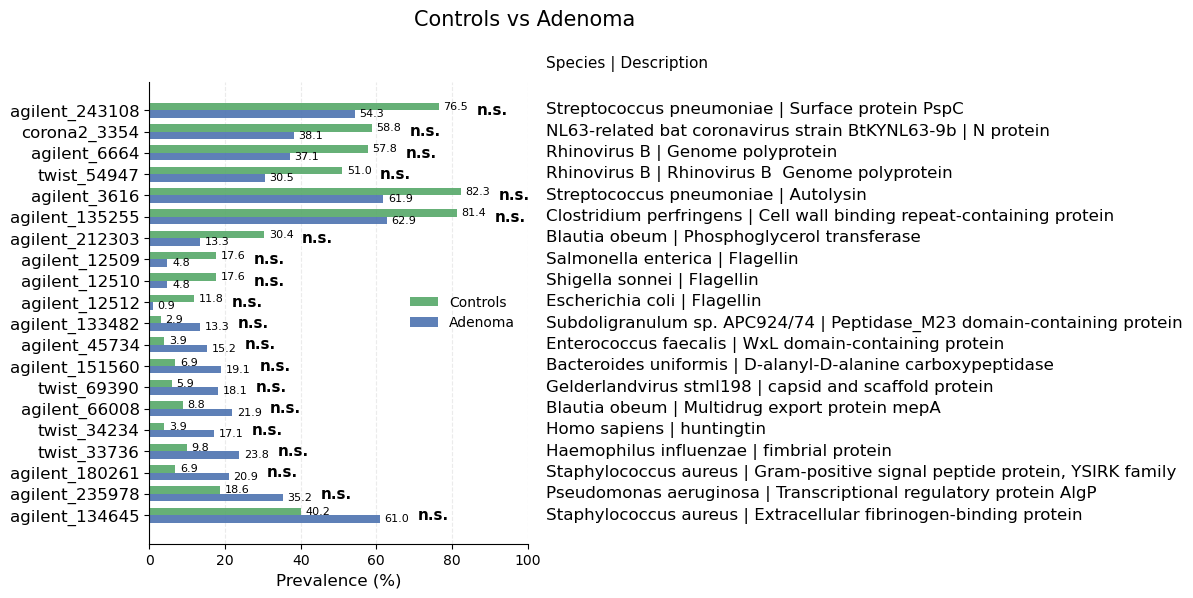

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/1912107844.py:311: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



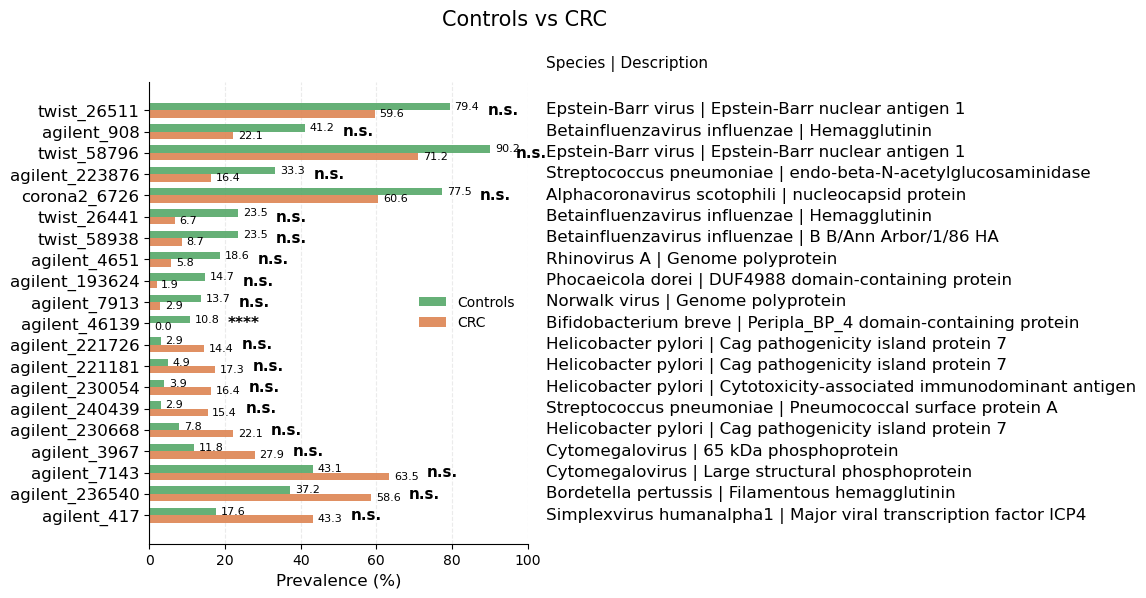

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/1912107844.py:311: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



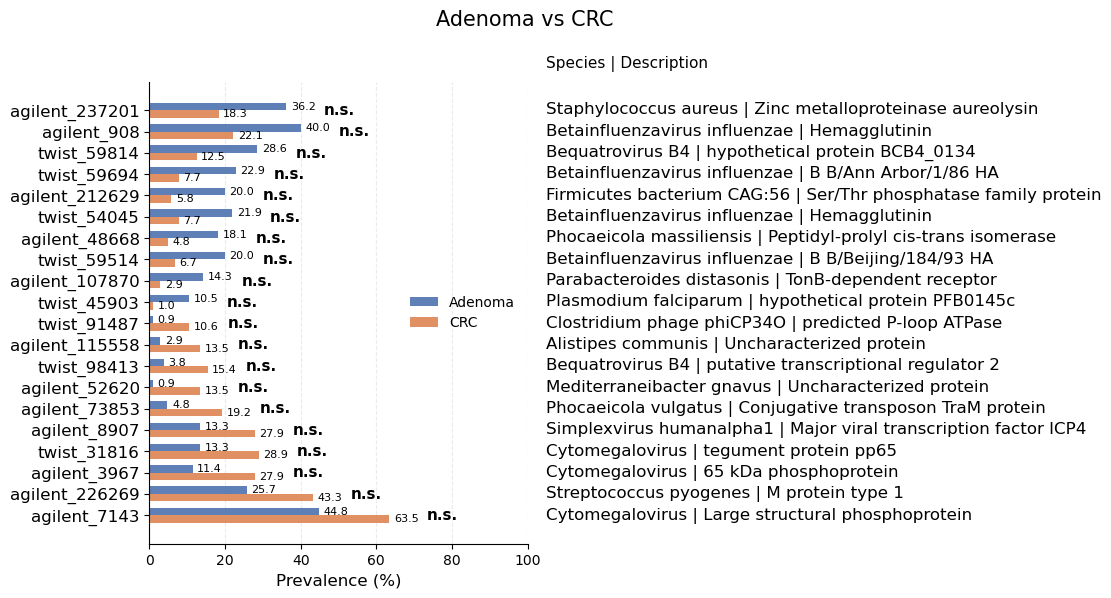

In [44]:
group_color_dict = {
    "Controls": "#55A868",
    "Adenoma": "#4C72B0",
    "CRC": "#DD8452"
}

annotations = []

for group_pair in sampleset.dict_pair_groups_stats.keys():

    sample_set_selected = dict_pairs_summary_selected[group_pair].loc[
        dict_pairs_summary_selected[group_pair]["Protein name"].notna() &
        dict_pairs_summary_selected[group_pair]["species"].notna()
    ].copy()

    relevant_for_heatmap = pd.concat(
        [
            sample_set_selected.iloc[:10, :],
            sample_set_selected.iloc[-10:, :]
        ]
    ).copy()

    relevant_for_heatmap["delta"] = (
        relevant_for_heatmap[f"% {group_pair[0]}"]
        - relevant_for_heatmap[f"% {group_pair[1]}"]
    )

    plot_df = plot_prevalence_grouped_barplot(
        df=relevant_for_heatmap,
        group1_col=f"% {group_pair[0]}",
        group2_col=f"% {group_pair[1]}",
        pval_col="pvalue",
        peptide_col="peptide_name",
        species_col="species",
        description_col="Protein name",
        group1_name=group_pair[0],
        group2_name=group_pair[1],
        group_color_dict=group_color_dict,
        color_right_annotations_by_species=False,
        aliases_species=aliases_species,
        aliases_description=aliases_description,
        sort_by="delta",
        ascending=False,
        annotation_fontsize=12,
        ytick_fontsize=12,
        figsize=(10, 6),
        title=f"{group_pair[0]} vs {group_pair[1]}",
        save_path=os.path.join(
            PATH_OUTPUT,
            f"Prevalence_scatterplots/{group_pair[0]}_vs_{group_pair[1]}_barplots.svg"
        )
    )

    annotation = plot_df[
        ["peptide_name", "species", "Protein name"]
    ].copy()

    annotation["comparison"] = f"{group_pair[0]},{group_pair[1]}"
    annotations.append(annotation)

## Run Delta framework, then collect results and plot barplots for species and proteins

In [69]:
def scatterplots_with_categories(
    df_comparison,
    variable,
    group_pair,
    path_output,
    external_pvalues_path=None,
    external_taxon_col='taxon',
    external_p_col='p_value',
    mw_statistic = False
):
    '''
    Runs Mann-Whitney U test for each taxon/category in df_comparison and
    returns a summary table with statistics.

    If external_pvalues_path is provided from Delta Framework, imported p-values/FDR values
    will be added
    '''

    import os
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from scipy.stats import mannwhitneyu
    from statsmodels.stats.multitest import multipletests

    # if external_pvalues_path None:
    # Clean ratio column just in case
    df_comparison = df_comparison.copy()
    df_comparison['ratio'] = pd.to_numeric(df_comparison['ratio'], errors='coerce')
    df_comparison = df_comparison.dropna(subset=['ratio'])

    taxa = df_comparison[variable].dropna().unique()

    results = []

    for taxon in taxa:
        df_taxon = df_comparison[df_comparison[variable] == taxon]
        df_rest = df_comparison[df_comparison[variable] != taxon]

        n_taxon = len(df_taxon)
        n_rest = len(df_rest)

        # if n_taxon < 10 or n_rest < 10:
        #     print(f"Skipping {taxon}: not enough peptides ({n_taxon} vs {n_rest})")
        #     continue

        dist1 = df_taxon['ratio'].tolist()
        dist2 = df_rest['ratio'].tolist()

        mw_statistic = np.nan
        p_value = np.nan
        cles = np.nan
        if mw_statistic:
            try:
                mw_statistic, p_value = mannwhitneyu(dist1, dist2, alternative='two-sided')
                cles = mw_statistic / (len(dist1) * len(dist2))
            except Exception as e:
                print(f"Error for {taxon}: {e}")

        # print(taxon, p_value)

        results.append({
            'group_1': group_pair[0],
            'group_2': group_pair[1],
            'variable': variable,
            'taxon': taxon,
            'n_taxon': n_taxon,
            'n_rest': n_rest,
            'n_total_used': n_taxon + n_rest,
            'p_value_mw': p_value,
            'CLES': cles
        })

    summary_df = pd.DataFrame(results)

    # Internal FDR correction
    if not summary_df.empty:
        valid_mask = summary_df['p_value_mw'].notna()
        summary_df['p_value_fdr'] = np.nan

        if valid_mask.sum() > 0:
            _, corrected_p_values, _, _ = multipletests(
                summary_df.loc[valid_mask, 'p_value_mw'],
                method='fdr_bh'
            )
            summary_df.loc[valid_mask, 'p_value_mw_fdr'] = corrected_p_values
    else:
        summary_df['p_value_mw_fdr'] = []

    # ---------------------------------------------------
    # OVERRIDE WITH EXTERNAL P-VALUES / FDR IF PROVIDED
    # ---------------------------------------------------
    if external_pvalues_path is not None:
        ext = pd.read_csv(external_pvalues_path)
        # First extract the rank used in this sub-analysis
        ext = ext[(ext['rank'] == variable) &
                  (ext['n_peptides_used'] >= 10) &
                  np.abs(ext['max_delta']) > 0.1]
        
        # Keep only needed columns
        ext = ext[[external_taxon_col, external_p_col, ]].copy()
        # Rename columns
        ext = ext.rename(columns={
            external_taxon_col: 'taxon',
            external_p_col: 'p_value_delta'
        })

        # -----------------------------
        # APPLY FDR CORRECTION HERE
        # -----------------------------
        from statsmodels.stats.multitest import multipletests

        valid_mask = ext['p_value_delta'].notna()

        ext['p_value_delta_fdr'] = np.nan

        print(f"Number of categories ({variable}) tested: {len(ext)}")
        if valid_mask.sum() > 0:
            _, corrected, _, _ = multipletests(
                ext.loc[valid_mask, 'p_value_delta'],
                method='fdr_bh'
            )
            ext.loc[valid_mask, 'p_value_delta_fdr'] = corrected

        # Merge with main table
        summary_df = summary_df.merge(ext, on='taxon', how='inner')

        # Override internal values
        # summary_df['p_value'] = summary_df['p_value_delta_fw'].combine_first(summary_df['p_value'])
        # summary_df['p_value_fdr'] = summary_df['p_value_fdr_external'].combine_first(summary_df['p_value_fdr'])

    # summary_df = summary_df[summary_df['p_value'] <=0.05]
    # Dictionary for plotting labels
    corrected_p_values_dict = dict(zip(summary_df['taxon'], summary_df['p_value_delta_fdr']))
    raw_p_values_dict = dict(zip(summary_df['taxon'], summary_df['p_value_delta']))
    # Save table
    os.makedirs(path_output, exist_ok=True)
    summary_df.to_csv(
        f"{path_output}/summary_stats_{variable}_{group_pair[0]}_vs_{group_pair[1]}.csv",
        index=False
    )

    significant = list(summary_df[summary_df['p_value_delta'] <= 0.05]['taxon'])

    try:
        species_label_map = {
            sp: f"{sp} (p={corrected_p_values_dict.get(sp, float('nan')):.3g})"
            for sp in significant
        }

        hue_order = [
            species_label_map[sp]
            for sp in sorted(significant, key=lambda x: corrected_p_values_dict.get(x, float('inf')))
        ]

        df_plot = df_comparison.copy()

        df_plot.loc[df_plot[variable].isin(significant), variable] = \
            df_plot.loc[df_plot[variable].isin(significant), variable].map(species_label_map)

        plt.figure(figsize=(6, 6))

        ax = sns.scatterplot(
            data=df_plot[~df_plot[variable].isin(species_label_map.values())],
            x=group_pair[0], y=group_pair[1],
            color='grey', alpha=0.3, label='all the rest', s=50
        )

        sns.scatterplot(
            data=df_plot[df_plot[variable].isin(species_label_map.values())],
            x=group_pair[0], y=group_pair[1],
            hue=variable, palette='Set1', edgecolor='black', s=85, hue_order=hue_order
        )

        plt.plot([0, 100], [0, 100], '--')
        plt.legend()

        handles, labels = ax.get_legend_handles_labels()
        new_labels = [lab.replace(" [", "\n(") for lab in labels]
        ax.legend(handles, new_labels)

        plt.tight_layout()
        plt.savefig(
            os.path.join(path_output, f'Scatterplot_{variable}_significant.png'),
            facecolor='white',
            dpi=300,
            transparent=False,
            bbox_inches='tight'
        )
        plt.close()

    except Exception as e:
        print(f"Error plotting scatterplot: {e}")

    try:
        for i in significant:
            pval = raw_p_values_dict.get(i, float('nan'))
            pval_cor = corrected_p_values_dict.get(i, float('nan'))

            label = f"{i} (p={pval:.3g}, p_fdr={pval_cor:.3g})"
            plt.figure(figsize=(5, 5))

            sns.scatterplot(
                data=df_comparison[df_comparison[variable] != i],
                x=group_pair[0], y=group_pair[1],
                color='grey', alpha=0.5, label='rest', s=50
            )

            sns.scatterplot(
                data=df_comparison[df_comparison[variable] == i],
                x=group_pair[0], y=group_pair[1],
                color="#6723F1", label=label, edgecolor='black', s=85
            )

            plt.plot([0, 100], [0, 100], '--')
            plt.legend(frameon=False)

            plt.savefig(
                os.path.join(path_output, f"Scatterplot_{variable}_{i.replace('/','-')}_significant.png"),
                facecolor='white',
                dpi=300,
                transparent=False,
                bbox_inches='tight'
            )
            plt.close()

    except Exception as e:
        print(f"Error plotting scatterplot: {e}")

    return summary_df



In [321]:
dict_summary = {}

for group_pair in list(sampleset.dict_pair_groups_stats.keys()):
    print(group_pair)
    summaries_per_variable = []
    
    for variable in ['genus', 'species', 'Description']:
        external_taxon_col='feature'
        external_p_col='p_perm'
        external_pvalues_path=f"{PATH_OUTPUT}/Delta_framework_filtered_peptides/{group_pair[0]}_vs_{group_pair[1]}/DELTA_framework/delta_table.csv"
        df_comparison = sampleset.dict_pair_groups_stats[group_pair]
        print(df_comparison.columns)
        path_output = os.path.join(PATH_OUTPUT,
                                    "Functional_categories_analysis",
                                      f"{group_pair[0]}_vs_{group_pair[1]}",
                                        variable)
        # Run scatterplot execution and retrieve the df_summary
        df_summary = scatterplots_with_categories(
            df_comparison,
            variable,
            group_pair,
            path_output,
            external_pvalues_path=external_pvalues_path,
            external_taxon_col=external_taxon_col,
            external_p_col=external_p_col,
            mw_statistic = False
        )
        df_summary['variable'] = variable
        summaries_per_variable.append(df_summary)
    dict_summary[group_pair] = pd.concat(summaries_per_variable, ignore_index=True)
    



('Controls', 'Adenoma')
Index(['peptide_name', 'Controls', 'Adenoma', 'pvals_not_corr', 'passed_bh',
       'pvals', 'Significant_bh', 'Significant', 'ratio', 'Delta',
       'Delta_ratio', 'Description', 'domain', 'kingdom', 'phylum', 'class',
       'order', 'family', 'genus', 'species', 'common', 'is_IEDB_or_cntrl',
       'is_auto', 'is_infect', 'is_EBV', 'is_toxin', 'is_PNP', 'is_EM',
       'is_MPA', 'is_patho', 'is_probio', 'is_IgA', 'is_flagellum',
       'signalp6_slow', 'is_topgraph_new', 'is_phage', 'is_allergens',
       'is_influenza'],
      dtype='object')
Number of categories (genus) tested: 81
Index(['peptide_name', 'Controls', 'Adenoma', 'pvals_not_corr', 'passed_bh',
       'pvals', 'Significant_bh', 'Significant', 'ratio', 'Delta',
       'Delta_ratio', 'Description', 'domain', 'kingdom', 'phylum', 'class',
       'order', 'family', 'genus', 'species', 'common', 'is_IEDB_or_cntrl',
       'is_auto', 'is_infect', 'is_EBV', 'is_toxin', 'is_PNP', 'is_EM',
       'is_MP

In [71]:
# Dump with
# pkl.dump(dict_summary, open(os.path.join(PATH_OUTPUT, 'Functional_categories_analysis/tables_delta_and_statistics_twist_caga_reannotated.pkl'), 'wb'))
dict_summary = pkl.load(open(os.path.join(PATH_OUTPUT, 'Functional_categories_analysis/tables_delta_and_statistics_twist_caga_reannotated.pkl'), 'rb'))


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/2541002828.py:49: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/2541002828.py:49: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/2541002828.py:49: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



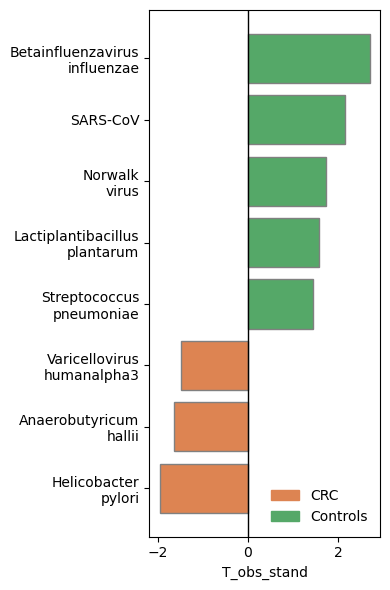

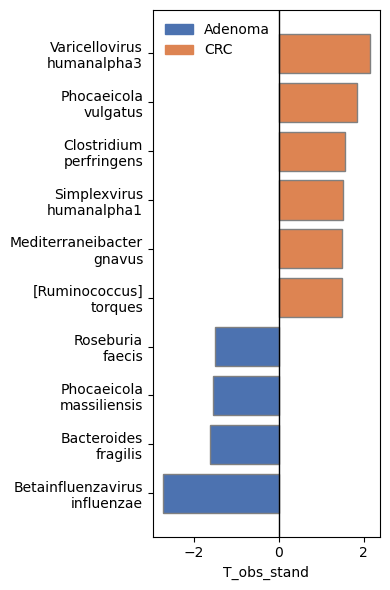

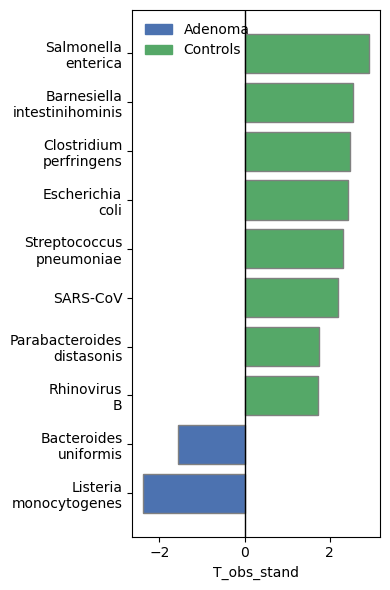

In [72]:
def barplot_lefse_style(ext, group_pair, loc_legend = None, top_n=10, path_output=None):
    # Ordina per valore
    import matplotlib.patches as mpatches
    ext_sorted = ext.sort_values(by='T_obs_stand')
    # Select top N by absolute T statistic, then sort for plotting
    ext_sorted = (
        ext.assign(abs_T_obs_stand=ext['T_obs_stand'].abs())
           .sort_values(by='abs_T_obs_stand', ascending=False)
           .head(top_n)
           .sort_values(by='T_obs_stand')
           .copy()
    )
    # Colori: positivi vs negativi
    palette = {
        'Controls': '#55A868',
        'Adenoma': '#4C72B0',
        'CRC': '#DD8452'
    }
    ext_sorted['group'] = ext_sorted['T_obs_stand'].apply(
        lambda x: group_pair[0] if x > 0 else group_pair[1]
    )
    # ext_sorted_top = ext_sorted_top[:10]
    colors = ext_sorted['group'].map(palette)

    plt.figure(figsize=(4, 6))

    plt.barh(
        y=ext_sorted['feature'],   # oppure una colonna tipo 'taxon'
        width=ext_sorted['T_obs_stand'],
        color=colors, edgecolor='grey'
    )

    # Linea centrale (zero)
    plt.axvline(0, color='black', linewidth=1)
    # label = [x.replace(' ', '\n') for x in ext_sorted['feature']]
    plt.xlabel('T_obs_stand')
    p = plt.gca()
    labels = [x.get_text() for x in p.get_yticklabels()]
    labels = [x.replace('Severe acute respiratory syndrome coronavirus', 'SARS-CoV') for x in labels]
    labels = [x.replace(' ', '\n', 1) for x in labels]
    # def smart_break(x):
    #     spaces = [i for i, c in enumerate(x) if c == ' ']
    #     if len(spaces) == 0:
    #         return x
    #     idx = spaces[0] if len(spaces) <= 2 else spaces[1]
    #     return x[:idx] + '\n' + x[idx+1:]

    # labels = [smart_break(x) for x in labels]
    p.set_yticklabels(labels)
    plt.ylabel('Taxon')
    present_groups = ext_sorted['group'].unique()

    handles = [
        mpatches.Patch(color=palette[g], label=g)
        for g in present_groups
    ]
    if loc_legend:
        plt.legend(handles=handles, frameon=False, loc=loc_legend)
    else:
        plt.legend(handles=handles, frameon=False)
    plt.ylabel(None)
    plt.tight_layout()
    plt.savefig(
        os.path.join(path_output, f"Barplot_{group_pair[0]}_vs_{group_pair[1]}.svg"),
        facecolor='white',
        dpi=300,
        transparent=False,
        # bbox_inches='tight'
    )
    
    return ext_sorted

results_delta_top_hits = {}

group_pair = ('Controls', 'CRC')
external_pvalues_path=f"{PATH_OUTPUT}/Delta_framework_filtered_peptides/{group_pair[0]}_vs_{group_pair[1]}/DELTA_framework/delta_table.csv"
ext = pd.read_csv(external_pvalues_path, index_col='Unnamed: 0')
external_pvalues_path_controls_crc = ext.copy()
# First extract the rank used in this sub-a nalysis
ext = ext[(ext['rank'] == 'species') &
            (ext['n_peptides_used'] >= 20) &
            (np.abs(ext['max_delta']) > 0.1) 
            & (np.abs(ext['T_obs_stand']) > 1.2)
            # (ext['rank'] == '')
].sort_values(by='p_perm')
os.makedirs(os.path.join(PATH_OUTPUT, 'Delta_framework'), exist_ok=True)
ext_sorted = barplot_lefse_style(ext, group_pair,  top_n=10, path_output=os.path.join(PATH_OUTPUT, 'Delta_framework'))
results_delta_top_hits[group_pair] = ext_sorted


group_pair = ('Adenoma', 'CRC')
external_pvalues_path=f"{PATH_OUTPUT}/Delta_framework_filtered_peptides/{group_pair[0]}_vs_{group_pair[1]}/DELTA_framework/delta_table.csv"

ext = pd.read_csv(external_pvalues_path,index_col='Unnamed: 0')
external_pvalues_path_adenoma_crc = ext.copy()

# First extract the rank used in this sub-a nalysis
ext = ext[(ext['rank'] == 'species') &
            (ext['n_peptides_used'] >= 20) &
            (np.abs(ext['max_delta']) > 0.1) 
            & (np.abs(ext['T_obs_stand']) > 1.2)
            # (ext['rank'] == '')
].sort_values(by='p_perm')
group_pair = ('CRC', 'Adenoma')
ext_sorted = barplot_lefse_style(ext, group_pair, loc_legend='upper left',  top_n=10, path_output=os.path.join(PATH_OUTPUT, 'Delta_framework'))
group_pair = ('Adenoma', 'CRC')
results_delta_top_hits[group_pair] = ext_sorted

group_pair = ('Controls', 'Adenoma')
external_pvalues_path=f"{PATH_OUTPUT}/Delta_framework_filtered_peptides/{group_pair[0]}_vs_{group_pair[1]}/DELTA_framework/delta_table.csv"
ext = pd.read_csv(external_pvalues_path,index_col='Unnamed: 0')
external_pvalues_path_controls_adenoma = ext.copy()

# First extract the rank used in this sub-a nalysis
ext = ext[(ext['rank'] == 'species') &
            (ext['n_peptides_used'] >= 20) &
            (np.abs(ext['max_delta']) > 0.1) 
            & (np.abs(ext['T_obs_stand']) > 1.5)
            # (ext['rank'] == '')
].sort_values(by='p_perm')
group_pair = ('Controls', 'Adenoma')
ext_sorted = barplot_lefse_style(ext, group_pair,loc_legend='upper left', top_n=10, path_output=os.path.join(PATH_OUTPUT, 'Delta_framework'))
results_delta_top_hits[group_pair] = ext_sorted





In [76]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap, Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# ---------------------------------------------------------
# Helper: p-value to stars
# ---------------------------------------------------------

def pval_to_stars(p):
    if pd.isna(p):
        return ""
    elif p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""


# ---------------------------------------------------------
# Helper: create colormap for bar colors
# ---------------------------------------------------------

def create_colormap(df, variable="max_delta"):
    """
    Create a grey-to-green colormap based on a selected numeric variable.
    """

    cmap = LinearSegmentedColormap.from_list(
        "grey_to_green",
        ["lightgrey", "forestgreen"]
    )

    values = df[variable].astype(float).fillna(0)

    vmax = values.max()

    if pd.isna(vmax) or vmax <= 0:
        vmax = 1

    norm = Normalize(
        vmin=0,
        vmax=vmax
    )

    bar_colors = values.map(lambda x: cmap(norm(x)))

    return bar_colors, cmap, norm


# ---------------------------------------------------------
# Helper: add stars to horizontal bars
# ---------------------------------------------------------

def add_significance_stars_to_horizontal_bars(
    ax,
    df,
    x_col="abs_T",
    pval_col="p_perm",
    fontsize=12,
    offset_fraction=0.05
):
    """
    Add significance stars to the right of horizontal bars.
    Assumes the dataframe order is the same as the plotted bar order.
    """

    df = df.reset_index(drop=True).copy()

    x_max = df[x_col].max()

    if pd.isna(x_max) or x_max <= 0:
        x_max = 1

    offset = x_max * offset_fraction

    # Give extra x-axis space for stars
    current_xlim = ax.get_xlim()
    ax.set_xlim(
        current_xlim[0],
        max(current_xlim[1], x_max + offset * 5)
    )

    for i, row in df.iterrows():

        star = pval_to_stars(row[pval_col])

        if star == "":
            continue

        ax.text(
            row[x_col] + offset,
            i,
            star,
            va="center",
            ha="left",
            fontsize=fontsize,
            fontweight="bold",
            color="black"
        )


# ---------------------------------------------------------
# Main plotting function
# ---------------------------------------------------------

def plot_delta_barplot_for_species(
    ext,
    species_name,
    m_eff_min=10,
    variable_color="max_delta",
    x_col_raw="T_obs_stand",
    pval_col="p_perm",
    feature_col="feature",
    species_col="species",
    aliases_features=None,
    figsize=(2.2, 5),
    title=None,
    save_path=None,
    colorbar_label="max_delta"
):
    """
    Plot horizontal DELTA-framework barplot for one species.

    Bars:
        abs(T_obs_stand)

    Bar color:
        variable_color, usually max_delta

    Stars:
        p_perm significance
    """

    # -----------------------------
    # Select species and filter
    # -----------------------------

    ext_selected = ext[
        (ext[species_col] == species_name) &
        (ext["m_eff"] >= m_eff_min)
    ].copy()

    if ext_selected.empty:
        raise ValueError(
            f"No rows found for species '{species_name}' with m_eff >= {m_eff_min}."
        )

    # -----------------------------
    # Clean feature names
    # -----------------------------

    if aliases_features is not None:
        ext_selected[feature_col] = ext_selected[feature_col].replace(aliases_features)

    # -----------------------------
    # Calculate absolute standardized T statistic
    # -----------------------------

    ext_selected["abs_T"] = np.abs(ext_selected[x_col_raw])

    ext_selected = ext_selected.sort_values(
        by="abs_T",
        ascending=False
    ).copy()

    # Avoid seaborn aggregation if duplicate feature names exist
    ext_selected["_feature_label"] = ext_selected[feature_col].astype(str)

    if ext_selected["_feature_label"].duplicated().any():
        ext_selected["_feature_label"] = (
            ext_selected["_feature_label"]
            + " ["
            + ext_selected.groupby("_feature_label").cumcount().astype(str)
            + "]"
        )

    # -----------------------------
    # Create colors
    # -----------------------------

    bar_colors, cmap, norm = create_colormap(
        ext_selected,
        variable=variable_color
    )

    # -----------------------------
    # Plot
    # -----------------------------

    fig, ax = plt.subplots(figsize=figsize)

    sns.barplot(
        data=ext_selected,
        x="abs_T",
        y="_feature_label",
        order=ext_selected["_feature_label"].tolist(),
        palette=bar_colors.tolist(),
        ax=ax
    )

    # -----------------------------
    # Add significance stars
    # -----------------------------

    add_significance_stars_to_horizontal_bars(
        ax=ax,
        df=ext_selected,
        x_col="abs_T",
        pval_col=pval_col,
        fontsize=12,
        offset_fraction=0.05
    )

    # -----------------------------
    # Axis labels
    # -----------------------------

    ax.set_xlabel(r"$|T_{\mathrm{obs, stand}}|$")
    ax.set_ylabel("")

    if title is not None:
        ax.set_title(title, fontsize=12)

    # -----------------------------
    # Inset colorbar
    # -----------------------------

    sm = mpl.cm.ScalarMappable(
        cmap=cmap,
        norm=norm
    )

    sm.set_array([])

    cax = inset_axes(
        ax,
        width="8%",
        height="30%",
        loc="lower right",
        borderpad=0.8
    )

    cbar = fig.colorbar(sm, cax=cax)

    cbar.set_label(
        colorbar_label,
        fontsize=10
    )

    cbar.ax.tick_params(labelsize=8)
    cbar.ax.yaxis.set_label_position("left")

    sns.despine(ax=ax)

    plt.tight_layout()

    # -----------------------------
    # Save
    # -----------------------------

    if save_path is not None:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

    return ext_selected.drop(columns=["_feature_label"], errors="ignore")

In [86]:
group_pair = ("Controls", "CRC")

external_pvalues_path = (f"/Users/gabrielinnocenti/Desktop/phd_tmp/Projects/CORSA/Final_output/Delta_framework_prevalence_2_81/Controls_vs_CRC/DELTA_framework/delta_table.csv")

ext = pd.read_csv(
    external_pvalues_path,
    index_col="Unnamed: 0"
)

df_comparison = sampleset.dict_pair_groups_stats[group_pair]

ext_clean = ext[ext["feature"].notnull()].copy()

ext = pd.merge(
    ext_clean,
    df_comparison[
        ["genus", "species", "Description"]
    ].drop_duplicates(),
    left_on="feature",
    right_on="Description",
    how="left"
)

In [87]:
ext

,rank,feature,group_col,group1,group2,design,n_subjects_paired,n_peptides_used,m_eff,T_obs,...,T_obs_stand,Z_from_p,p_perm,b,max_delta,frac_delta_pos,frac_delta_pos_w,genus,species,Description
0,Description,(3R)-hydroxymyristoyl ACP dehydratase (fabZ),group,CRC,Controls,unpaired,NaN,1,1.0,-0.947741,...,-0.933203,-0.844411,0.398440,50223,0.037142,0.000000,0.000000,Brucella,Brucella anthropi,(3R)-hydroxymyristoyl ACP dehydratase (fabZ)
1,Description,"1,4-beta-N-acetylmuramidase",group,CRC,Controls,unpaired,NaN,1,1.0,0.681858,...,0.656545,0.779673,0.435583,49922,0.020362,1.000000,1.000000,Bifidobacterium,Bifidobacterium bifidum,"1,4-beta-N-acetylmuramidase"
2,Description,"1,4-beta-N-acetylmuramidase",group,CRC,Controls,unpaired,NaN,1,1.0,0.681858,...,0.656545,0.779673,0.435583,49922,0.020362,1.000000,1.000000,Bifidobacterium,Bifidobacterium adolescentis,"1,4-beta-N-acetylmuramidase"
3,Description,"1,4-beta-N-acetylmuramidase",group,CRC,Controls,unpaired,NaN,1,1.0,0.681858,...,0.656545,0.779673,0.435583,49922,0.020362,1.000000,1.000000,Bifidobacterium,Bifidobacterium animalis,"1,4-beta-N-acetylmuramidase"
4,Description,"1,4-beta-N-acetylmuramidase (lytC)",group,CRC,Controls,unpaired,NaN,1,1.0,0.485141,...,0.485451,0.536958,0.591297,77349,0.021682,1.000000,1.000000,Streptococcus,Streptococcus pneumoniae,"1,4-beta-N-acetylmuramidase (lytC)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7203,species,uncultured Flavonifractor sp.,group,CRC,Controls,unpaired,NaN,1,1.0,-0.697083,...,-0.668507,-0.514046,0.607220,74138,0.018665,0.000000,0.000000,NaN,NaN,NaN
7204,species,uncultured Lachnospira sp.,group,CRC,Controls,unpaired,NaN,1,1.0,0.860339,...,0.814462,0.980080,0.327047,31714,0.019985,1.000000,1.000000,NaN,NaN,NaN
7205,species,uncultured Oscillibacter sp.,group,CRC,Controls,unpaired,NaN,1,1.0,0.343180,...,0.335456,0.452887,0.650630,80352,0.010747,1.000000,1.000000,NaN,NaN,NaN
7206,species,uncultured Roseburia sp.,group,CRC,Controls,unpaired,NaN,2,2.0,1.243591,...,1.059326,0.995253,0.319613,46204,0.029977,1.000000,1.000000,NaN,NaN,NaN


In [88]:
aliases_features = {
    "type IV secretion system protein Cag7/CagY, VirB10 homolog (virB10/cagY)":
    "VirB10 homolog (virB10/cagY)"
}

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/2725869582.py:204: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/2725869582.py:267: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/2725869582.py:267: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.



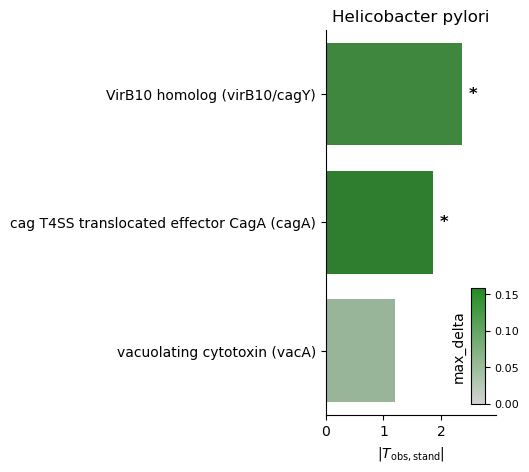

In [92]:
ext_selected_hpylori = plot_delta_barplot_for_species(
    ext=ext,
    species_name="Helicobacter pylori",
    m_eff_min=3,
    variable_color="max_delta",
    x_col_raw="T_obs_stand",
    pval_col="p_perm",
    feature_col="feature",
    species_col="species",
    aliases_features=aliases_features,
    figsize=(2.2, 5),
    title="Helicobacter pylori",
    save_path=None
)

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/2725869582.py:204: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/2725869582.py:267: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/2725869582.py:267: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.



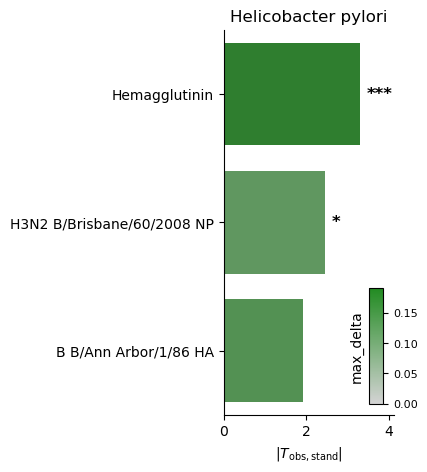

In [93]:
ext_selected_binfluenza = plot_delta_barplot_for_species(
    ext=ext,
    species_name="Betainfluenzavirus influenzae",
    m_eff_min=3,
    variable_color="max_delta",
    x_col_raw="T_obs_stand",
    pval_col="p_perm",
    feature_col="feature",
    species_col="species",
    aliases_features=aliases_features,
    figsize=(2.2, 5),
    title="Helicobacter pylori",
    save_path=None
)

### Scatterplots on main species

In [ ]:
def _get_group_prevalence_columns(df, group_pair):
    """
    Detect whether prevalence columns are named:
    - Controls / CRC
    or
    - % Controls / % CRC
    """

    group1, group2 = group_pair

    possible_group1_cols = [
        group1,
        f"% {group1}",
        f"{group1} %",
    ]

    possible_group2_cols = [
        group2,
        f"% {group2}",
        f"{group2} %",
    ]

    group1_col = next((c for c in possible_group1_cols if c in df.columns), None)
    group2_col = next((c for c in possible_group2_cols if c in df.columns), None)

    if group1_col is None or group2_col is None:
        raise ValueError(
            f"Could not find prevalence columns for {group_pair}.\n"
            f"Tried group1 columns: {possible_group1_cols}\n"
            f"Tried group2 columns: {possible_group2_cols}\n"
            f"Available columns are:\n{list(df.columns)}"
        )

    return group1_col, group2_col

def scatterplot_on_taxon(
    taxon,
    variable,
    dict_summary,
    dict_pair_groups_stats,
    color=None,
    delta_to_show=0,
    simple_name=None,
    subset=None,
    map_all_annotations=False,
    kde_on=False,
    exact_match=True,
    save_path=None
):
    """
    Plot peptide prevalence scatterplots for a selected taxon/annotation.

    Parameters
    ----------
    taxon : str
        Annotation name to highlight, e.g. "Helicobacter pylori" or "CagY".

    variable : str
        Annotation level in df_comparison, e.g. "species", "Description", "genus".

    dict_summary : dict
        Dictionary indexed by group_pair. Each table contains:
        - taxon
        - variable
        - group_1
        - group_2
        - p_value_delta

    dict_pair_groups_stats : dict
        Dictionary indexed by group_pair containing pairwise peptide summary tables.

    exact_match : bool
        If True, uses exact equality.
        If False, uses str.contains(), useful for partial matches like "CagY".
    """

    if color is None:
        color = "#6723F1"

    # Only option for subset is something like subset='agilent' or None
    if subset is not None:
        PATH_AGILENT_LIB_OLD = (
            "/Users/gabrielinnocenti/Desktop/phd_tmp/"
            "Sequencing_runs/Sequencing_19_02_24/"
            "libraries_metadata/df_info_agilent_final_complete.pkl"
        )

        agilent_lib_old = pkl.load(
            open(PATH_AGILENT_LIB_OLD, "rb")
        ).reset_index()

    for group_pair, df_comparison in dict_pair_groups_stats.items():

        df_comparison = df_comparison.copy()

        if variable not in df_comparison.columns:
            print(
                f"Skipping {group_pair}: variable '{variable}' "
                f"not found in df_comparison."
            )
            continue

        # -----------------------------------------------------
        # Detect prevalence columns
        # -----------------------------------------------------

        group1_col, group2_col = _get_group_prevalence_columns(
            df_comparison,
            group_pair
        )

        print(f"{group_pair}: using x='{group1_col}', y='{group2_col}'")

        # -----------------------------------------------------
        # Optional subset
        # -----------------------------------------------------

        if subset is not None:
            df_plot = df_comparison[
                df_comparison["Description"].astype(str).str.contains(
                    subset,
                    case=False,
                    na=False
                )
                &
                df_comparison["peptide_name"].astype(str).str.contains(
                    "agilent",
                    case=False,
                    na=False
                )
            ].copy()

            df_plot = df_plot.merge(
                agilent_lib_old[["peptide_name", "full name", "full_aa_seq"]],
                how="left",
                on="peptide_name"
            )

            print(
                df_plot[
                    df_plot["full name"].astype(str).str.contains(
                        "Cag",
                        case=False,
                        na=False
                    )
                ]["full name"].value_counts()
            )

            df_plot["full name simple"] = (
                df_plot["full name"]
                .astype(str)
                .str.extract(r"\([^)]*\)\s*\(([^)]*)\)")[0]
            )

            hue_col = "full name simple"

        else:
            df_plot = df_comparison.copy()

            if map_all_annotations:
                hue_col = "Description"

        # -----------------------------------------------------
        # Select taxon
        # -----------------------------------------------------

        if exact_match:
            mask_df_comparison_taxon = df_comparison[variable] == taxon
            mask_df_plot_taxon = df_plot[variable] == taxon
            mask_summary_taxon = dict_summary[group_pair]["taxon"] == taxon

        else:
            mask_df_comparison_taxon = (
                df_comparison[variable]
                .astype(str)
                .str.contains(taxon, case=False, na=False)
            )

            mask_df_plot_taxon = (
                df_plot[variable]
                .astype(str)
                .str.contains(taxon, case=False, na=False)
            )

            mask_summary_taxon = (
                dict_summary[group_pair]["taxon"]
                .astype(str)
                .str.contains(taxon, case=False, na=False)
            )

        # -----------------------------------------------------
        # Get p-value
        # -----------------------------------------------------

        summary_mask = (
            mask_summary_taxon
            &
            (dict_summary[group_pair]["variable"] == variable)
            &
            (dict_summary[group_pair]["group_1"] == group_pair[0])
            &
            (dict_summary[group_pair]["group_2"] == group_pair[1])
        )

        pval_rows = dict_summary[group_pair].loc[
            summary_mask,
            "p_value_delta"
        ]

        if pval_rows.empty:
            print(
                f"No p-value found for {taxon} at level '{variable}' "
                f"in {group_pair}."
            )
            print("Matching entries in dict_summary:")

            print(
                dict_summary[group_pair].loc[
                    mask_summary_taxon,
                    ["taxon", "variable", "group_1", "group_2", "p_value_delta"]
                ]
            )

            continue

        if len(pval_rows) > 1:
            print(
                f"Warning: multiple p-values found for {taxon} "
                f"at level '{variable}' in {group_pair}. Using first one."
            )

        pval = pval_rows.iloc[0]

        # -----------------------------------------------------
        # Label
        # -----------------------------------------------------

        if simple_name is not None:
            taxon_legend = simple_name
        else:
            taxon_legend = taxon

        if pval <= 0.05:
            if pval < 0.001:
                pval_str = f"{pval:.1e}"
            else:
                pval_str = f"{pval:.3f}"

            label = f"{taxon_legend} (p={pval_str})"

        else:
            label = f"{taxon_legend} (p=n.s.)"

        # -----------------------------------------------------
        # Main scatterplot
        # -----------------------------------------------------

        fig, ax = plt.subplots(figsize=(5, 5))

        sns.scatterplot(
            data=df_comparison.loc[~mask_df_comparison_taxon],
            x=group1_col,
            y=group2_col,
            color="grey",
            alpha=0.5,
            label="rest",
            s=50,
            ax=ax
        )

        sns.scatterplot(
            data=df_plot.loc[mask_df_plot_taxon],
            x=group1_col,
            y=group2_col,
            color=color,
            label=label,
            edgecolor="black",
            s=85,
            ax=ax
        )

        ax.set_xlabel(f"{group_pair[0]} prevalence (%)", fontsize=14)
        ax.set_ylabel(f"{group_pair[1]} prevalence (%)", fontsize=14)

        ax.tick_params(axis="both", labelsize=12)

        ax.plot(
            [0, 100],
            [0, 100],
            "--",
            color="black",
            linewidth=1,
            alpha=0.7
        )

        ax.set_xlim(0, 100)
        ax.set_ylim(0, 100)

        ax.legend(frameon=True)

        sns.despine(ax=ax)

        plt.tight_layout()

        if save_path is not None:
            outdir = os.path.join(
                save_path,
                f"{group_pair[0]}_vs_{group_pair[1]}"
            )

            os.makedirs(outdir, exist_ok=True)

            safe_taxon = "_".join(
                taxon.replace("/", "-").split(" ")
            )

            save_file = os.path.join(
                outdir,
                f"{safe_taxon}_scatterplot.png"
            )

            fig.savefig(
                save_file,
                dpi=300,
                bbox_inches="tight",
                facecolor="white"
            )

        plt.show()

        # -----------------------------------------------------
        # Annotation-level plot
        # -----------------------------------------------------

        if map_all_annotations:

            if "Delta" not in df_plot.columns:
                df_plot["Delta"] = df_plot[group1_col] - df_plot[group2_col]

            fig, ax = plt.subplots(figsize=(5, 5))

            sns.scatterplot(
                data=df_comparison.loc[~mask_df_comparison_taxon],
                x=group1_col,
                y=group2_col,
                color="grey",
                alpha=0.2,
                label="rest",
                s=50,
                ax=ax
            )

            df_annot = df_plot.loc[
                mask_df_plot_taxon
                &
                (
                    (df_plot["Delta"] >= delta_to_show)
                    |
                    (df_plot["Delta"] <= -delta_to_show)
                )
            ].copy()

            sns.scatterplot(
                data=df_annot,
                x=group1_col,
                y=group2_col,
                hue=hue_col,
                edgecolor="black",
                s=85,
                alpha=0.8,
                ax=ax
            )

            ax.plot(
                [0, 100],
                [0, 100],
                "--",
                color="black",
                linewidth=1,
                alpha=0.7
            )

            ax.set_xlim(0, 100)
            ax.set_ylim(0, 100)

            ax.set_xlabel(f"{group_pair[0]} prevalence (%)", fontsize=14)
            ax.set_ylabel(f"{group_pair[1]} prevalence (%)", fontsize=14)

            sns.despine(ax=ax)

            plt.tight_layout()

            if save_path is not None:
                save_file = os.path.join(
                    outdir,
                    f"{safe_taxon}_scatterplot_annotations.png"
                )

                fig.savefig(
                    save_file,
                    dpi=300,
                    bbox_inches="tight",
                    facecolor="white"
                )

            plt.show()

        # -----------------------------------------------------
        # KDE plot
        # -----------------------------------------------------

        if kde_on:

            fig, ax = plt.subplots(figsize=(5, 5))

            sns.kdeplot(
                data=df_plot.loc[mask_df_plot_taxon],
                x=group1_col,
                label=group_pair[0],
                ax=ax
            )

            sns.kdeplot(
                data=df_plot.loc[mask_df_plot_taxon],
                x=group2_col,
                label=group_pair[1],
                ax=ax
            )

            ax.set_xlabel("Prevalence (%)")
            ax.legend()
            ax.set_xlim(0, 100)

            sns.despine(ax=ax)

            plt.tight_layout()

            if save_path is not None:
                save_file = os.path.join(
                    outdir,
                    f"{safe_taxon}_kdeplot.png"
                )

                fig.savefig(
                    save_file,
                    dpi=300,
                    bbox_inches="tight",
                    facecolor="white"
                )

            plt.show()


('Controls', 'Adenoma'): using x='% Controls', y='% Adenoma'


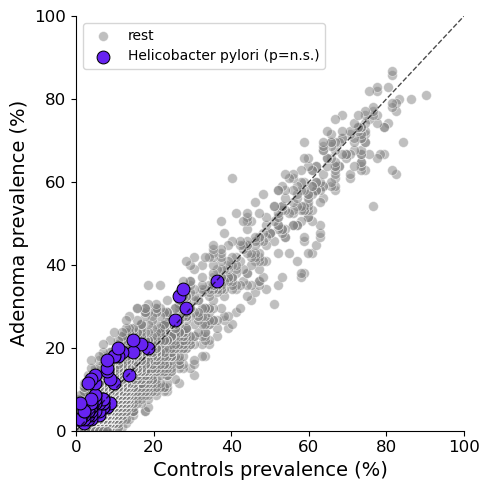

('Controls', 'CRC'): using x='% Controls', y='% CRC'


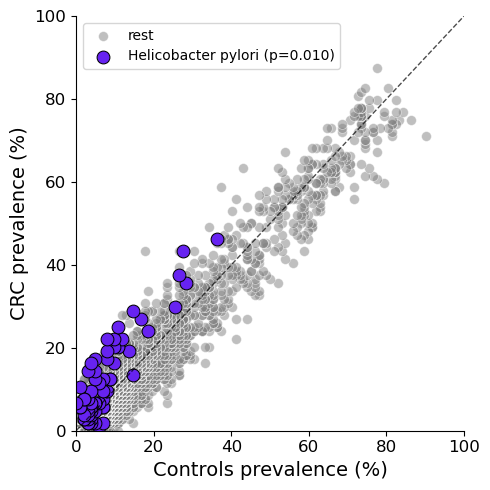

('Adenoma', 'CRC'): using x='% Adenoma', y='% CRC'


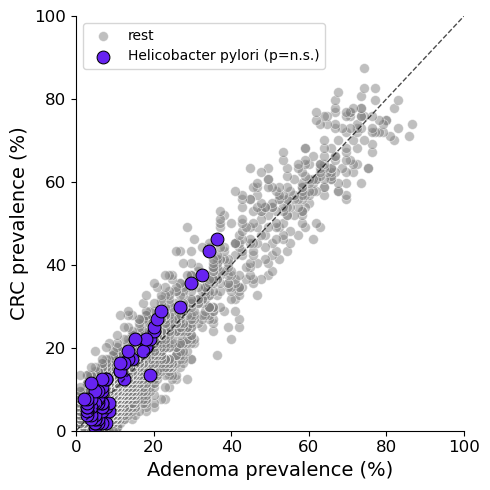

In [104]:
scatterplot_on_taxon(
    taxon="Helicobacter pylori",
    variable="species",
    dict_summary=dict_summary,
    dict_pair_groups_stats=dict_pairs_summary_selected,
    color="#6723F1",
    save_path=os.path.join(
        PATH_OUTPUT,
        "Functional_categories_analysis"
    )
)

('Controls', 'Adenoma'): using x='% Controls', y='% Adenoma'


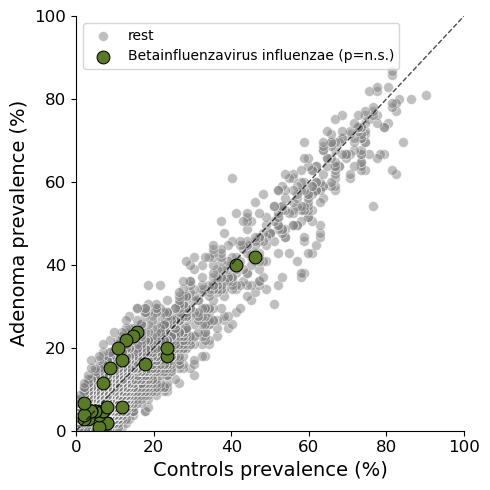

('Controls', 'CRC'): using x='% Controls', y='% CRC'


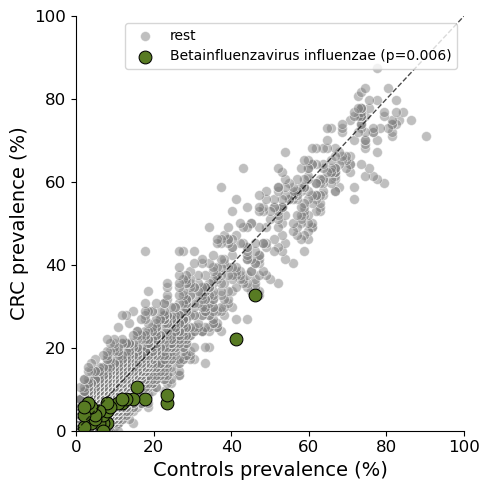

('Adenoma', 'CRC'): using x='% Adenoma', y='% CRC'


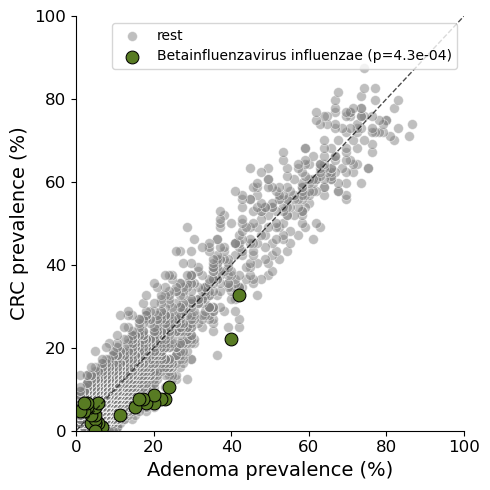

In [106]:
scatterplot_on_taxon(
    taxon="Betainfluenzavirus influenzae",
    variable="species",
    dict_summary=dict_summary,
    dict_pair_groups_stats=dict_pairs_summary_selected,
    color="#587B23",
    save_path=os.path.join(
        PATH_OUTPUT,
        "Functional_categories_analysis"
    )
)

## Run prevalence trend test

In [202]:

from scipy.stats import linregress, spearmanr, wilcoxon, binomtest


def plot_species_average_trend(
    prevalence_annot,
    species_name="Helicobacter pylori",
    species_col="species",
    group_cols=("Controls", "Adenoma", "CRC"),
    exact_match=True,
    plot_peptide_lines=True,
    plot_points=True,
    min_preval=1,
    figsize=(5,5),
    alias_species=None
):
    df = prevalence_annot.copy()

    palette = {
        'Controls': '#55A868',
        'Adenoma': '#4C72B0',
        'CRC': '#DD8452'
    }

    # Check columns
    required_cols = ["peptide_name", species_col] + list(group_cols)
    missing_cols = [c for c in required_cols if c not in df.columns]

    if missing_cols:
        raise ValueError(
            f"Missing columns: {missing_cols}\n"
            f"Available columns: {df.columns.tolist()}"
        )

    # Make prevalence columns numeric
    for col in group_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Subset feature/species
    if exact_match:
        df_species = df[df[species_col].eq(species_name)].copy()
    else:
        df_species = df[
            df[species_col].astype(str).str.contains(species_name, case=False, na=False)
        ].copy()

    print(f"Number of peptides for {species_name}: {df_species.shape[0]}")

    df_species = df_species.dropna(subset=list(group_cols))
    if min_preval is not None:
        df_species = df_species[(df_species[group_cols[0]] >= min_preval) |
                    (df_species[group_cols[1]] >= min_preval) |
                    (df_species[group_cols[2]] >= min_preval)]
        
    # Peptide-wise slopes
    stages = np.arange(len(group_cols))

    slopes = []

    for _, row in df_species.iterrows():
        y = row[list(group_cols)].astype(float).values

        if np.any(pd.isna(y)):
            continue

        slope, intercept, r, p, se = linregress(stages, y)

        slopes.append({
            "peptide_name": row["peptide_name"],
            "slope": slope,
            "Controls": y[0],
            "Adenoma": y[1],
            "CRC": y[2]
        })

    slope_df = pd.DataFrame(slopes)

    # Wilcoxon signed-rank test
    # alternative="greater" tests increasing trend
    if len(slope_df) > 0 and (slope_df["slope"] != 0).any():
        wilcox_res = wilcoxon(
            slope_df["slope"],
            alternative="greater"
        )
        wilcox_p = wilcox_res.pvalue
    else:
        wilcox_p = np.nan

    # Avoid duplicated id_vars
    id_vars = ["peptide_name"]
    if species_col not in id_vars:
        id_vars.append(species_col)
    if "species" in df_species.columns and "species" not in id_vars:
        id_vars.append("species")
    if "Description" in df_species.columns and "Description" not in id_vars:
        id_vars.append("Description")

    # Long format
    df_long = df_species.melt(
        id_vars=id_vars,
        value_vars=list(group_cols),
        var_name="Group",
        value_name="Prevalence"
    )

    df_long["Group"] = pd.Categorical(
        df_long["Group"],
        categories=list(group_cols),
        ordered=True
    )

    # Average curve
    avg_curve = (
        df_long
        .groupby("Group", as_index=False)
        .agg(
            mean_prevalence=("Prevalence", "mean"),
            median_prevalence=("Prevalence", "median"),
            sem_prevalence=("Prevalence", "sem"),
            n_peptides=("peptide_name", "nunique")
        )
    )

    avg_curve["Stage"] = range(len(avg_curve))

    # Descriptive trend stats
    slope, intercept, r, p_lm, se = linregress(
        avg_curve["Stage"],
        avg_curve["mean_prevalence"]
    )

    rho, _ = spearmanr(
        avg_curve["Stage"],
        avg_curve["mean_prevalence"]
    )

    print("Average prevalence curve:")
    display(avg_curve)

    print(f"Linear slope on group means: {slope:.4f}")
    print(f"Spearman rho on group means: {rho:.4f}")
    print("Note: p-values on only 3 group means are not really interpretable.")

    # Plot
    fig, ax = plt.subplots(figsize=figsize)

    # Boxplots
    sns.boxplot(
        data=df_long,
        x="Group",
        y="Prevalence",
        order=list(group_cols),
        palette=palette,
        showfliers=False,
        width=0.6,
        ax=ax
    );

    # Optional raw points
    if plot_points:
        sns.stripplot(
            data=df_long,
            x="Group",
            y="Prevalence",
            order=list(group_cols),
            color="black",
            alpha=0.35,
            size=4,
            jitter=0.18,
            ax=ax
        );

    # Optional peptide trajectories
    if plot_peptide_lines:
        peptide_wide = df_long.pivot_table(
            index="peptide_name",
            columns="Group",
            values="Prevalence"
        )

        x_positions = np.arange(len(group_cols))
        for _, row in peptide_wide.iterrows():
            y = row.reindex(group_cols).values.astype(float)
            ax.plot(
                x_positions,
                y,
                color="gray",
                alpha=0.15,
                linewidth=0.8
            );

    # Mean trend line
    ax.plot(
        np.arange(len(group_cols)),
        avg_curve["mean_prevalence"].values,
        marker="o",
        linewidth=2.5,
        color="black",
        label="Mean prevalence"
    );

    if not np.isnan(wilcox_p):
        ax.text(
            0.02,
            0.98,
            f"Wilcoxon trend test\np = {wilcox_p:.3g}",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=12,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
        );

    ax.set_xlabel("")
    ax.set_ylabel("Peptide prevalence")
    if alias_species is not None:
        ax.set_title(f" Prevalence trend {alias_species}", fontsize=16)
    else:
        ax.set_title(f" Prevalence trend {species_name}", fontsize=16)
     
    ax.set_xlabel(ax.get_xlabel(), fontsize=14)
    ax.set_ylabel(ax.get_ylabel(), fontsize=14)
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)

    ax.legend(loc='upper right', fontsize=12, frameon=False)
    plt.tight_layout()
    plt.show()

    return df_species, df_long, avg_curve

Number of peptides for Helicobacter pylori: 326
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:113: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



,Group,mean_prevalence,median_prevalence,sem_prevalence,n_peptides,Stage
0,Controls,5.310458,2.941176,0.623922,108,0
1,Adenoma,7.142857,4.761905,0.742029,108,1
2,CRC,8.520299,4.807692,0.913358,108,2


Linear slope on group means: 1.6049
Spearman rho on group means: 1.0000
Note: p-values on only 3 group means are not really interpretable.


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:147: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:174: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:222: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:223: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



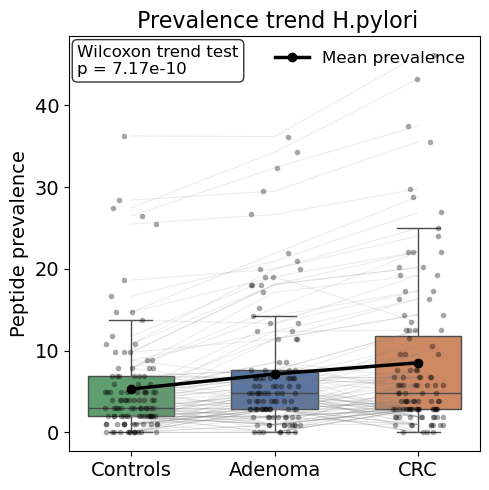

Number of peptides for Subdoligranulum: 395
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vec

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:113: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



,Group,mean_prevalence,median_prevalence,sem_prevalence,n_peptides,Stage
0,Controls,2.576379,1.960784,0.408825,43,0
1,Adenoma,3.898117,2.857143,0.568551,43,1
2,CRC,3.152952,2.884615,0.469538,43,2


Linear slope on group means: 0.2883
Spearman rho on group means: 0.5000
Note: p-values on only 3 group means are not really interpretable.


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:147: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:174: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:222: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:223: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



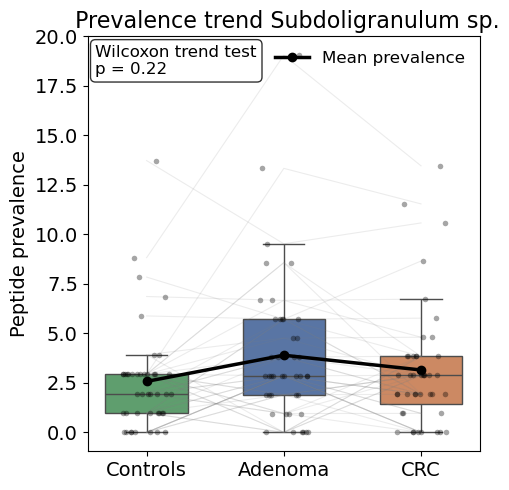

Number of peptides for Betainfluenzavirus influenzae: 149
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:113: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


,Group,mean_prevalence,median_prevalence,sem_prevalence,n_peptides,Stage
0,Controls,6.711916,2.941176,1.308866,52,0
1,Adenoma,7.912088,4.761905,1.278753,52,1
2,CRC,4.252959,2.884615,0.766828,52,2


Linear slope on group means: -1.2295
Spearman rho on group means: -0.5000
Note: p-values on only 3 group means are not really interpretable.


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:147: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:174: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:222: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:223: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



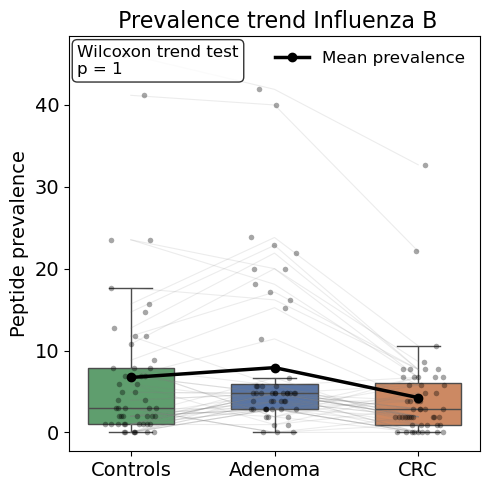

Number of peptides for Phocaeicola massiliensis: 973
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Adv

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:113: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



,Group,mean_prevalence,median_prevalence,sem_prevalence,n_peptides,Stage
0,Controls,3.825921,2.941176,0.645039,82,0
1,Adenoma,3.554007,2.380952,0.583135,82,1
2,CRC,3.646811,2.884615,0.619545,82,2


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:147: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




Linear slope on group means: -0.0896
Spearman rho on group means: -0.5000
Note: p-values on only 3 group means are not really interpretable.


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:174: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:222: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:223: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



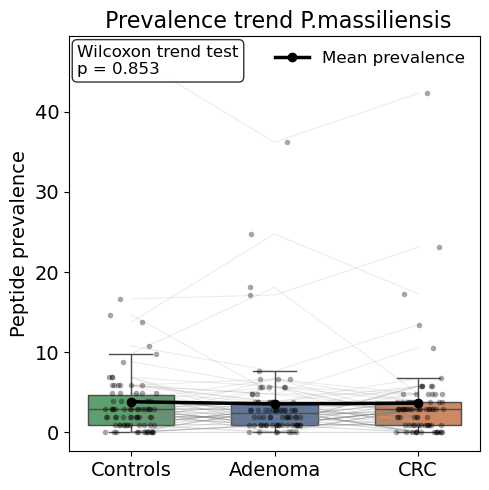

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:113: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



Number of peptides for beta: 644
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensi

,Group,mean_prevalence,median_prevalence,sem_prevalence,n_peptides,Stage
0,Controls,16.228784,6.862745,1.307861,253,0
1,Adenoma,15.908150,5.714286,1.267794,253,1
2,CRC,17.091061,5.769231,1.391384,253,2


Linear slope on group means: 0.4311
Spearman rho on group means: 0.5000
Note: p-values on only 3 group means are not really interpretable.


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:147: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:174: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:222: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4182138026.py:223: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



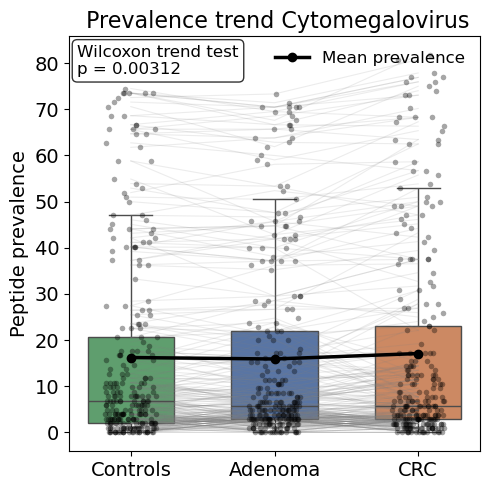

,peptide_name,species,Description
0,agilent_0,NaN,NaN
1,agilent_1,Homo sapiens,Chromodomain-helicase-DNA-binding protein 7
2,agilent_2,Mycobacterium tuberculosis,Uncharacterized MFS-type transporter Rv2994
3,agilent_3,Mycobacterium tuberculosis,Possible conserved membrane protein
4,agilent_4,Orthoflavivirus japonicum,Genome polyprotein
...,...,...,...
357187,corona2_13187,NaN,NaN
357188,corona2_13188,NaN,NaN
357189,corona2_13189,NaN,NaN
357190,corona2_13190,NaN,NaN


In [203]:
annotation_df = pd.concat(
    [
        df_agilent[["peptide_name", "species", "Description"]],
        df_twist[["peptide_name", "species", "Description"]],
        df_corona2[["peptide_name", "species", "Description"]],
    ],
    axis=0,
    ignore_index=True
)

annotation_df = annotation_df.drop_duplicates(subset="peptide_name")

prevalence_annot = pd.merge(
    sampleset.df_prevalences,
    annotation_df,
    how="left",
    on="peptide_name"
)
prevalence_annot.columns
from scipy.stats import linregress, spearmanr
prevalence_annot

df_hpylori, df_hpylori_long, hpylori_curve = plot_species_average_trend(
    prevalence_annot,
    species_name="Helicobacter pylori",
    species_col="species",
    group_cols=("Controls", "Adenoma", "CRC"),
    exact_match=True,
    min_preval=2,
    alias_species="H.pylori"
)

df_subdoligran, df_subdoligran_long, subdoligranul_curve = plot_species_average_trend(
    prevalence_annot,
    species_name="Subdoligranulum",
    species_col="species",
    group_cols=("Controls", "Adenoma", "CRC"),
    exact_match=False,
    min_preval=2,
    alias_species="Subdoligranulum sp."
)

df_betainfluenzavirus, df_betainfluenzavirus_long, betainfluenzavirus_curve = plot_species_average_trend(
    prevalence_annot,
    species_name="Betainfluenzavirus influenzae",
    species_col="species",
    group_cols=("Controls", "Adenoma", "CRC"),
    exact_match=True,
    min_preval=2,
    alias_species = "Influenza B"
)

df_phocaeicola, df_phocaeicola_long, phocaeicola_curve = plot_species_average_trend(
    prevalence_annot,
    species_name="Phocaeicola massiliensis",
    species_col="species",
    group_cols=("Controls", "Adenoma", "CRC"),
    exact_match=True,
    min_preval=2,
    alias_species = "P.massiliensis"
)

df_SARS, df_SARS_long, SARS_curve = plot_species_average_trend(
    prevalence_annot,
    species_name="beta",
    species_col="species",
    group_cols=("Controls", "Adenoma", "CRC"),
    exact_match=False,
    min_preval=2,
    alias_species = "Cytomegalovirus"
)

# df_hpylori, df_hpylori_long, hpylori_curve = plot_species_average_trend(
#     prevalence_annot,
#     species_name="cagY",
#     species_col="Description",
#     group_cols=("Controls", "Adenoma", "CRC"),
#     exact_match=False,
#     min_preval=1
# )

# # prevalence_annot[prevalence_annot['Description'].str.contains('cag', na=False, case=False)]

annotation_df

In [206]:
# Reorder columns
sampleset_bin = sampleset.sampleset_bin.reset_index()
sampleset_bin = sampleset_bin.merge(sampleset.libraries[0][['peptide_name', 'Description','is_IEDB_or_cntrl','is_auto','is_infect','is_EBV','is_toxin','is_PNP','is_EM','is_MPA','is_patho','is_probio','is_IgA','is_flagellum','signalp6_slow','is_topgraph_new','domain','kingdom','phylum','class','order','family','genus','species','common']], on='peptide_name', how='left')
sampleset_bin = sampleset_bin.merge(sampleset.libraries[1][['peptide_name', 'Description', 'is_phage','is_allergens','is_influenza', 'domain','kingdom','phylum','class','order','family','genus','species','common']], on=['peptide_name', 'Description', 'domain','kingdom','phylum','class','order','family','genus','species','common'], how='left')
sampleset_bin = sampleset_bin.merge(sampleset.libraries[2][['peptide_name', 'Description', 'domain','kingdom','phylum','class','order','family','genus','species','common']], on=['peptide_name', 'Description', 'domain','kingdom','phylum','class','order','family','genus','species','common'], how='left')
sampleset_bin

,peptide_name,R02P01_01_CORSAp1_6308_A_T_C2,R02P01_09_CORSAp1_6762_A_T_C2,R02P01_17_CORSAp1_2562_A_T_C2,R02P01_25_CORSAp1_6831_A_T_C2,R02P01_33_CORSAp1_2898_A_T_C2,R02P01_41_CORSAp1_4556_A_T_C2,R02P01_49_CORSAp1_4924_A_T_C2,R02P01_57_CORSAp1_4609_A_T_C2,R02P01_65_CORSAp1_6240_A_T_C2,...,phylum,class,order,family,genus,species,common,is_phage,is_allergens,is_influenza
0,agilent_128796,0,0,0,0,0,0,0,0,0,...,Bacillota,Clostridia,Lachnospirales,Lachnospiraceae,Blautia,Blautia producta,NaN,NaN,NaN,NaN
1,agilent_115227,0,0,0,0,0,0,0,0,0,...,Bacteroidota,Bacteroidia,Bacteroidales,Barnesiellaceae,Barnesiella,Barnesiella intestinihominis,NaN,NaN,NaN,NaN
2,twist_59654,0,0,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,twist_91409,0,0,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,agilent_39364,0,0,0,0,0,0,0,0,0,...,Pseudomonadota,Gammaproteobacteria,Vibrionales,Vibrionaceae,Vibrio,Vibrio vulnificus,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89413,agilent_236841,0,0,0,0,0,0,0,0,0,...,Pseudomonadota,Betaproteobacteria,Burkholderiales,Burkholderiaceae,Burkholderia,Burkholderia sp. ABCPW 14,NaN,NaN,NaN,NaN
89414,agilent_156108,0,0,0,0,0,0,0,0,0,...,Bacteroidota,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,NaN,NaN,NaN,NaN,NaN
89415,agilent_159161,0,0,0,0,0,0,0,0,0,...,Bacillota,Bacilli,Lactobacillales,Lactobacillaceae,Lactobacillus,Lactobacillus acidophilus,NaN,NaN,NaN,NaN
89416,agilent_147357,0,0,0,0,0,0,0,0,0,...,Bacillota,Clostridia,Lachnospirales,Lachnospiraceae,Roseburia,Roseburia inulinivorans,NaN,NaN,NaN,NaN


In [207]:
meta_cols = [
    'Description', 'domain', 'kingdom', 'phylum', 'class', 'order',
    'family', 'genus', 'species', 'common'
]

lib0_extra = [
    'is_IEDB_or_cntrl', 'is_auto', 'is_infect', 'is_EBV', 'is_toxin',
    'is_PNP', 'is_EM', 'is_MPA', 'is_patho', 'is_probio', 'is_IgA',
    'is_flagellum', 'signalp6_slow', 'is_topgraph_new'
]

lib1_extra = ['is_phage', 'is_allergens', 'is_influenza']

all_annotation_cols = meta_cols + lib0_extra + lib1_extra

# start from sampleset_bin but remove old annotation columns if present
df = sampleset_bin.drop(
    columns=[c for c in all_annotation_cols if c in sampleset_bin.columns],
    errors='ignore'
).copy()

# merge lib0 first
df = df.merge(
    sampleset.libraries[0][['peptide_name'] + meta_cols + lib0_extra].drop_duplicates('peptide_name'),
    on='peptide_name',
    how='left'
)

# merge lib1
df = df.merge(
    sampleset.libraries[1][['peptide_name'] + meta_cols + lib1_extra].drop_duplicates('peptide_name'),
    on='peptide_name',
    how='left',
    suffixes=('', '_lib1')
)

# merge lib2
df = df.merge(
    sampleset.libraries[2][['peptide_name'] + meta_cols].drop_duplicates('peptide_name'),
    on='peptide_name',
    how='left',
    suffixes=('', '_lib2')
)

# fill missing metadata from lib1/lib2
for col in meta_cols:
    if f'{col}_lib1' in df.columns:
        df[col] = df[col].combine_first(df[f'{col}_lib1'])
    if f'{col}_lib2' in df.columns:
        df[col] = df[col].combine_first(df[f'{col}_lib2'])

# drop helper columns
df = df.drop(columns=[c for c in df.columns if c.endswith('_lib1') or c.endswith('_lib2')])


In [208]:
# Transform peptides presence absence matrix in long form
# sampleset_bin = sampleset_bin_more_than_5
sampleset_bin = sampleset.sampleset_bin

sampleset_bin_long = sampleset_bin.reset_index().melt(
    id_vars='peptide_name', 
    var_name='SampleName', 
    value_name='enriched'
)

# Merge to the relevant metadata
sampleset_bin_long_agilent = sampleset_bin_long[sampleset_bin_long['peptide_name'].str.contains('agilent')].merge(sampleset.libraries[0][['peptide_name', 'Description', 'species']], on='peptide_name', how='left')
sampleset_bin_long_twist = sampleset_bin_long[sampleset_bin_long['peptide_name'].str.contains('twist')].merge(sampleset.libraries[1][['peptide_name', 'Description', 'species']], how='left')
sampleset_bin_long_corona2 = sampleset_bin_long[sampleset_bin_long['peptide_name'].str.contains('corona')].merge(sampleset.libraries[2][['peptide_name', 'Description', 'species']], how='left')
sampleset_bin_long = pd.concat([sampleset_bin_long_agilent, sampleset_bin_long_twist, sampleset_bin_long_corona2])

# Calculate the protein breadth response based on Protein-specific annotation and species
protein_breath = [sampleset.libraries[0][['peptide_name', 'Description', 'species']].groupby(['Description', 'species']).size().reset_index(name='count'),
                  sampleset.libraries[1][['peptide_name', 'Description', 'species']].groupby(['Description', 'species']).size().reset_index(name='count'),
                  sampleset.libraries[2][['peptide_name', 'Description', 'species']].groupby(['Description', 'species']).size().reset_index(name='count')
                  ]
# print(protein_breath[protein_breath['species'].str.conatins('Betainf')])
merged_breath_libs = pd.concat(protein_breath)
merged_breath_libs[merged_breath_libs['species'].str.contains('Betainf')]
# Groupby again in case some annotations overlap
merged_breath_libs = merged_breath_libs.groupby(['Description', 'species']).sum().reset_index()
# Merge with long format df
sampleset_bin_long_breath = pd.merge(sampleset_bin_long, 
                                     merged_breath_libs, 
                                     on=['Description', 'species'], 
                                     how='left')
sampleset_bin_long_breath[sampleset_bin_long_breath['species'].str.contains('Betainf', na=False)]
# Compute protein scores
protein_scores = (
    sampleset_bin_long_breath
    .groupby(['SampleName', 'Description', 'species', 'count'], as_index=False)
    .agg(enriched_peptides=('enriched', 'sum'))
)
# protein_scores
protein_scores['protein_coverage_score'] = (
    protein_scores['enriched_peptides'] / protein_scores['count']
)

protein_scores = protein_scores.merge(
    sampleset.sample_sheet[['SampleName', 'group_test']],
    on='SampleName',
    how='left'
)
protein_scores[protein_scores['species'].str.contains('Betainf', na=False)]
# # Derive the species scores out of the protein scores
# # species_scores = (
# #     protein_scores
# #     .groupby(['SampleName', 'Description', 'species', 'group_test'], as_index=False)
# #     .agg(mean_protein_coverage=('protein_coverage_score', 'mean'),
# #          count=('count', 'sum'))
# # )
species_scores = (
    protein_scores
    .groupby(['SampleName', 'species', 'group_test'], as_index=False)
    .agg(
        mean_protein_coverage=('protein_coverage_score', 'mean'),
        sum_protein_coverage=('protein_coverage_score', 'sum'),
        n_proteins=('Description', 'nunique'),
        total_peptide_count_per_species=('count', 'sum'),
        total_enriched_peptides=('enriched_peptides', 'sum')
    )
)

# ------ Double filtering -------
# A. Filter by total enriched peptides per species
# Sum enriched peptides across all samples
species_total_enriched = species_scores.groupby('species')['total_enriched_peptides'].sum().reset_index()
# Keep only species with enough signal
species_to_keep = species_total_enriched[species_total_enriched['total_enriched_peptides'] >= 5]['species']

species_scores_filtered = species_scores[species_scores['species'].isin(species_to_keep)]
species_total_enriched[species_total_enriched['species'].str.contains('Betainf')]
# B. Filter by number of samples with non-zero enrichment x > 5
species_nonzero = (
    species_scores_filtered.groupby('species')['total_enriched_peptides']
    .apply(lambda x: (x > 5).sum())
    .reset_index(name='n_nonzero_samples')
)
# Get peptides which appear in at least 20 samples
species_to_keep = species_nonzero[species_nonzero['n_nonzero_samples'] >= 20]['species']
species_scores_filtered = species_scores[species_scores['species'].isin(species_to_keep)]
species_scores = species_scores_filtered

# from scipy.stats import mannwhitneyu
# pairs = [
#     ('Controls', 'Adenoma'),
#     ('Adenoma', 'CRC'),
#     ('Controls', 'CRC')
# ]

# results = []

# for species in species_scores['species'].unique():    
#     subdf = species_scores[
#         (species_scores['species'] == species) &
#         (species_scores['mean_protein_coverage'] > 0)
#     ]
#     subdf = subdf[subdf['mean_protein_coverage'] > 0]
    
#     for g1, g2 in pairs:
        
#         data1 = subdf[subdf['group_test'] == g1]['mean_protein_coverage']
#         data2 = subdf[subdf['group_test'] == g2]['mean_protein_coverage']
        
#         # skip if empty
#         if len(data1) == 0 or len(data2) == 0:
#             continue
        
#         stat, pval = mannwhitneyu(data1, data2, alternative='two-sided')
        
#         results.append({
#             'species': species,
#             'group1': g1,
#             'group2': g2,
#             'pvalue': pval
#         })

# df_pairwise_mw = pd.DataFrame(results).sort_values(by='pvalue')
# # Correct usin BH
# df_pairwise_mw['p_adj'] = multipletests(
#     df_pairwise_mw['pvalue'],
#     method='fdr_bh'
# )[1]

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


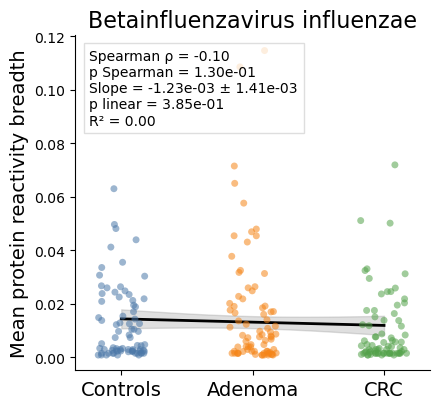

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


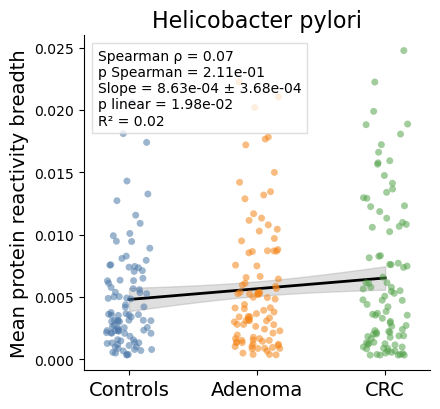

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


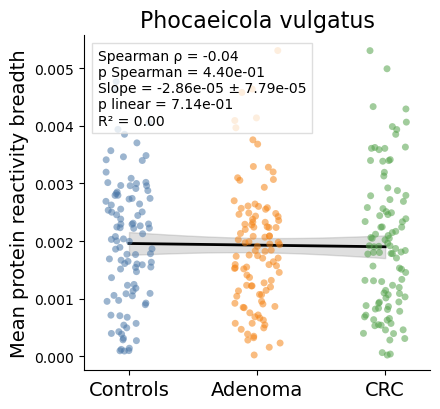

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


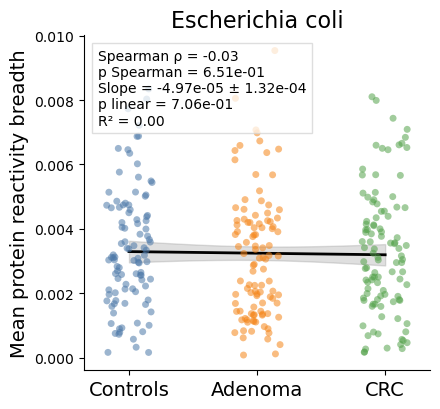

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


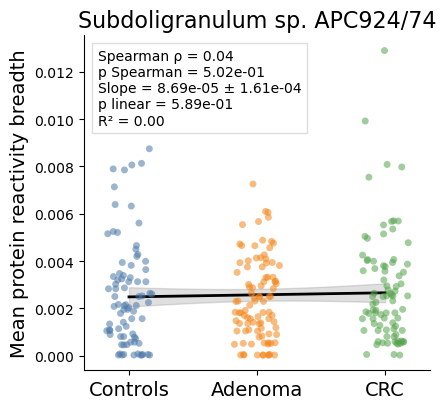

In [209]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

# Create output directory
output_dir = os.path.join(PATH_OUTPUT, "Mean_bredth_score")
os.makedirs(output_dir, exist_ok=True)

# Map groups to numeric values
group_order = {'Controls': 0, 'Adenoma': 1, 'CRC': 2}
order = ['Controls', 'Adenoma', 'CRC']
colors = ["#4C78A8", "#F58518", "#54A24B"]

species_to_check = [
    'Betainfluenzavirus influenzae',
    'Helicobacter pylori',
    'Phocaeicola vulgatus',
    'Escherichia coli',
    'Subdoligranulum sp. APC924/74'
]

results = []

for species in species_to_check:

    subdf = species_scores[
        (species_scores['species'] == species) &
        (species_scores['mean_protein_coverage'] > 0)
    ].copy()

    if len(subdf) < 3:
        continue

    subdf['group_num'] = subdf['group_test'].map(group_order)
    subdf = subdf.dropna(subset=['group_num', 'mean_protein_coverage'])
    subdf['group_num'] = subdf['group_num'].astype(float)

    if subdf['group_num'].nunique() < 2:
        continue

    # Spearman
    rho, p_spear = spearmanr(
        subdf['group_num'],
        subdf['mean_protein_coverage']
    )

    # Linear regression
    X = sm.add_constant(subdf['group_num'])
    y = subdf['mean_protein_coverage']
    model = sm.OLS(y, X).fit()

    slope = model.params['group_num']
    slope_se = model.bse['group_num']
    p_lm = model.pvalues['group_num']
    r2 = model.rsquared

    results.append({
        'species': species,
        'rho': rho,
        'p_spearman': p_spear,
        'slope': slope,
        'slope_se': slope_se,
        'p_linear': p_lm,
        'r_squared': r2,
        'n_samples': len(subdf)
    })

    # Prediction line + CI
    x_pred = np.linspace(0, 2, 100)
    X_pred = sm.add_constant(x_pred)
    pred = model.get_prediction(X_pred)
    pred_mean = pred.predicted_mean
    pred_ci = pred.conf_int(alpha=0.05)

    fig, ax = plt.subplots(figsize=(4.5, 4.2))

    # points
    sns.stripplot(
        data=subdf,
        x='group_num',
        y='mean_protein_coverage',
        hue='group_test',
        hue_order=order,
        palette=colors,
        jitter=0.18,
        alpha=0.55,
        size=5,
        ax=ax,
        legend=False
    )

    # regression line
    ax.plot(
        x_pred,
        pred_mean,
        color='black',
        linewidth=2,
        label='Linear fit'
    )

    # 95% confidence interval
    ax.fill_between(
        x_pred,
        pred_ci[:, 0],
        pred_ci[:, 1],
        color='grey',
        alpha=0.25,
        label='95% CI'
    )

    ax.text(
        0.04, 0.96,
        (
            f"Spearman ρ = {rho:.2f}\n"
            f"p Spearman = {p_spear:.2e}\n"
            f"Slope = {slope:.2e} ± {slope_se:.2e}\n"
            f"p linear = {p_lm:.2e}\n"
            f"R² = {r2:.2f}"
        ),
        ha='left',
        va='top',
        transform=ax.transAxes,
        fontsize=10,
        bbox=dict(facecolor='white', alpha=0.75, edgecolor='lightgrey')
    )

    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(order, fontsize=14)
    ax.set_title(species, fontsize=16)
    ax.set_xlim(-0.35, 2.35)
    ax.set_ylabel('Mean protein reactivity breadth', fontsize=14)
    ax.set_xlabel('')

    sns.despine()
    plt.tight_layout()

    # Safe filename
    safe_species = re.sub(r'[^A-Za-z0-9._-]+', '_', species)
    out_file = os.path.join(output_dir, f"{safe_species}.svg")

    fig.savefig(out_file, format="svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)

df_results = pd.DataFrame(results)

## Run now mapping of epitopes on the entire proteins

## Correlate shap values to delta on peptide level

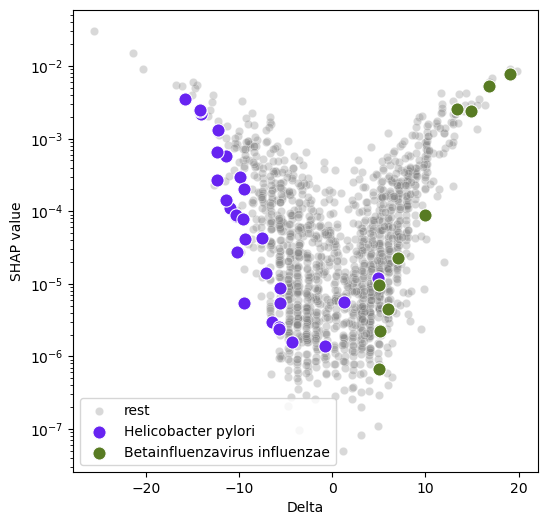

In [113]:
shap_values_table = pd.read_csv('/Users/gabrielinnocenti/Downloads/Table_shap_Controls-CRC_CORSA_nestedCV_with_oligos.csv')

shap_delta_merged = dict_pairs_summary_selected[('Controls', 'CRC')][['peptide_name', 'species', 'Delta']].merge(shap_values_table, left_on='peptide_name',
                                                                                             right_on='Peptide ID')
# shap_delta_merged['-log(SHAP_value)'] = shap_delta_merged['SHAP value'].apply(lambda x: np.log(x))
plt.figure(figsize=(6,6))
sns.scatterplot(data=shap_delta_merged[(shap_delta_merged['species'] != 'Helicobacter pylori') &
                                       (shap_delta_merged['species'] != 'Betainfluenzavirus influenzae')],
                x='Delta',
                y='SHAP value',
                color='grey', alpha=.3, label='rest')

plt.yscale('log')


sns.scatterplot(data=shap_delta_merged[shap_delta_merged['species'] == 'Helicobacter pylori'],
                x='Delta',
                y='SHAP value',
                color="#6723F1", label='Helicobacter pylori', s=90)
plt.yscale('log')


sns.scatterplot(data=shap_delta_merged[shap_delta_merged['species'] == 'Betainfluenzavirus influenzae'],
                x='Delta',
                y='SHAP value',
                color="#587B23", label='Betainfluenzavirus influenzae', s=90)
plt.yscale('log')

plt.legend(loc='lower left')

In [197]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors


def lighten_color(color, amount=0.55):
    """
    Lighten a matplotlib-compatible color.
    amount closer to 1 = lighter.
    """
    try:
        c = mcolors.cnames[color]
    except KeyError:
        c = color

    c = np.array(mcolors.to_rgb(c))
    white = np.array([1, 1, 1])

    return tuple(c + (white - c) * amount)


def plot_shap_violin_for_species(
    df,
    species_to_plot,
    species_col="species",
    shap_col="SHAP value",
    description_col="Description",
    threshold=None,
    eps=1e-8,
    species_name_display=None,
    species_color=None,
    rest_color="lightgrey",
    protein=None,
    protein_label=None,
    protein_exact_match=False,
    use_full_description_as_label=False,
    figsize=(6, 3),
    stripplot=True,
    strip_color="black",
    strip_alpha=0.25,
    strip_size=2.5,
    title=None,
    save_path=None
):
    """
    Create a violin plot of log10(SHAP value).

    If protein is None:
        Groups are:
            selected species SHAP >= threshold
            selected species SHAP < threshold
            rest

    If protein is provided as a string:
        Groups are:
            selected protein peptides from selected species
            rest peptides from selected species
            rest

    If protein is provided as a list:
        Groups are:
            selected peptides matching any protein term from selected species
            rest peptides from selected species
            rest

    Example:
        protein=["CagA", "CagY"]

        Groups:
            CagA / CagY
            rest peptides H. pylori
            rest
    """

    plot_df = df.copy()

    # -----------------------------
    # Defaults
    # -----------------------------

    default_display_names = {
        "Helicobacter pylori": "H. pylori",
        "Betainfluenzavirus influenzae": "Influenza B virus"
    }

    default_colors = {
        "Helicobacter pylori": "#6723F1",
        "Betainfluenzavirus influenzae": "#587B23"
    }

    if species_name_display is None:
        species_name_display = default_display_names.get(
            species_to_plot,
            species_to_plot
        )

    if species_color is None:
        species_color = default_colors.get(
            species_to_plot,
            "#6723F1"
        )

    species_rest_color = lighten_color(species_color, amount=0.55)

    # -----------------------------
    # Checks
    # -----------------------------

    required_cols = [species_col, shap_col]

    if protein is not None:
        required_cols.append(description_col)

    missing_cols = [c for c in required_cols if c not in plot_df.columns]

    if missing_cols:
        raise ValueError(f"Missing columns: {missing_cols}")

    # -----------------------------
    # Create grouping
    # -----------------------------

    is_species = plot_df[species_col] == species_to_plot

    if protein is None:
        high_label = f"{species_name_display}\nSHAP >= 10-3"
        low_label = f"{species_name_display}\nSHAP < 10-3"
        rest_label = "rest"

        plot_df["group_shap"] = np.select(
            [
                is_species & (plot_df[shap_col] >= threshold),
                is_species & (plot_df[shap_col] < threshold)
            ],
            [
                high_label,
                low_label
            ],
            default=rest_label
        )

        order = [
            high_label,
            low_label,
            rest_label
        ]

        box_palette = {
            high_label: species_color,
            low_label: species_color,
            rest_label: rest_color
        }

        protein_display_label = None

    else:
        # Allow protein to be either a string or a list/tuple/set
        if isinstance(protein, (list, tuple, set)):
            protein_terms = [str(x) for x in protein]
        else:
            protein_terms = [str(protein)]

        description_series = plot_df[description_col].astype(str)

        if protein_exact_match:
            is_protein = description_series.isin(protein_terms)
        else:
            is_protein = np.zeros(len(plot_df), dtype=bool)

            for term in protein_terms:
                is_protein = is_protein | description_series.str.contains(
                    term,
                    case=False,
                    na=False,
                    regex=False
                ).values

        is_protein = np.asarray(is_protein, dtype=bool)

        is_species_protein = is_species & is_protein
        is_species_not_protein = is_species & ~is_protein

        if protein_label is not None:
            protein_display_label = protein_label

        elif use_full_description_as_label and len(protein_terms) == 1:
            matched_descriptions = (
                plot_df.loc[is_species_protein, description_col]
                .dropna()
                .astype(str)
                .unique()
            )

            if len(matched_descriptions) == 1:
                protein_display_label = matched_descriptions[0]
            else:
                protein_display_label = protein_terms[0]

        else:
            protein_display_label = " / ".join(protein_terms)

        protein_group_label = protein_display_label
        species_rest_label = f"rest peptides\n{species_name_display}"
        rest_label = "rest"

        plot_df["group_shap"] = np.select(
            [
                is_species_protein,
                is_species_not_protein
            ],
            [
                protein_group_label,
                species_rest_label
            ],
            default=rest_label
        )

        order = [
            protein_group_label,
            species_rest_label,
            rest_label
        ]

        box_palette = {
            protein_group_label: species_color,
            species_rest_label: species_rest_color,
            rest_label: rest_color
        }

        print(f"Protein terms used: {protein_terms}")
        print(f"Matched selected-species protein peptides: {is_species_protein.sum()}")
        print(f"Rest selected-species peptides: {is_species_not_protein.sum()}")

    # -----------------------------
    # Remove zero/negative values for log10
    # -----------------------------

    plot_df = plot_df[plot_df[shap_col] >= eps].copy()

    if plot_df.empty:
        raise ValueError(
            f"No values >= eps={eps} available for plotting."
        )

    plot_df["log10_SHAP"] = np.log10(plot_df[shap_col])

    # Remove empty categories from order
    observed_groups = set(plot_df["group_shap"].dropna())
    order = [x for x in order if x in observed_groups]

    # -----------------------------
    # Plot
    # -----------------------------

    plt.figure(figsize=figsize)

    ax = sns.boxplot(
        data=plot_df,
        x="group_shap",
        y="log10_SHAP",
        order=order,
        palette=box_palette,
        width=0.6,
        showfliers=True,
        capwidths=0.10,
        # inner=inner,
        # cut=0,
        # bw_adjust=bw_adjust,
        linewidth=1
    )

    if stripplot:
        sns.stripplot(
            data=plot_df,
            x="group_shap",
            y="log10_SHAP",
            order=order,
            color=strip_color,
            alpha=strip_alpha,
            size=strip_size,
            jitter=True
        )
    if threshold is not None:
        ax.axhline(
            np.log10(threshold),
            linestyle="--",
            linewidth=1,
            color="black"
        )

    ax.set_xlabel("")
    ax.set_ylabel(r"$\log_{10}$(SHAP value)")

    if title is None:
        if protein is None:
            title = f"SHAP value distribution - {species_name_display}"
        else:
            title = (
                f"SHAP value distribution - "
                f"{species_name_display} / {protein_display_label}"
            )

    ax.set_title(title)

    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()

    if save_path is not None:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

    return plot_df

In [195]:
# plot_df_hpylori = plot_shap_violin_for_species(
#     df=shap_delta_merged,
#     species_to_plot="Helicobacter pylori",
#     species_name_display="H. pylori",
#     species_color="#6723F1",
#     figsize=(6, 3),
#     bw_adjust=0.9
# )

sampleset.dict_pair_groups_stats[('Controls', 'CRC')][sampleset.dict_pair_groups_stats[('Controls', 'CRC')]['species'] == 'Helicobacter pylori'][['peptide_name', 'species', 'Description']]
shap_delta_merged

# Subset containing the corrected H. pylori descriptions
hpylori_description_lookup = (
    sampleset.dict_pair_groups_stats[("Controls", "CRC")]
    .loc[
        sampleset.dict_pair_groups_stats[("Controls", "CRC")]["species"] == "Helicobacter pylori",
        ["peptide_name", "species", "Description"]
    ]
    .drop_duplicates(subset="peptide_name")
    .copy()
)

# Create mapping: peptide_name -> Description
description_map = hpylori_description_lookup.set_index("peptide_name")["Description"]

# Optional: keep original Description before replacement
shap_delta_merged["Description_original"] = shap_delta_merged["Description"]

# Map corrected descriptions onto shap_delta_merged
new_description = shap_delta_merged["peptide_name"].map(description_map)

# Replace only where a match was found
mask_matched = new_description.notna()

shap_delta_merged.loc[mask_matched, "Description"] = new_description.loc[mask_matched]

print(f"Updated {mask_matched.sum()} Description values.")

Updated 64 Description values.


Protein terms used: ['CagY']
Matched selected-species protein peptides: 14
Rest selected-species peptides: 50


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/2429527179.py:259: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




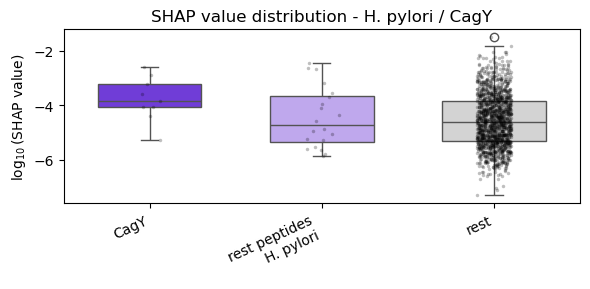

In [198]:
plot_df_cagY_cagA = plot_shap_violin_for_species(
    df=shap_delta_merged,
    species_to_plot="Helicobacter pylori",
    species_name_display="H. pylori",
    species_color="#6723F1",
    protein="CagY",
    description_col="Description",
    protein_label="CagY",
    protein_exact_match=False,
    figsize=(6, 3),
    threshold=None
)

# plot_df_cagA = plot_shap_violin_for_species(
#     df=shap_delta_merged,
#     species_to_plot="Helicobacter pylori",
#     species_name_display="H. pylori",
#     species_color="#6723F1",
#     protein="CagA",
#     description_col="Description",
#     protein_label="CagA",
#     protein_exact_match=False,
#     figsize=(6, 3),
#     bw_adjust=0.9
# )

Protein terms used: ['Hemagglutinin']
Matched selected-species protein peptides: 8
Rest selected-species peptides: 19


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/2429527179.py:259: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




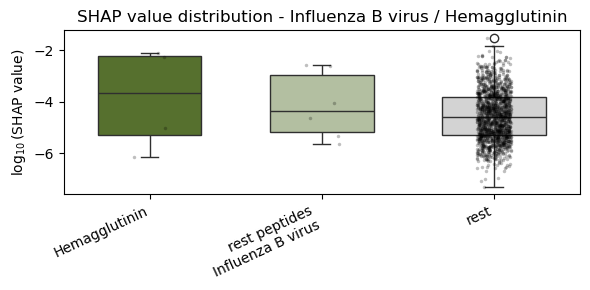

In [199]:
plot_df_cagy = plot_shap_violin_for_species(
    df=shap_delta_merged,
    species_to_plot="Betainfluenzavirus influenzae",
    species_name_display="Influenza B virus",
    species_color="#587B23",
    protein="Hemagglutinin",
    description_col="Description",
    protein_label="Hemagglutinin",
    protein_exact_match=False,
    figsize=(6, 3)
)

/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4108189739.py:147: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/var/folders/1f/kdrdfqkj39z0c2pd758bkw2r0000gn/T/ipykernel_23905/4108189739.py:147: FutureWarning:



The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.



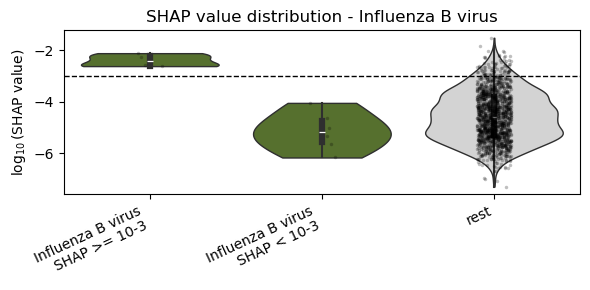

In [125]:
plot_df_influenza = plot_shap_violin_for_species(
    df=shap_delta_merged,
    species_to_plot="Betainfluenzavirus influenzae",
    species_name_display="Influenza B virus",
    species_color="#587B23",
    figsize=(6, 3),
    bw_adjust=0.9
)